TensorFlow version: 2.16.1
Loaded 2 CSV files: 65,303 total rows, 66 columns.

DATASET
Rows: 65303
Columns: 67
Unique CNN–BRNN sequences: 3059
Unique physical/source exposure events: 2054

Total CNN–BRNN sequences: 3059
N2 sequences: 2404
Ambient-air sequences: 655

Sequences by validation block:
validation_block
CORE_MANUSCRIPT_2160         699
AMBIENT_AIR_VALIDATION       655
LOW_CONC_1PPB_CALIBRATION    600
ENVIRONMENTAL_ROBUSTNESS     524
EXPOSURE_HISTORY_RESET       294
BTEX_MIXTURE                 287
Name: sequence_id, dtype: int64

LEAKAGE CHECK PASSED
Maximum number of partitions for any exposure event: 1

Sequence partition summary:
analysis_split             test  train  validation
validation_block                                  
AMBIENT_AIR_VALIDATION      110    446          99
BTEX_MIXTURE                 36    210          41
CORE_MANUSCRIPT_2160        101    495         103
ENVIRONMENTAL_ROBUSTNESS     84    360          80
EXPOSURE_HISTORY_RESET       37    219     

Model: "USM_IDS_Memory_CNN_BRNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ USM_input (InputLayer)        │ (None, 18, 8)             │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ reshape_time_receptor_feature │ (None, 18, 4, 2)          │               0 │ USM_input[0][0]            │
│ (Reshape)                     │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ spatial_CNN_1                 │ (None, 18, 4, 32)         │             160 │ reshape_time_receptor_fea… │
│ (TimeDistributed)             │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ spatial_BN_1                  │ (None, 18, 4, 32)         │             128 │ spatial_CNN_1[0][0]        │
│ (TimeDistributed)             │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ spatial_CNN_2                 │ (None, 18, 4, 64)         │           4,160 │ spatial_BN_1[0][0]         │
│ (TimeDistributed)             │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ spatial_receptor_pooling      │ (None, 18, 64)            │               0 │ spatial_CNN_2[0][0]        │
│ (TimeDistributed)             │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ spatial_dropout (Dropout)     │ (None, 18, 64)            │               0 │ spatial_receptor_pooling[… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ BRNN_1 (Bidirectional)        │ (None, 18, 128)           │          49,920 │ spatial_dropout[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ BRNN_dropout_1 (Dropout)      │ (None, 18, 128)           │               0 │ BRNN_1[0][0]               │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ BRNN_2 (Bidirectional)        │ (None, 18, 64)            │          31,104 │ BRNN_dropout_1[0][0]       │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ temporal_average_pooling      │ (None, 64)                │               0 │ BRNN_2[0][0]               │
│ (GlobalAveragePooling1D)      │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ temporal_max_pooling          │ (None, 64)                │               0 │ BRNN_2[0][0]               │
│ (GlobalMaxPooling1D)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ temporal_feature_fusion       │ (None, 128)               │               0 │ temporal_average_pooling[… │
│ (Concatenate)                 │                           │                 │ temporal_max_pooling[0][0] │
├───────────────────────────────┼───────────────────────────┼───────────────

 Total params: 110,630 (432.15 KB)

 Trainable params: 110,566 (431.90 KB)

 Non-trainable params: 64 (256.00 B)


TRAINING PRIMARY IDS + M(t) CNN–BRNN
Epoch 1/150
15/16 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.1881 - loss: 1.7743
Epoch 1: val_accuracy improved from None to 0.33981, saving model to CNN_BRNN_USM_VALIDATION_RESULTS\best_USM_IDS_Memory_CNN_BRNN.keras

Epoch 1: finished saving model to CNN_BRNN_USM_VALIDATION_RESULTS\best_USM_IDS_Memory_CNN_BRNN.keras
16/16 ━━━━━━━━━━━━━━━━━━━━ 35s 332ms/step - accuracy: 0.2444 - loss: 1.7519 - val_accuracy: 0.3398 - val_loss: 1.7101 - learning_rate: 2.0000e-04
Epoch 2/150
15/16 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.4120 - loss: 1.6722
Epoch 2: val_accuracy improved from 0.33981 to 0.46602, saving model to CNN_BRNN_USM_VALIDATION_RESULTS\best_USM_IDS_Memory_CNN_BRNN.keras

Epoch 2: finished saving model to CNN_BRNN_USM_VALIDATION_RESULTS\best_USM_IDS_Memory_CNN_BRNN.keras
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - accuracy: 0.4505 - loss: 1.6491 - val_accuracy: 0.4660 - val_loss: 1.5714 - learning_rate: 2.0000e-04
Epoch 3/150
16/16 ━━━

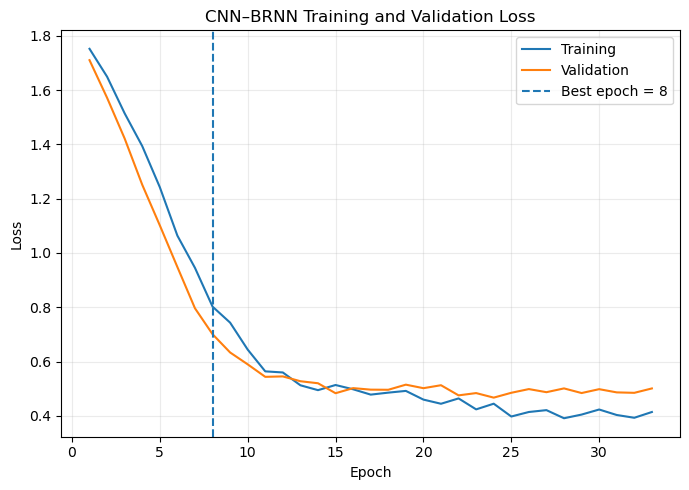

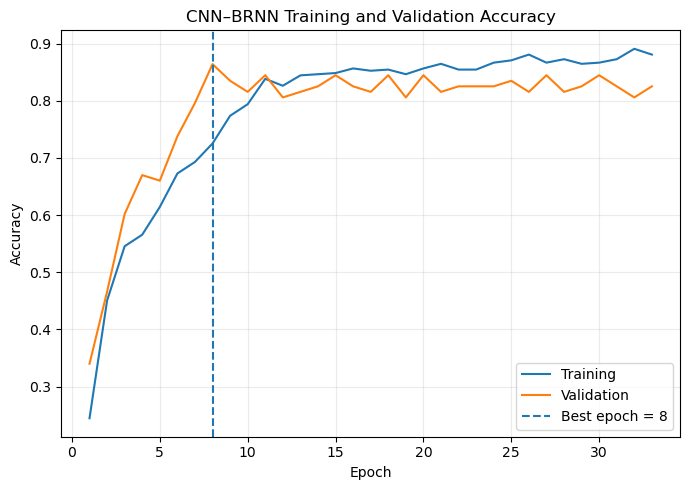


CORE MANUSCRIPT MODEL
           subset   n  accuracy  macro_f1  macro_precision  macro_recall
Core 1 ppb–10 ppm 101  0.910891  0.905075         0.916122      0.907712

Classification report:
              precision    recall  f1-score   support

     benzene     0.9412    0.8421    0.8889        19
     toluene     0.8333    0.9375    0.8824        16
ethylbenzene     1.0000    0.9524    0.9756        21
    m_xylene     0.8889    1.0000    0.9412        16
    o_xylene     1.0000    0.7143    0.8333        14
    p_xylene     0.8333    1.0000    0.9091        15

    accuracy                         0.9109       101
   macro avg     0.9161    0.9077    0.9051       101
weighted avg     0.9202    0.9109    0.9095       101



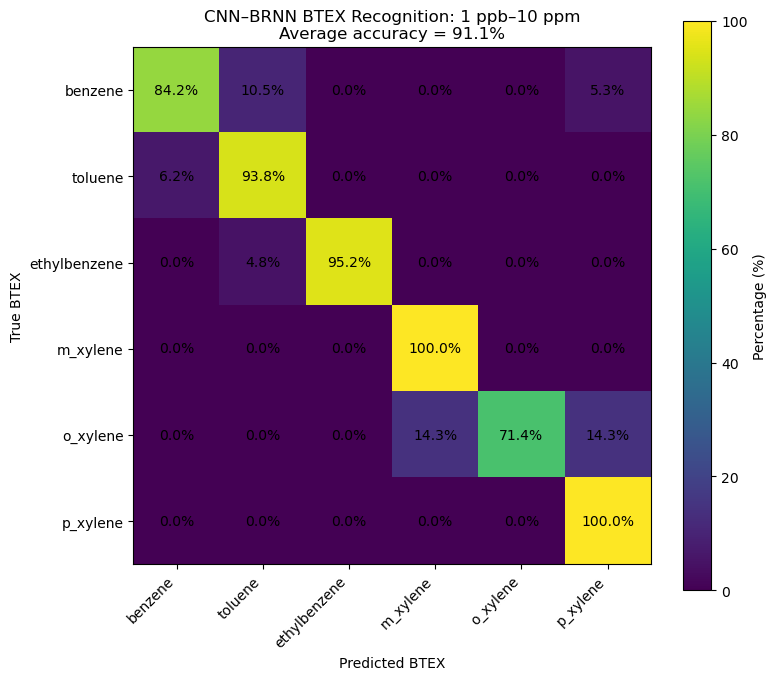


CONCENTRATION-SPECIFIC PERFORMANCE
 concentration_ppb  n  accuracy  macro_f1  macro_precision  macro_recall
               1.0 26  0.730769  0.625397         0.733333      0.759848
               3.0 10  1.000000  1.000000         1.000000      1.000000
              10.0  9  1.000000  1.000000         1.000000      1.000000
              30.0  9  1.000000  1.000000         1.000000      1.000000
             100.0  6  1.000000  1.000000         1.000000      1.000000
             300.0  8  0.875000  0.733333         0.800000      0.700000
            1000.0 14  1.000000  1.000000         1.000000      1.000000
            3000.0 12  1.000000  1.000000         1.000000      1.000000
           10000.0  7  0.857143  0.900000         0.916667      0.916667

LOW- vs HIGH-CONCENTRATION PERFORMANCE
  subset  n  accuracy  macro_f1  macro_precision  macro_recall
1–10 ppb 45  0.844444  0.813339         0.845238      0.853846
 >10 ppb 56  0.964286  0.963409         0.966667      0.964015
   1 

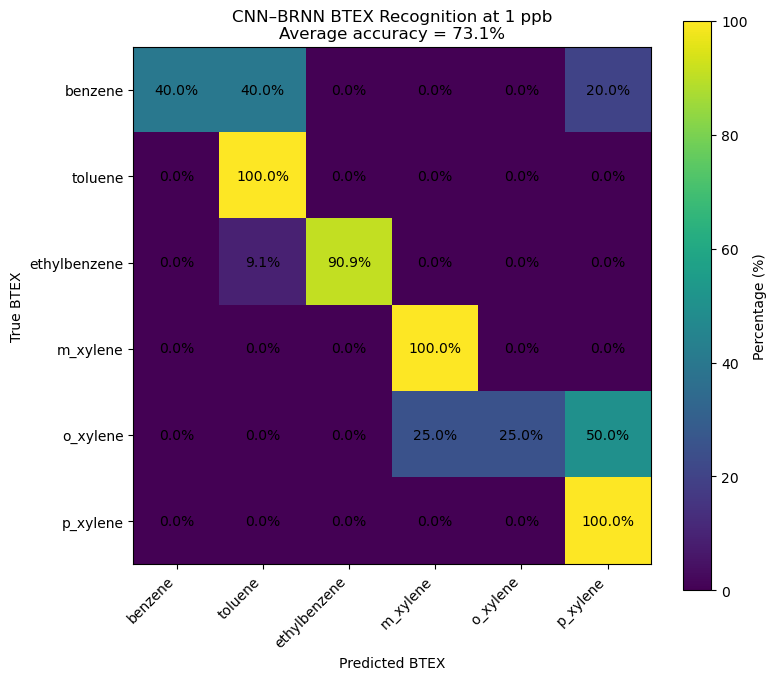

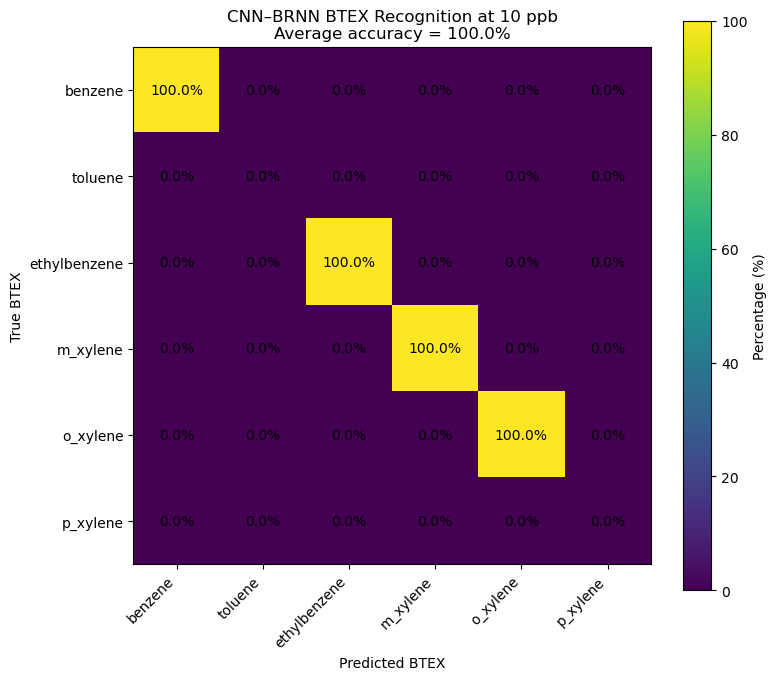

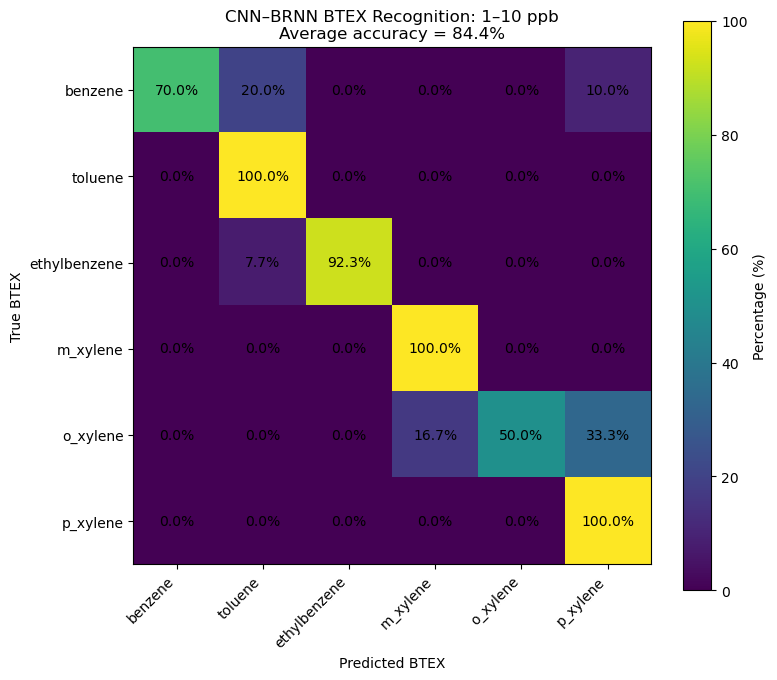

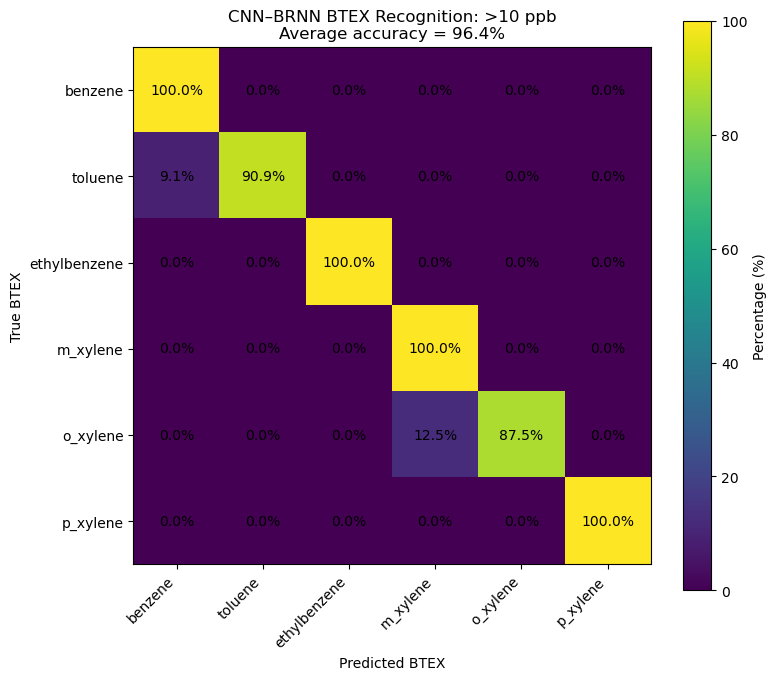


AUXILIARY-VALIDATION PERFORMANCE
                   subset   n  accuracy  macro_f1  macro_precision  macro_recall
   AMBIENT_AIR_VALIDATION 110  0.881818  0.880582         0.882931      0.880929
             BTEX_MIXTURE  36  0.972222  0.972710         0.983333      0.966667
 ENVIRONMENTAL_ROBUSTNESS  84  0.880952  0.875665         0.876852      0.884183
   EXPOSURE_HISTORY_RESET  37  0.972973  0.948148         0.966667      0.944444
LOW_CONC_1PPB_CALIBRATION  74  0.878378  0.881490         0.890079      0.879471

ENVIRONMENTAL ROBUSTNESS

Humidity:
 RH_percent  n  accuracy  mean_confidence
       30.0 22  0.863636         0.609490
       50.0 16  0.937500         0.601834
       70.0 46  0.869565         0.547834

Temperature:
 temperature_C  n  accuracy  mean_confidence
          20.0 22  0.863636         0.609490
          25.0 16  0.937500         0.601834
          30.0 22  0.772727         0.515194
          35.0 24  0.958333         0.577754

Interferents:
interferent_label  n 

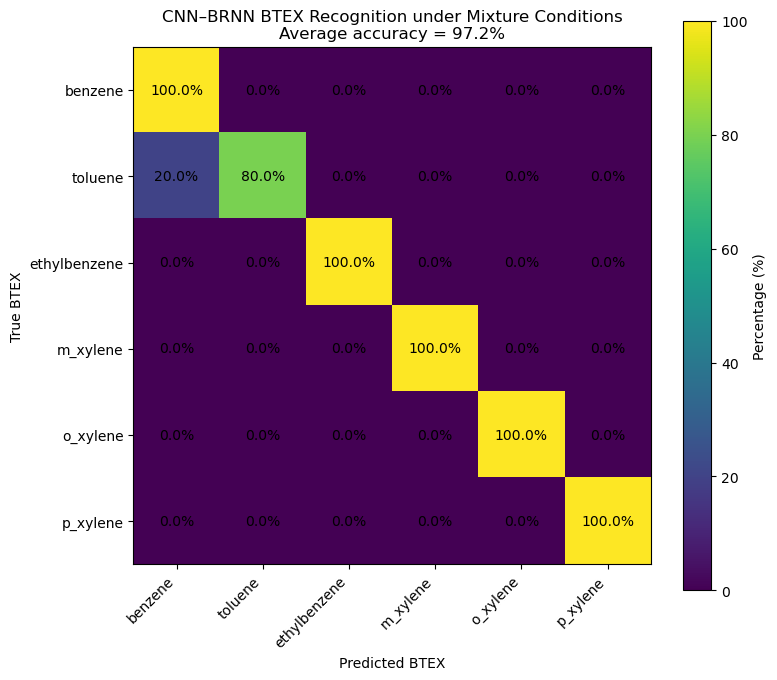


EXPOSURE HISTORY / GATE RESET

With vs without gate reset:
gate_reset  n  accuracy  macro_confidence
        no 19  0.947368          0.693888
       yes 18  1.000000          0.596561

Previous exposure × reset:
previous_exposure_label gate_reset  n  accuracy  mean_confidence
                benzene         no  1       1.0         0.500387
                benzene        yes  2       1.0         0.567392
           ethylbenzene         no  6       1.0         0.669287
           ethylbenzene        yes  1       1.0         0.543434
               m_xylene         no  6       1.0         0.698288
               m_xylene        yes  1       1.0         0.611702
               o_xylene         no  4       1.0         0.814399
               o_xylene        yes  7       1.0         0.579926
                toluene         no  2       0.5         0.610225
                toluene        yes  7       1.0         0.626957

LOW-CONCENTRATION / 1 ppb ANALYSIS

Low-concentration classification:


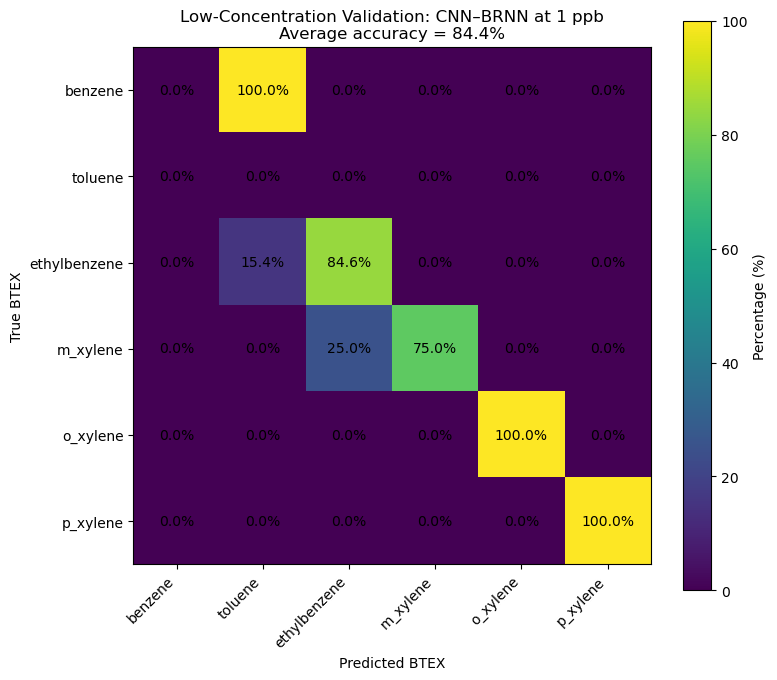

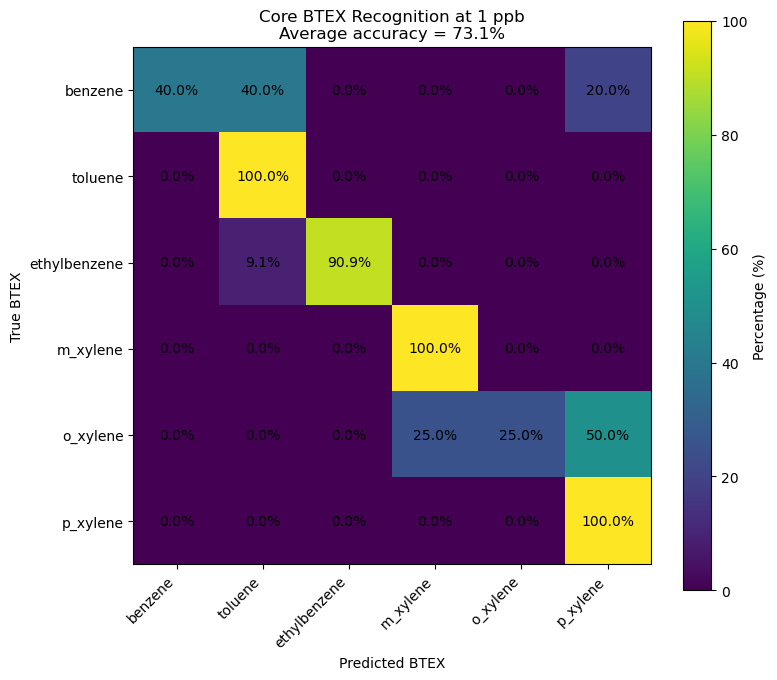

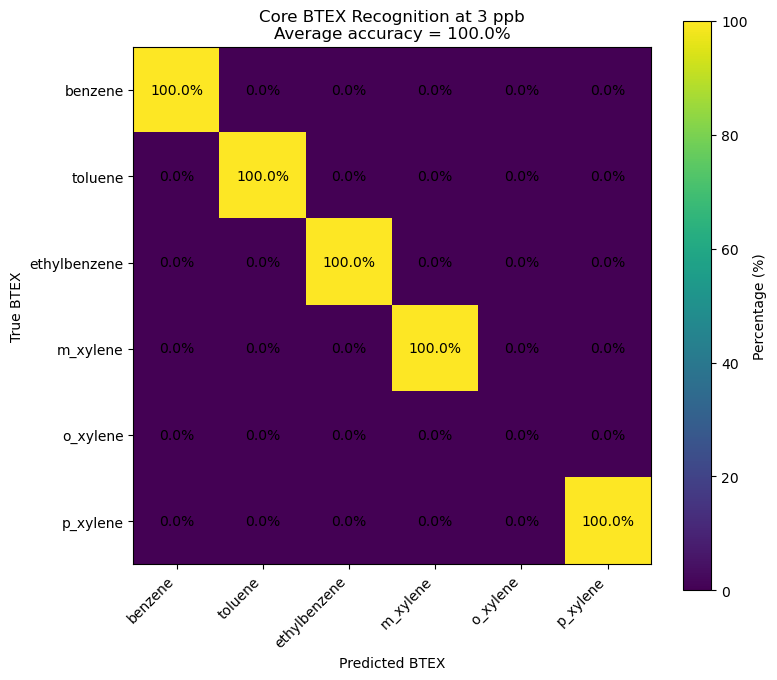

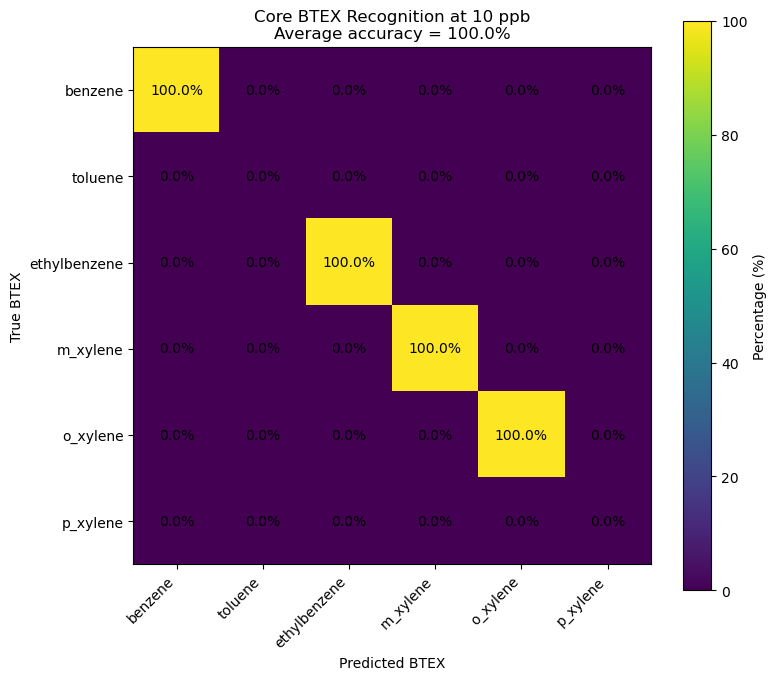

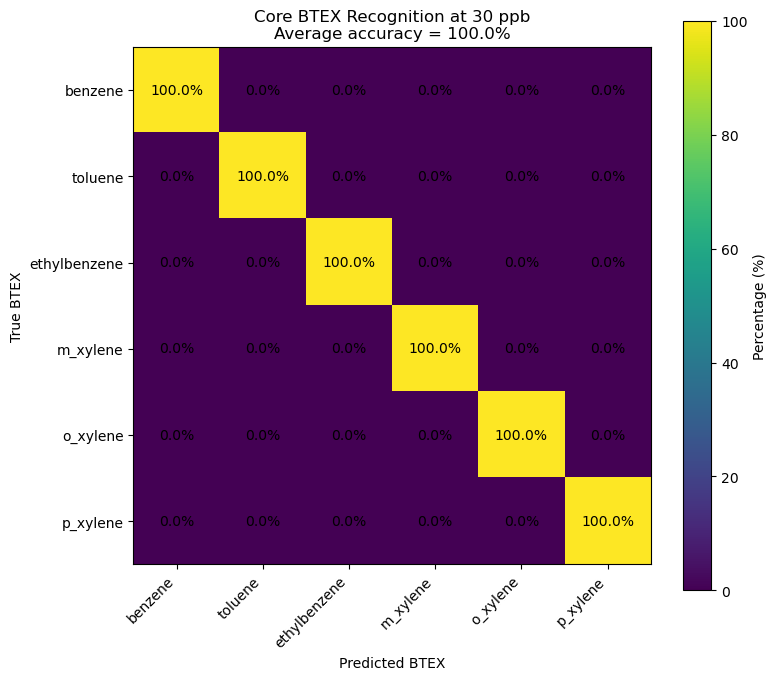

...

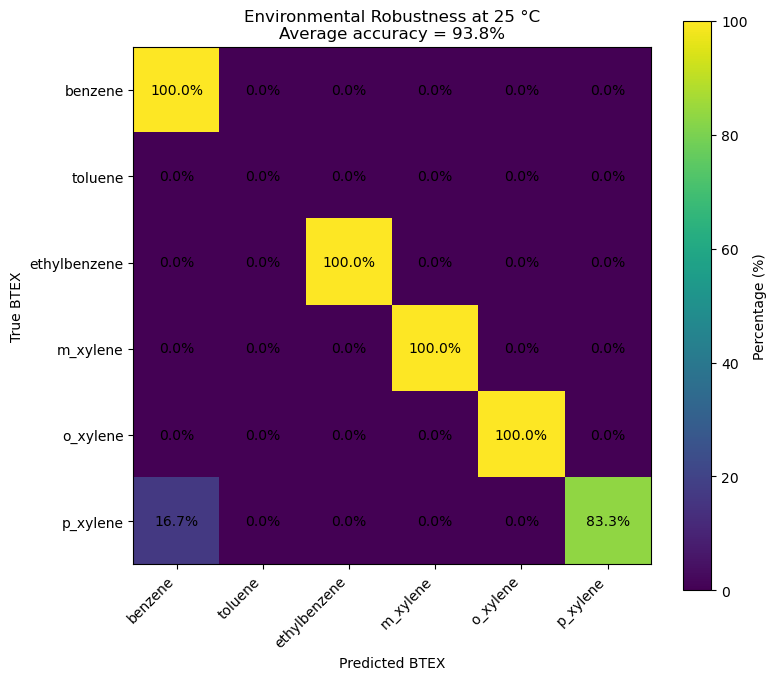

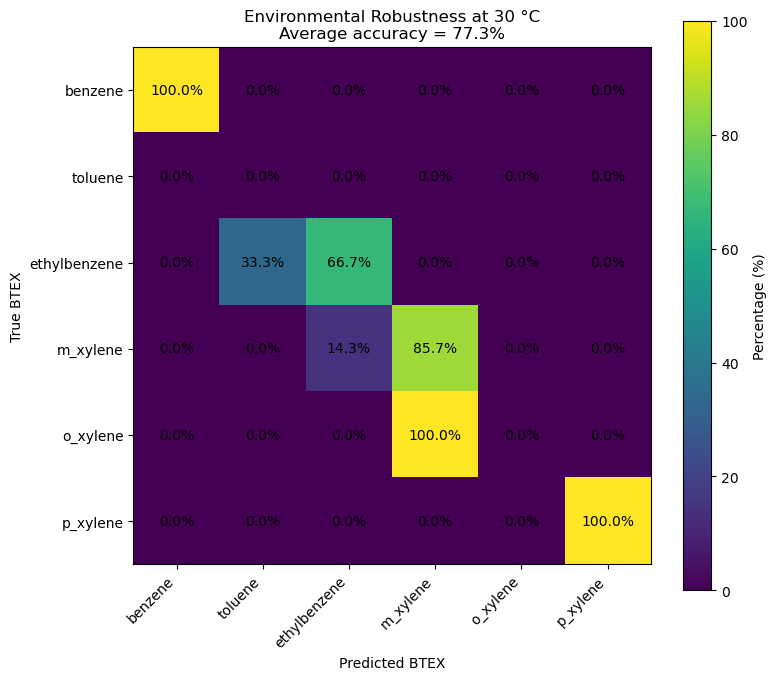

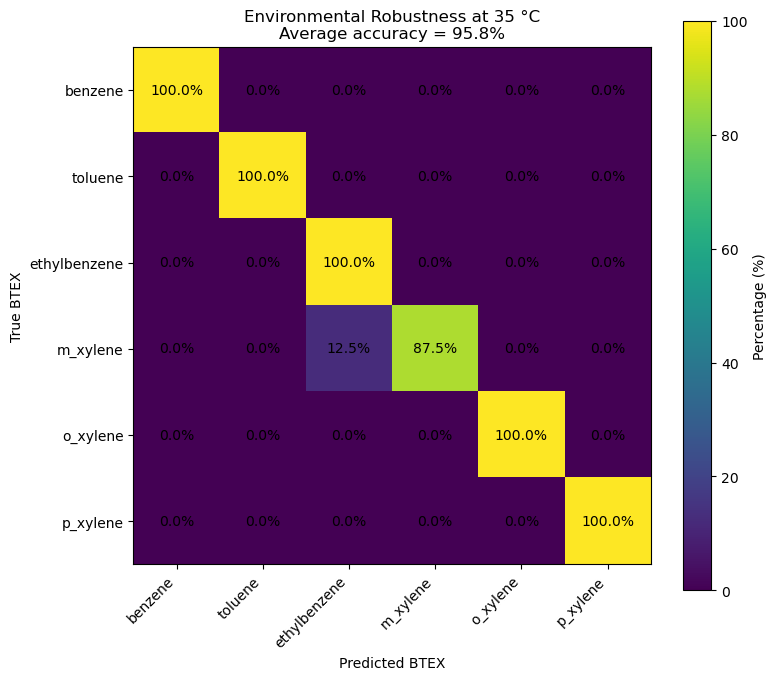

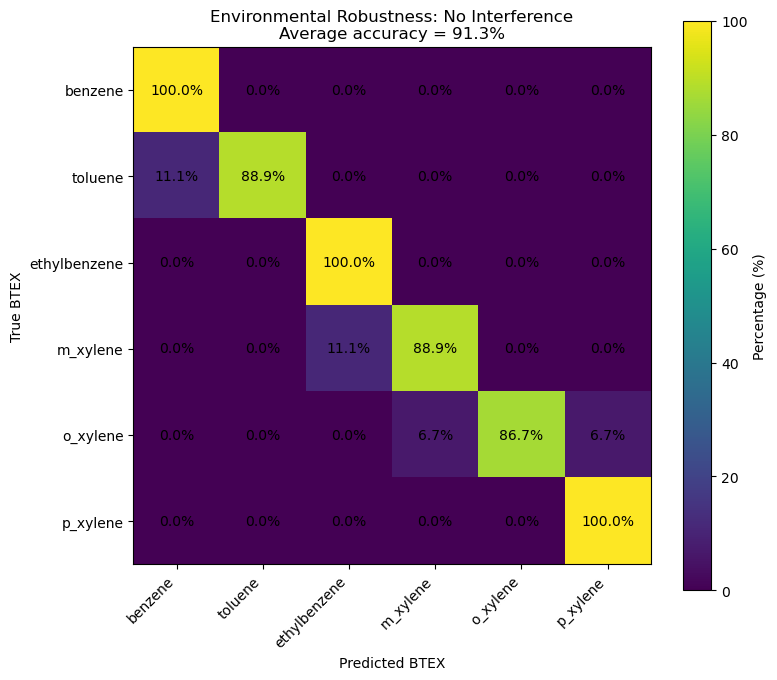

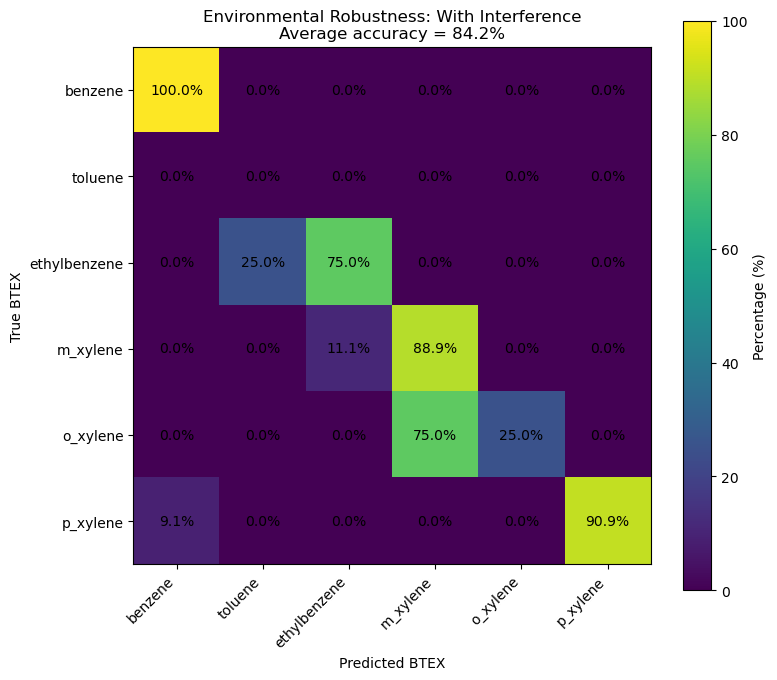


Individual interferent confusion matrices: ['CO', 'NH3', 'NO2', 'acetone', 'ethanol', 'formaldehyde']


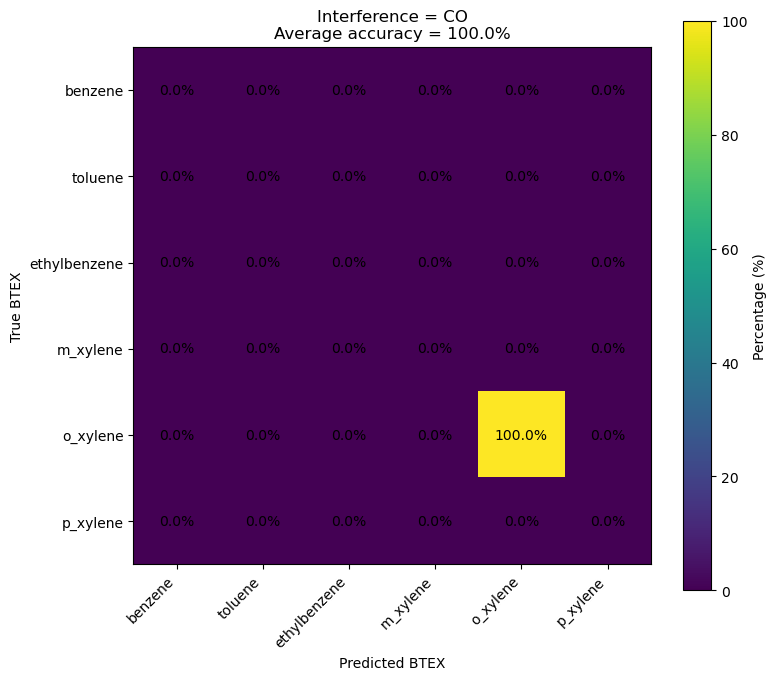

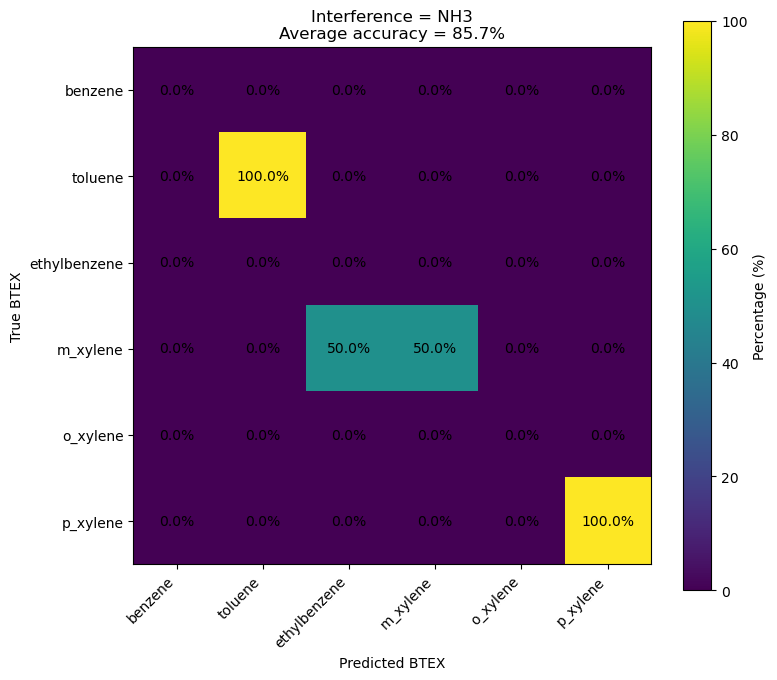

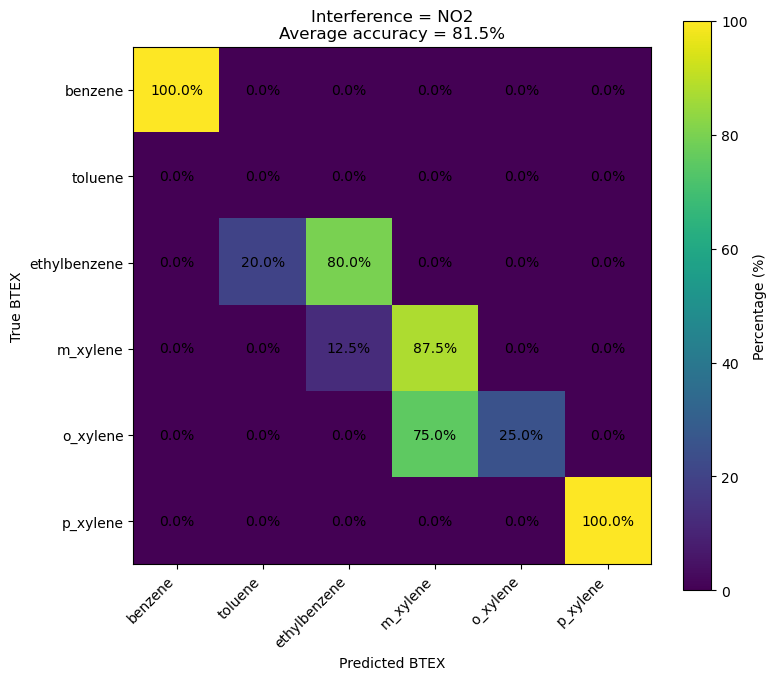

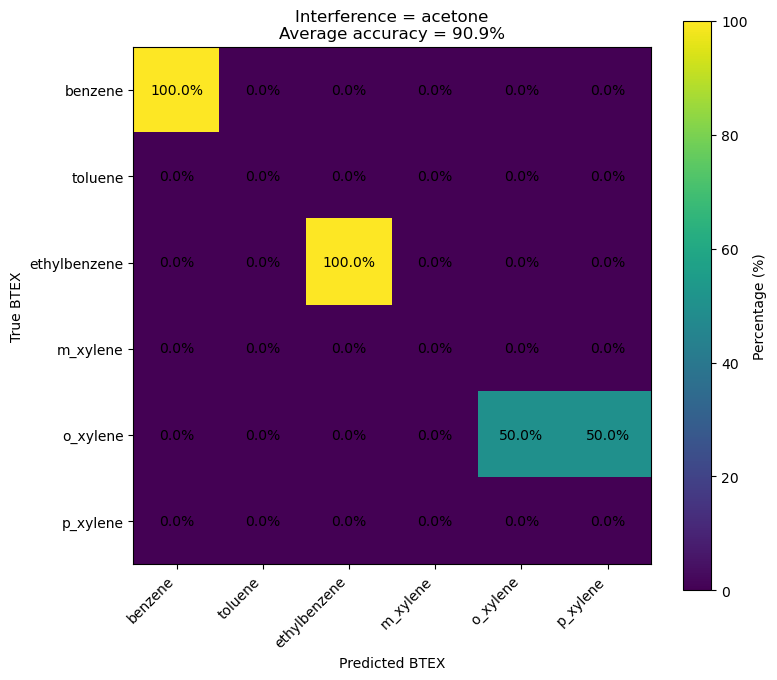

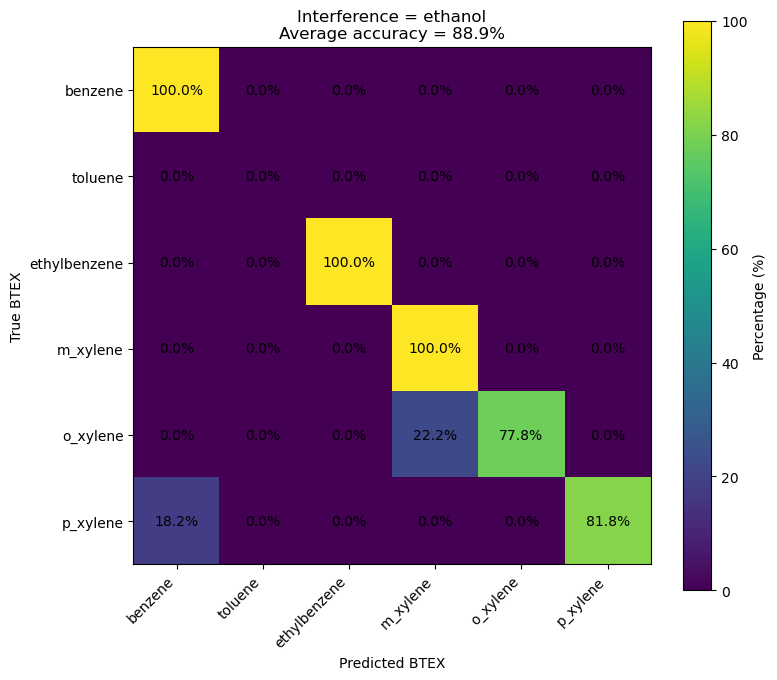

...

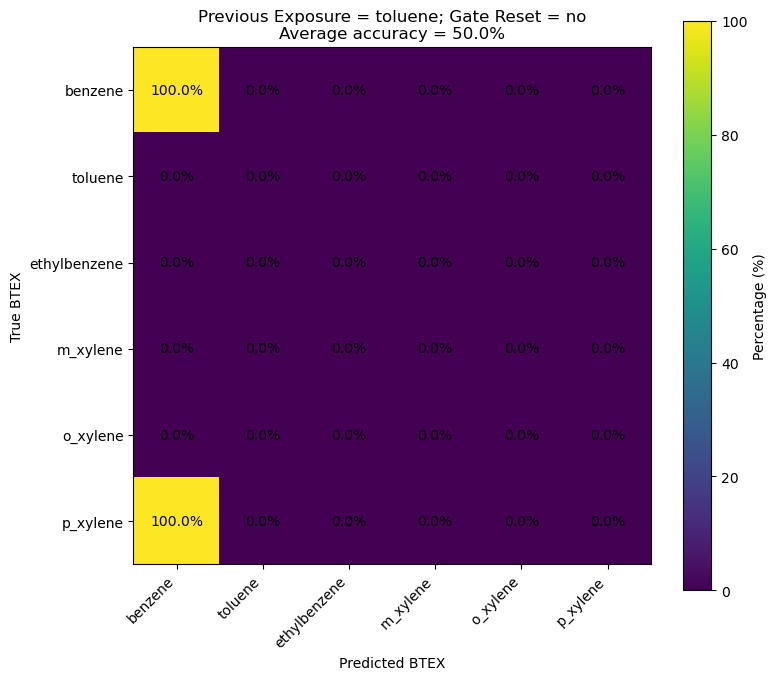

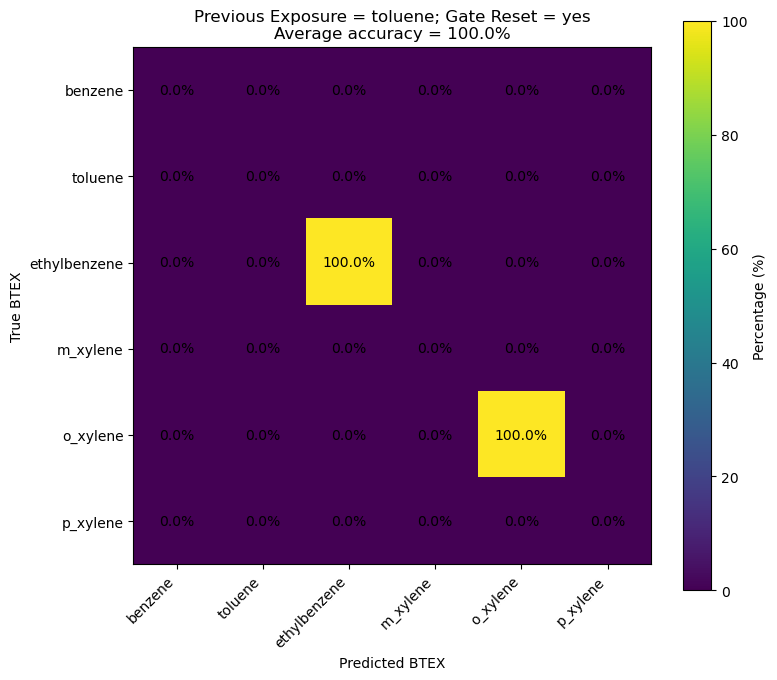

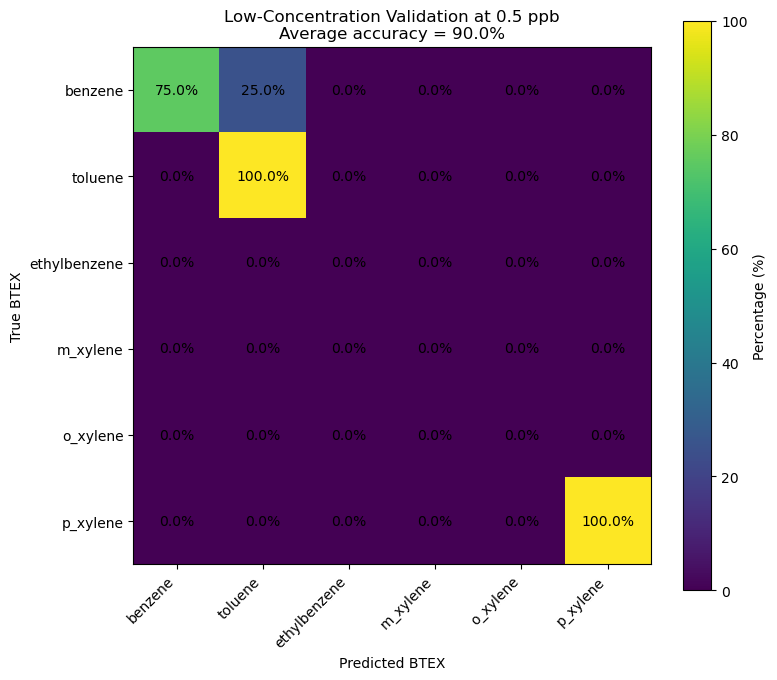

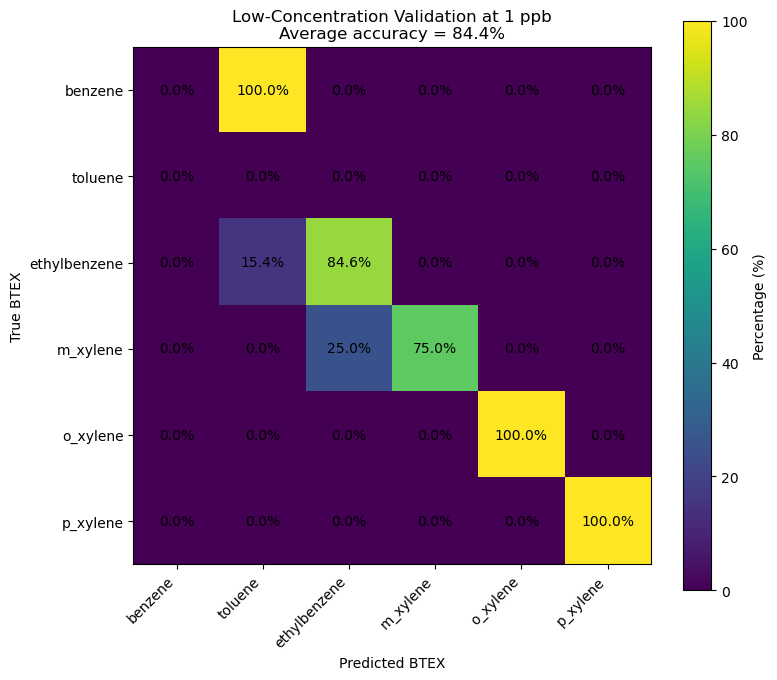

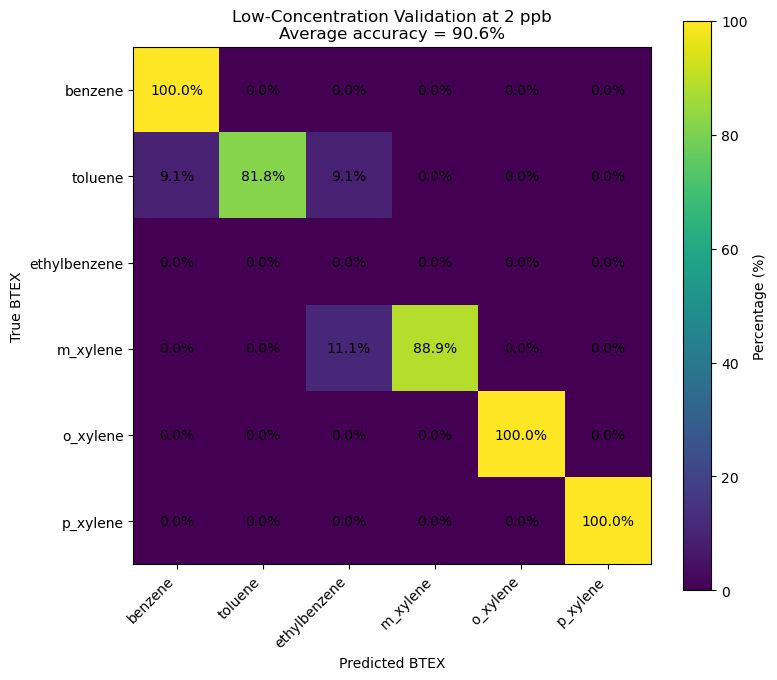


ALL-CONDITION CONFUSION-MATRIX ACCURACY
                                         condition  n_samples  average_accuracy_percent
                  BTEX Mixture Condition: RMIX0002          1                100.000000
                  BTEX Mixture Condition: RMIX0003          1                100.000000
                  BTEX Mixture Condition: RMIX0004          2                100.000000
                  BTEX Mixture Condition: RMIX0005          4                100.000000
                  BTEX Mixture Condition: RMIX0011          1                100.000000
                  BTEX Mixture Condition: RMIX0029          3                 66.666667
                  BTEX Mixture Condition: RMIX0032          2                100.000000
                  BTEX Mixture Condition: RMIX0040          2                100.000000
                  BTEX Mixture Condition: RMIX0048          2                100.000000
                  BTEX Mixture Condition: RMIX0053          3                10

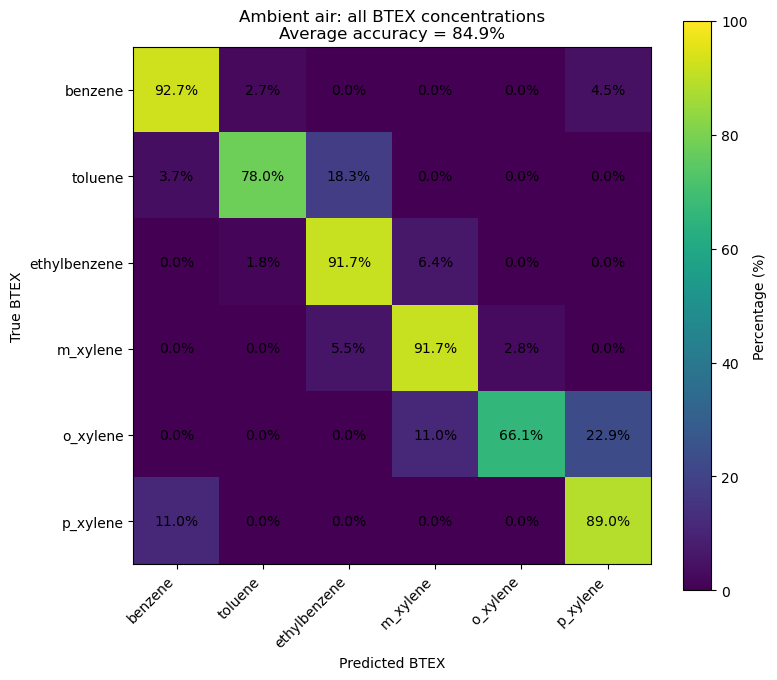


Ambient-air metrics by concentration:
                     subset    n  accuracy  macro_f1  macro_precision  \
0     Ambient air - 0.5 ppb   31  0.677419  0.510417         0.458333   
1       Ambient air - 1 ppb  120  0.733333  0.692564         0.723684   
2       Ambient air - 2 ppb   45  0.866667  0.713716         0.683883   
3       Ambient air - 3 ppb   72  0.750000  0.707968         0.751130   
4      Ambient air - 10 ppb  100  0.850000  0.828266         0.816898   
5      Ambient air - 30 ppb   50  0.960000  0.960648         0.962963   
6     Ambient air - 100 ppb   87  0.908046  0.904704         0.933551   
7     Ambient air - 300 ppb   71  0.915493  0.885926         0.888568   
8    Ambient air - 1000 ppb   29  0.931034  0.792190         0.809524   
9    Ambient air - 3000 ppb   12  1.000000  1.000000         1.000000   
10  Ambient air - 10000 ppb   38  1.000000  1.000000         1.000000   

    macro_recall  concentration_ppb  
0       0.607143                0.5  
1       

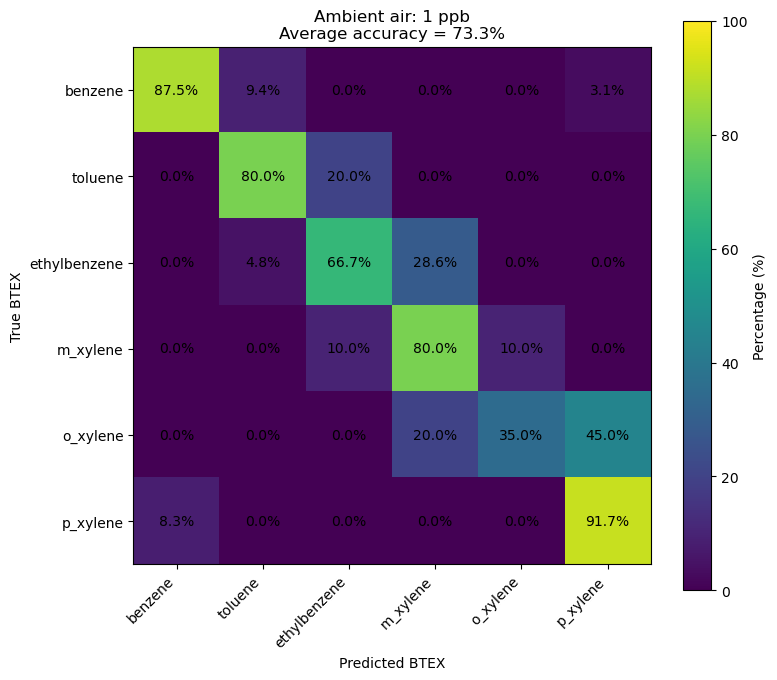

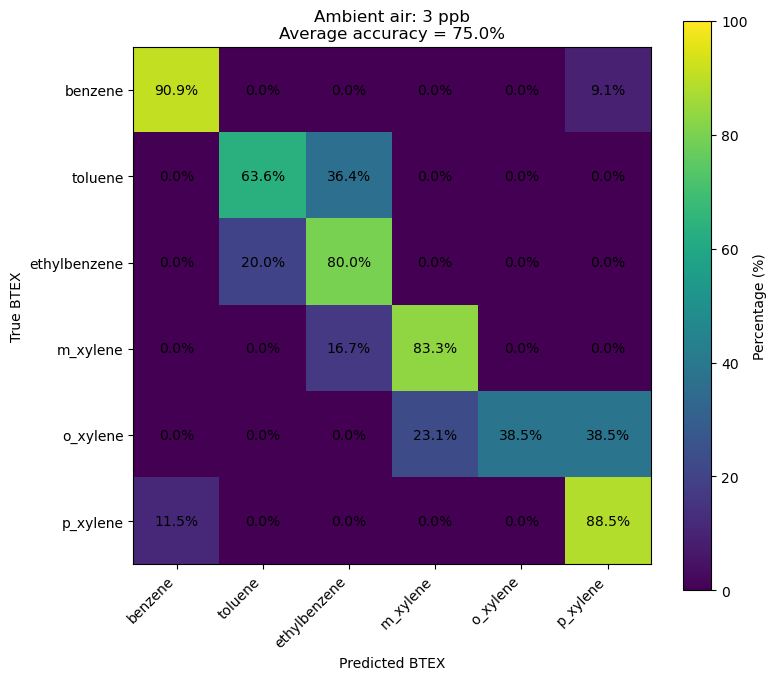

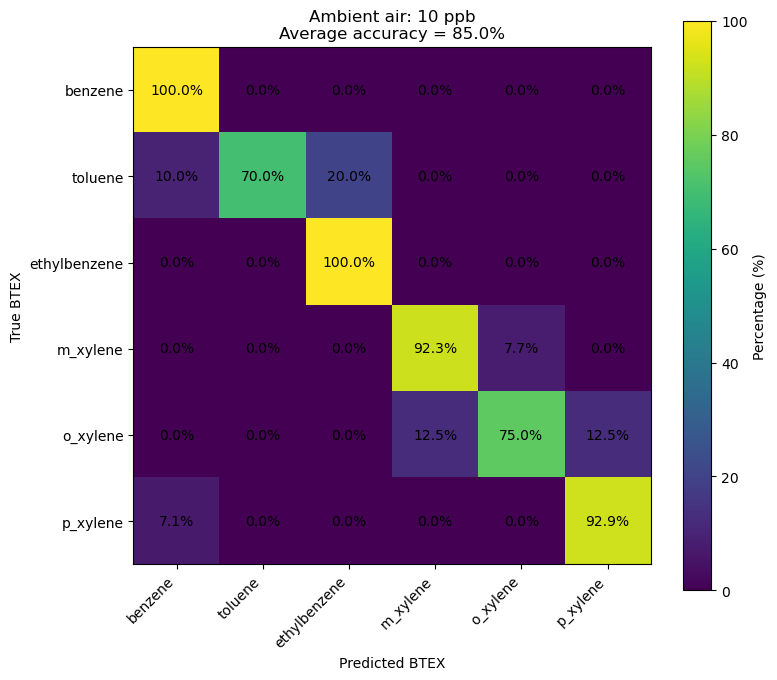

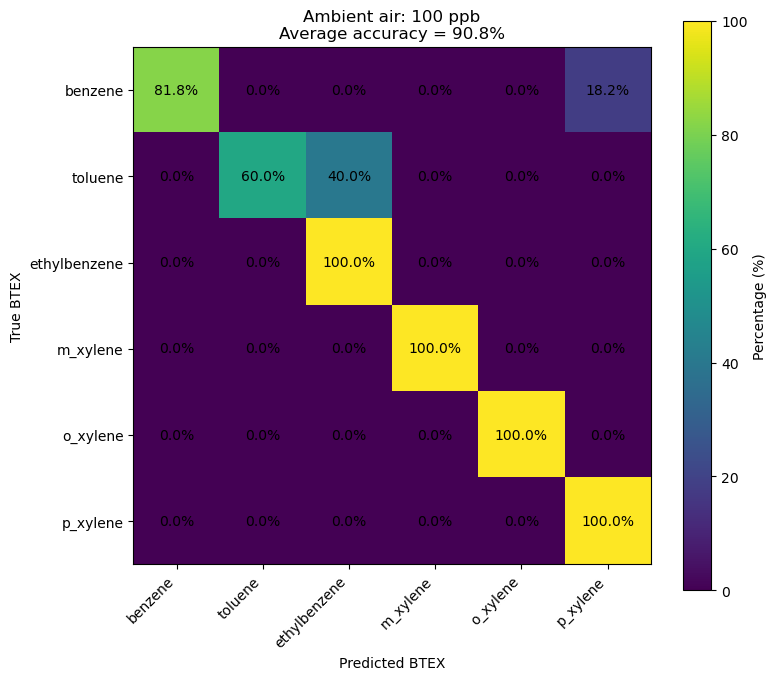

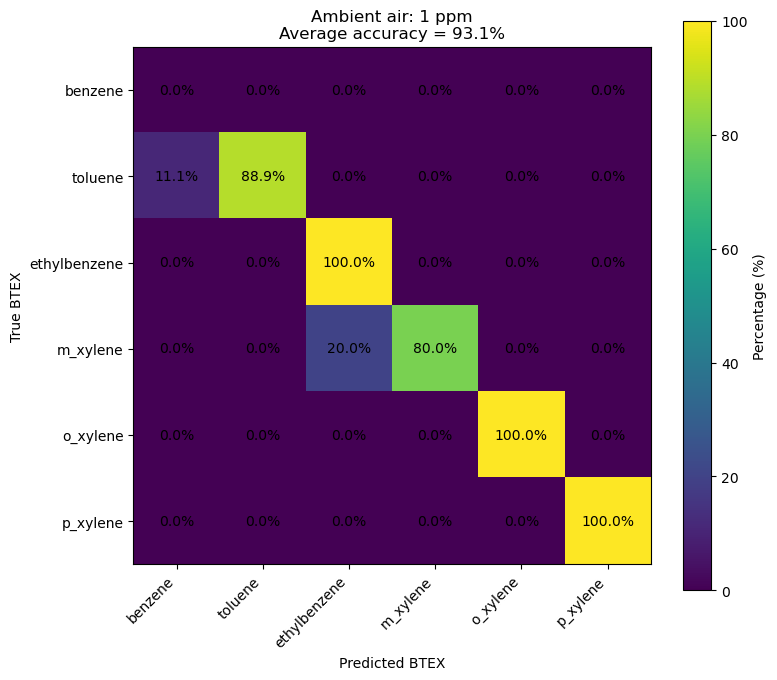

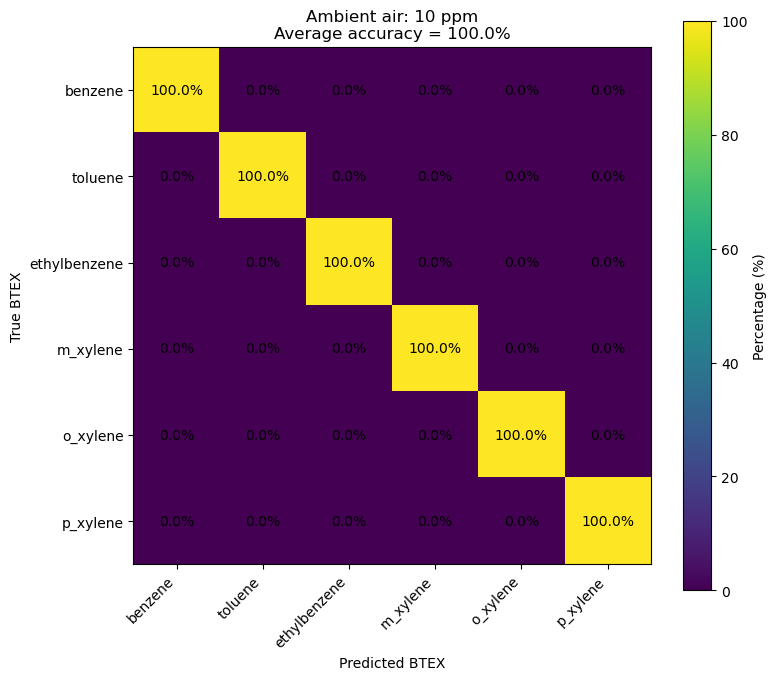


N2 vs ambient-air comparison:
   background_gas  concentration_ppb    n  accuracy  macro_f1
0              N2                1.0  606  0.816832  0.813253
1              N2                3.0  170  0.805882  0.802345
2              N2               10.0  362  0.911602  0.911292
3              N2              100.0  418  0.968900  0.968675
4              N2             1000.0  162  0.981481  0.979790
5              N2            10000.0   94  0.840426  0.833847
6     ambient air                1.0  120  0.733333  0.692564
7     ambient air                3.0   72  0.750000  0.707968
8     ambient air               10.0  100  0.850000  0.828266
9     ambient air              100.0   87  0.908046  0.904704
10    ambient air             1000.0   29  0.931034  0.792190
11    ambient air            10000.0   38  1.000000  1.000000


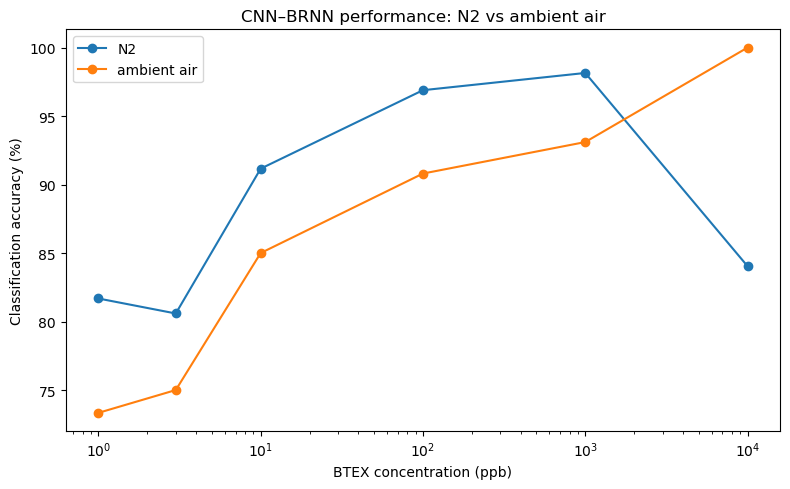


Ambient-air metrics by analyte:
      gas_label    n  accuracy  mean_confidence
0       benzene  110  0.927273         0.725968
1       toluene  109  0.779817         0.641416
2  ethylbenzene  109  0.917431         0.579644
3      m_xylene  109  0.917431         0.488241
4      o_xylene  109  0.660550         0.467835
5      p_xylene  109  0.889908         0.499053

Ambient-air analysis complete.
{
  "ambient_air_sequences": 655,
  "ambient_air_accuracy": 0.8488549618320611,
  "ambient_air_macro_f1": 0.8469846008483026,
  "all_required_ambient_concentrations_present": false
}

EXTENDED FOUR-DOMAIN ROBUSTNESS ANALYSIS
N2 - no interference                    1725 sequences
N2 - with interference                   679 sequences
Ambient air - no interference            389 sequences
Ambient air - with interference          266 sequences


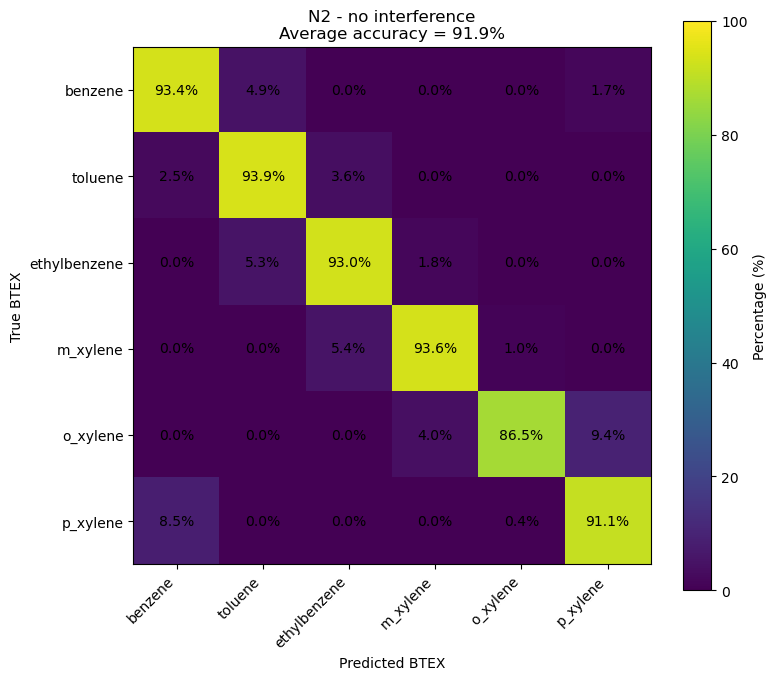

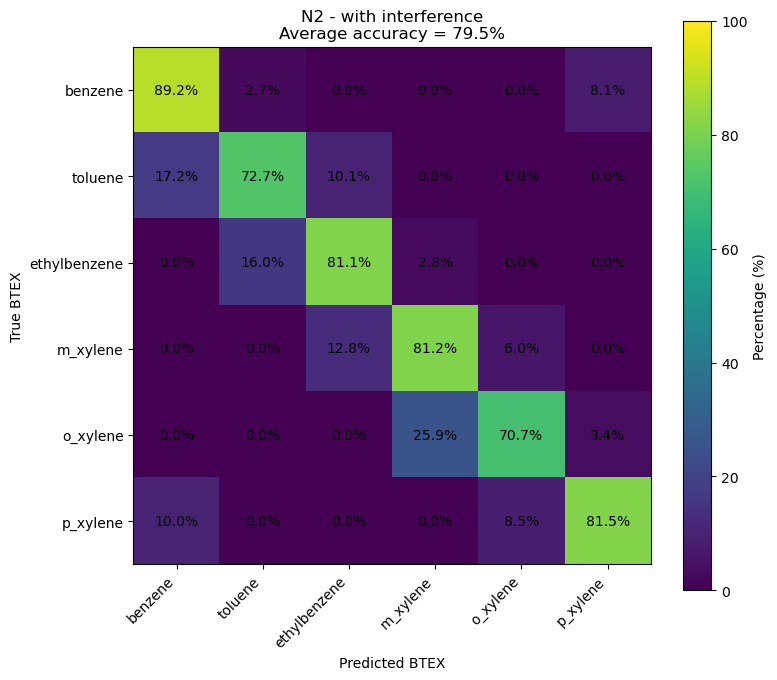

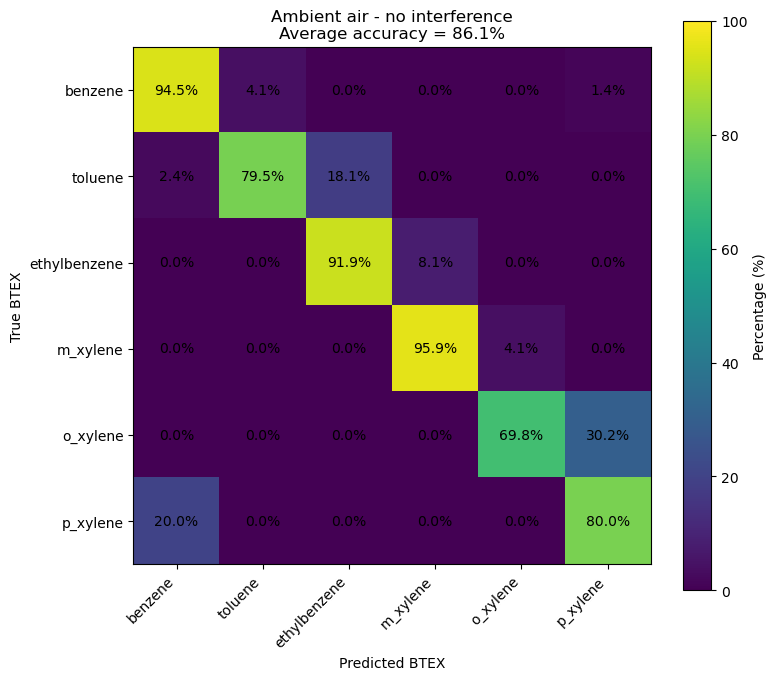

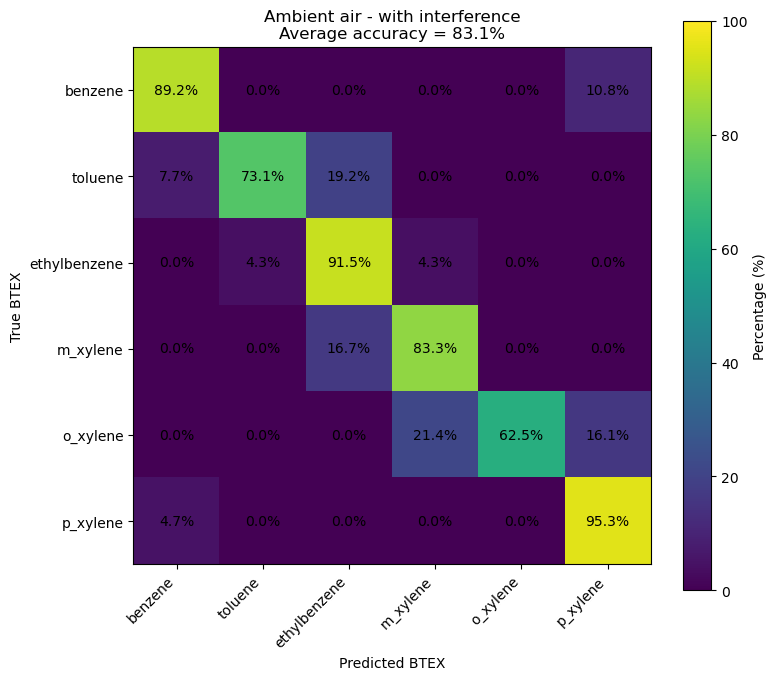


Advanced four-domain metrics:
                         domain    n  accuracy  accuracy_ci95_low  accuracy_ci95_high  balanced_accuracy  macro_f1  weighted_f1  macro_precision  macro_recall  matthews_corrcoef  cohen_kappa  mean_confidence  median_confidence  multiclass_brier_score  expected_calibration_error  negative_log_likelihood  top2_accuracy  mean_normalized_entropy  bootstrap_accuracy_ci95_low  bootstrap_accuracy_ci95_high
           N2 - no interference 1725  0.918841           0.905004            0.930816           0.919158  0.918760     0.918935         0.920005      0.919158           0.902926     0.902618         0.610086           0.600428                0.270384                    0.308755                 0.579535       0.976812                 0.614016                     0.906087                      0.931014
         N2 - with interference  679  0.795287           0.763316            0.823936           0.794122  0.792955     0.794880         0.796295      0.794122     

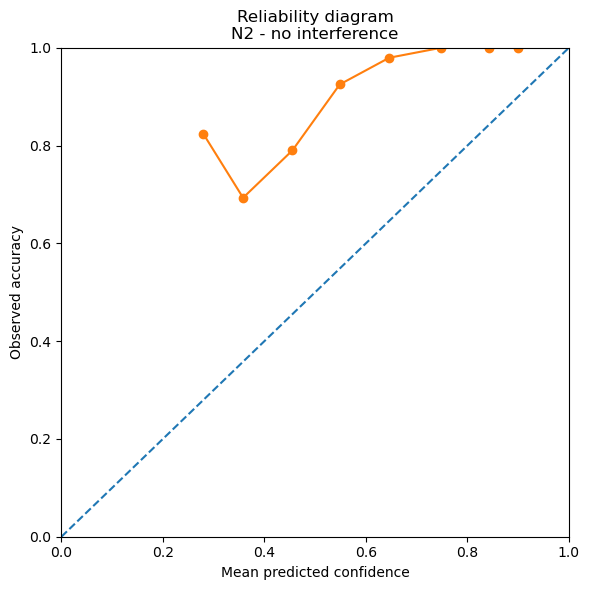

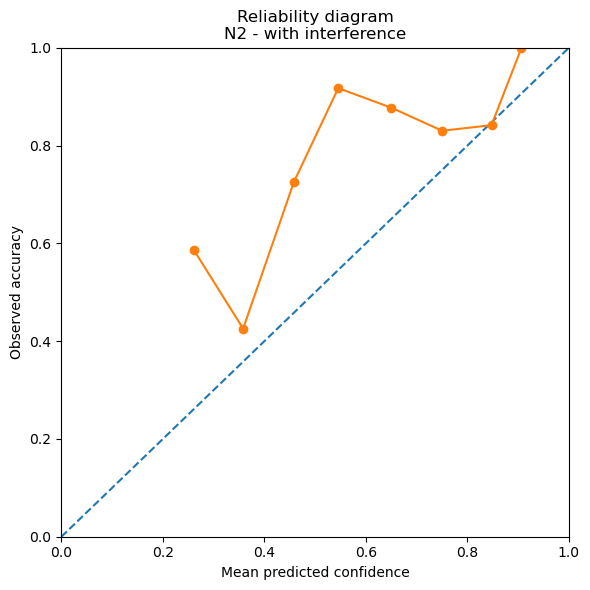

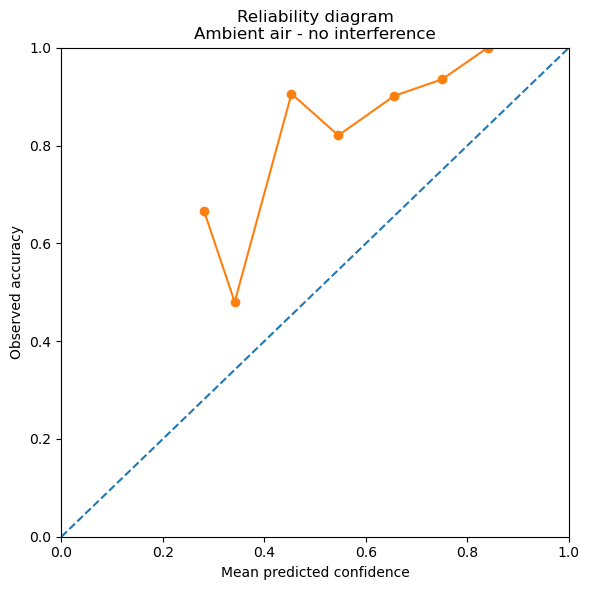

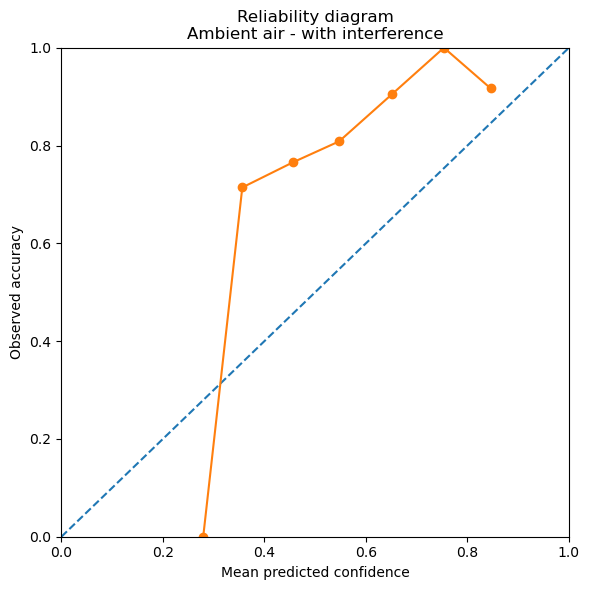


Confidence/entropy analysis:
                         domain prediction_status    n  mean_confidence  median_confidence  mean_normalized_entropy  median_normalized_entropy
           N2 - no interference           correct 1585         0.623693           0.617987                 0.600860                   0.629200
           N2 - no interference         incorrect  140         0.456033           0.444646                 0.762962                   0.760608
         N2 - with interference           correct  540         0.627341           0.624396                 0.587486                   0.612264
         N2 - with interference         incorrect  139         0.536800           0.485072                 0.665631                   0.672584
  Ambient air - no interference           correct  335         0.574303           0.543350                 0.640427                   0.679058
  Ambient air - no interference         incorrect   54         0.489073           0.482873                 0.754

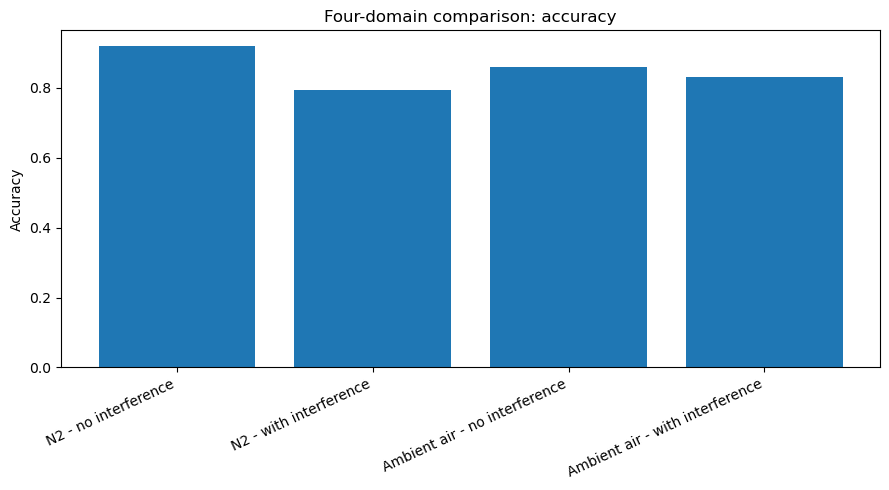

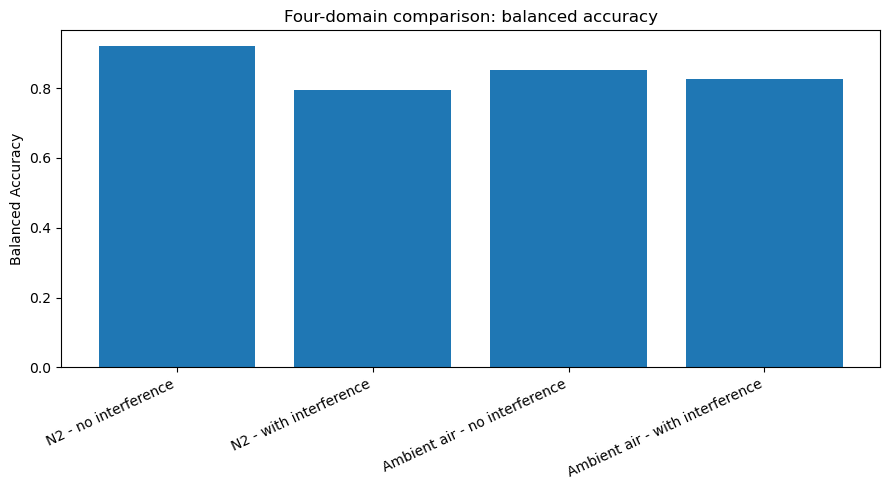

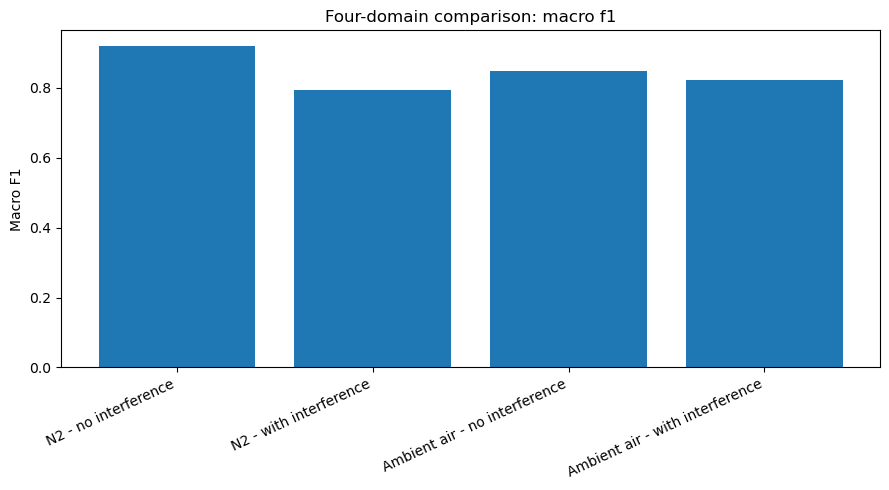

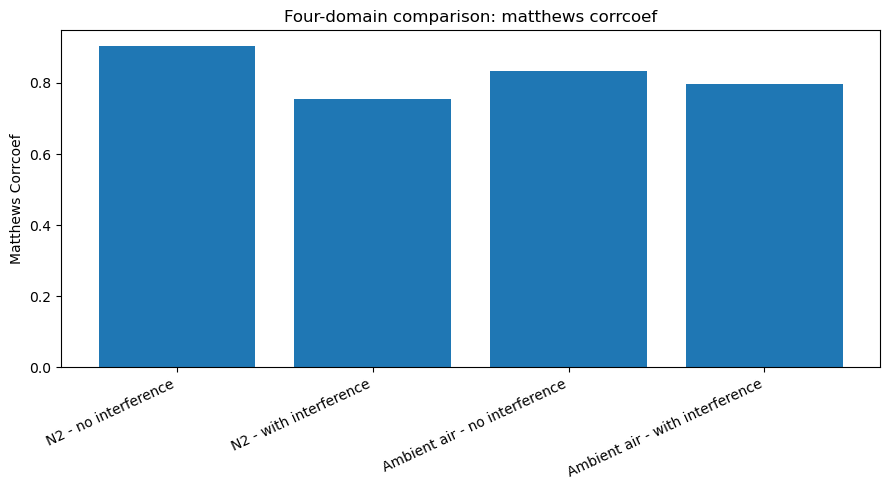

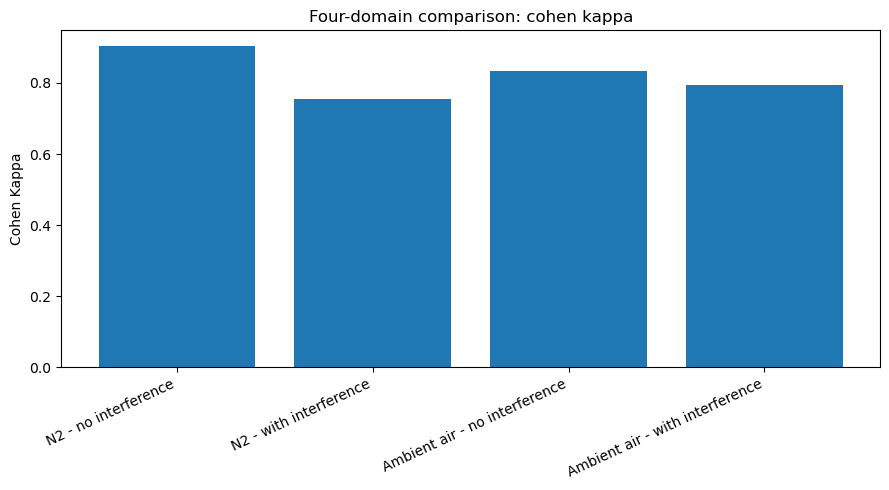

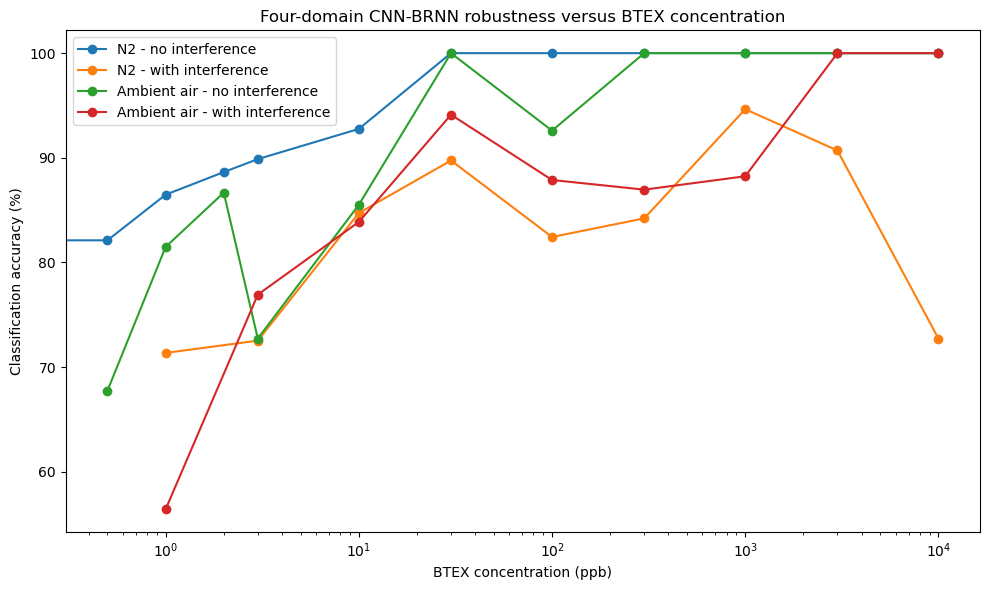


EXTENDED FOUR-DOMAIN ANALYSIS COMPLETE
Additional outputs include:
  - advanced overall metrics + bootstrap confidence intervals
  - per-class sensitivity/specificity/precision/F1
  - ROC-AUC and PR-AUC
  - calibration/ECE/Brier/NLL/top-2 accuracy
  - uncertainty and prediction entropy
  - concentration-range and low-ppb robustness
  - analyte-specific interference analysis
  - specific interferent dose-response analysis
  - humidity and temperature robustness
  - matched interference penalties
  - matched N2-to-ambient domain gaps
  - xylene-isomer cross-confusion
  - worst-case subgroup analysis
  - dataset balance and coverage


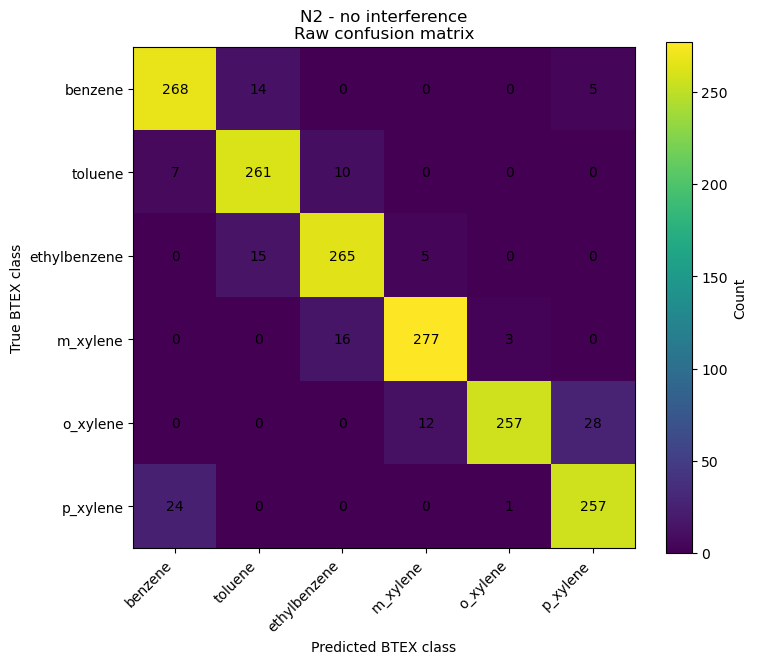

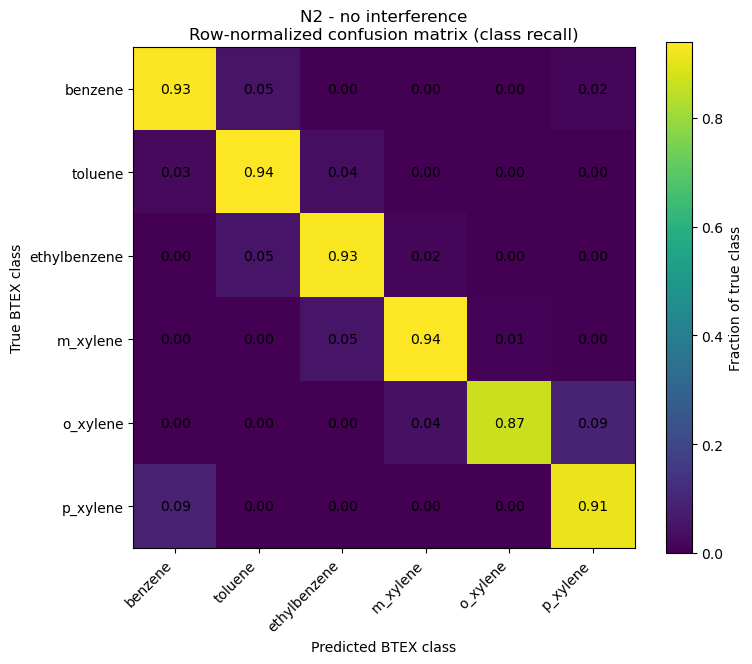

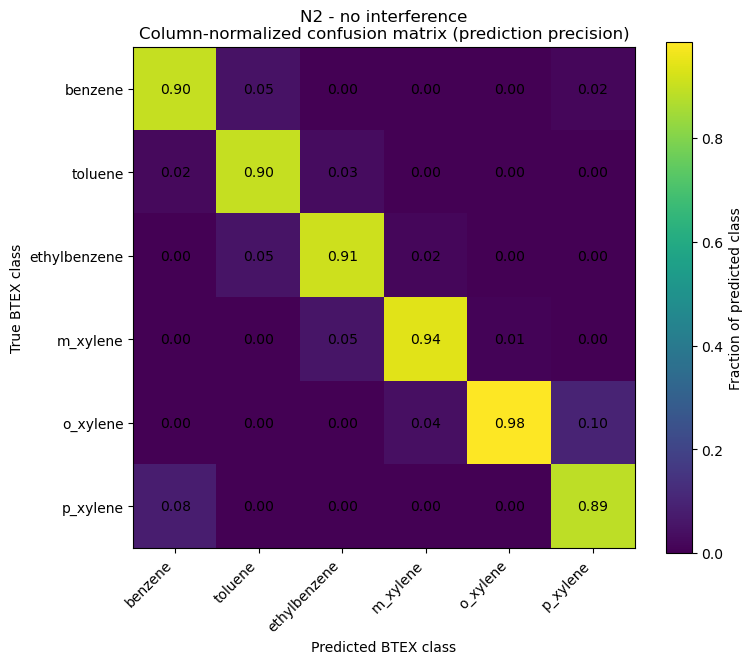

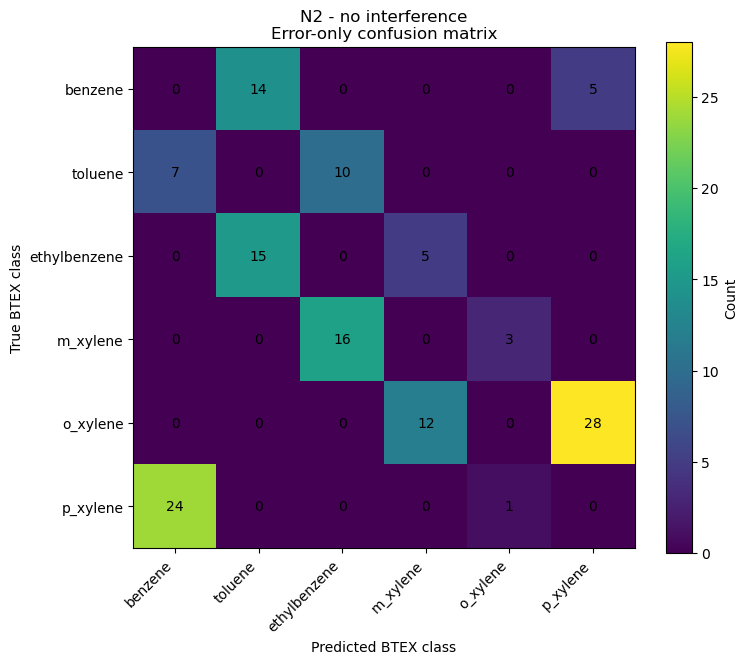

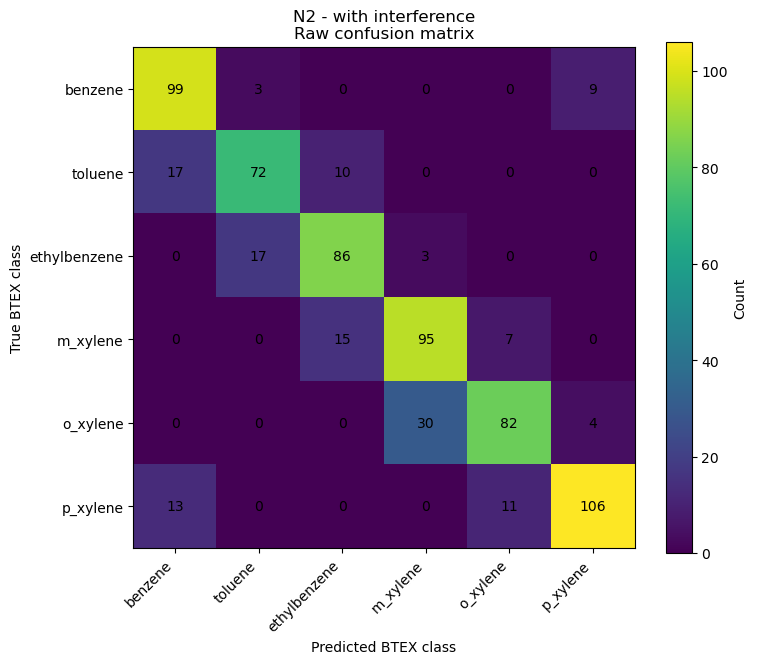

...

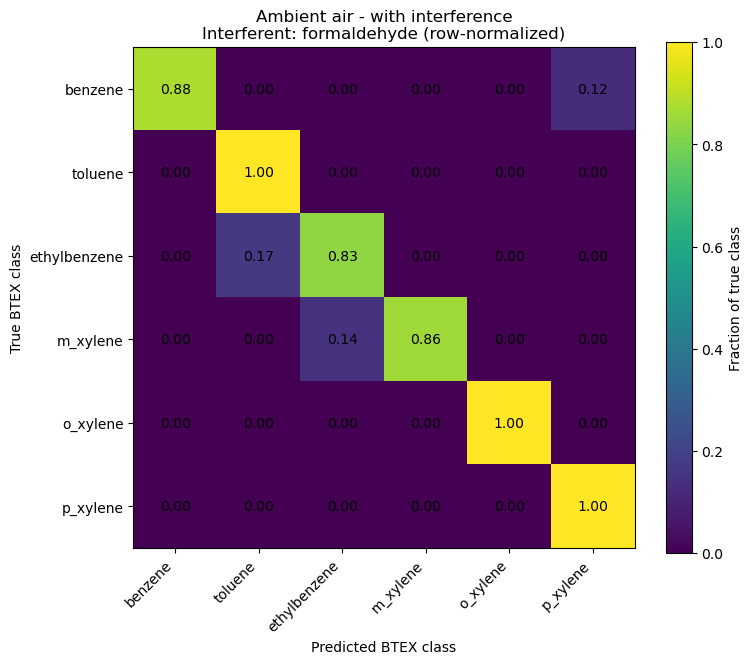

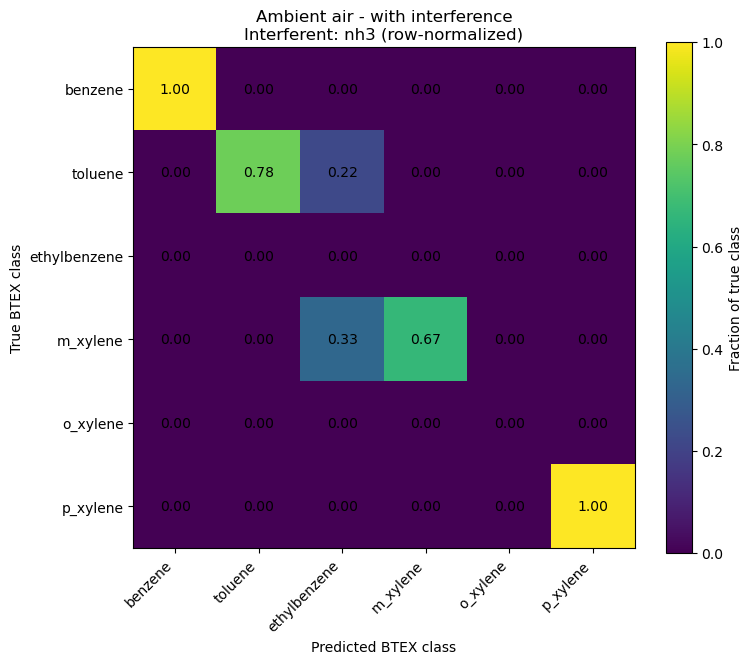

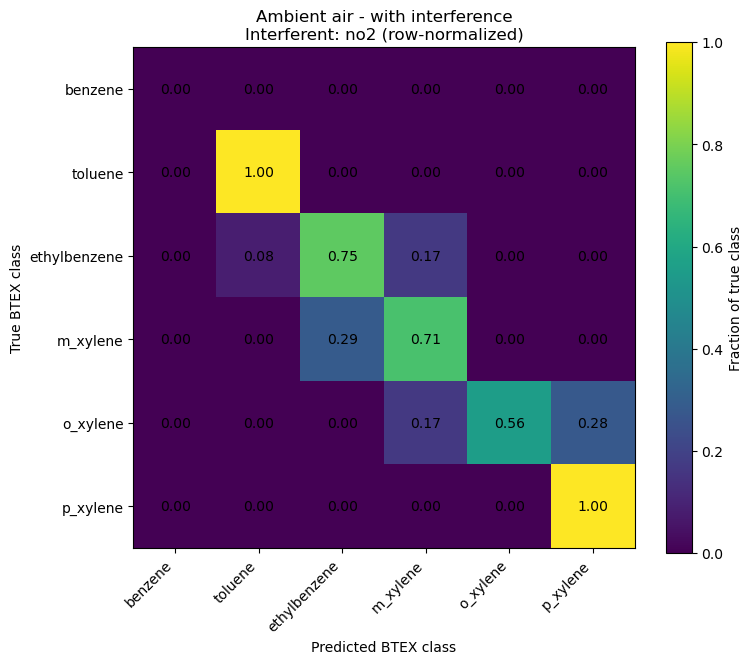

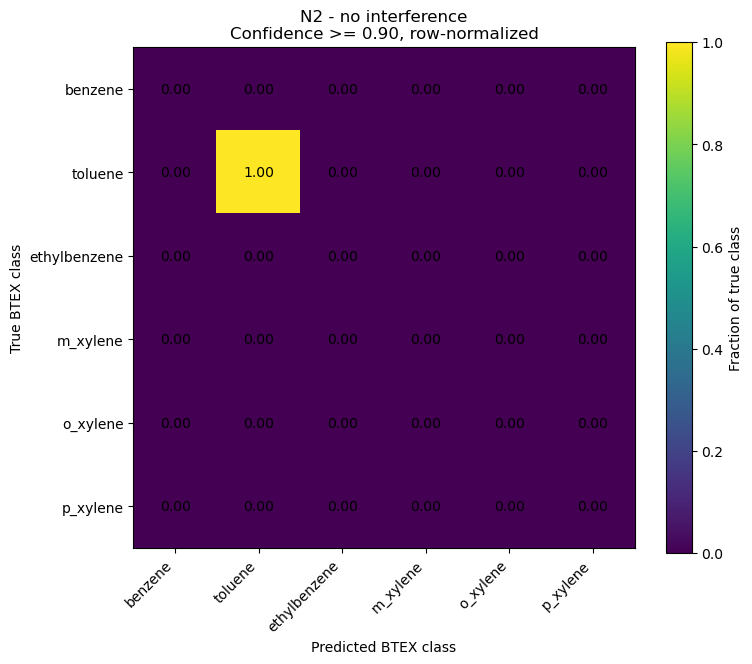

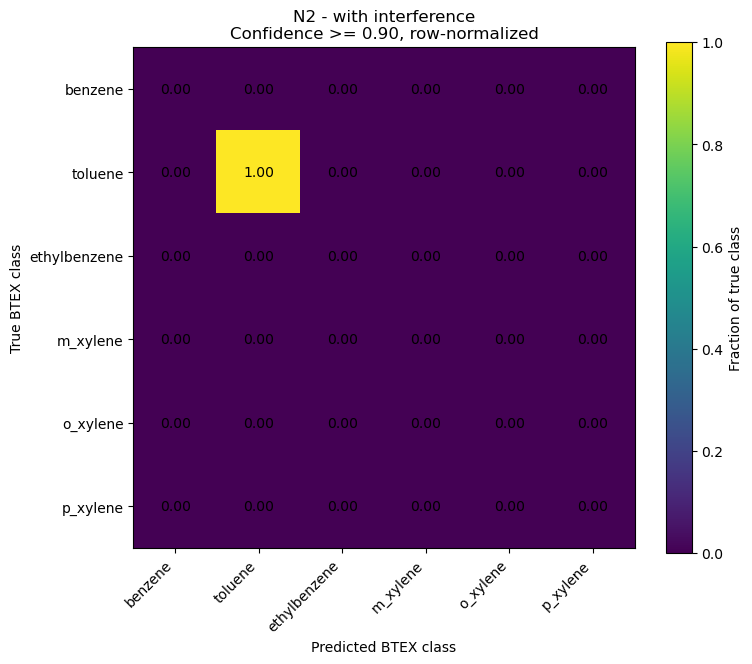


Confusion-matrix summary:
                         domain    n  correct_predictions  incorrect_predictions  overall_accuracy  benzene_support  benzene_recall  toluene_support  toluene_recall  ethylbenzene_support  ethylbenzene_recall  m_xylene_support  m_xylene_recall  o_xylene_support  o_xylene_recall  p_xylene_support  p_xylene_recall
           N2 - no interference 1725                 1585                    140          0.918841              287        0.933798              278        0.938849                   285             0.929825               296         0.935811               297         0.865320               282         0.911348
         N2 - with interference  679                  540                    139          0.795287              111        0.891892               99        0.727273                   106             0.811321               117         0.811966               116         0.706897               130         0.815385
  Ambient air - no interference  3

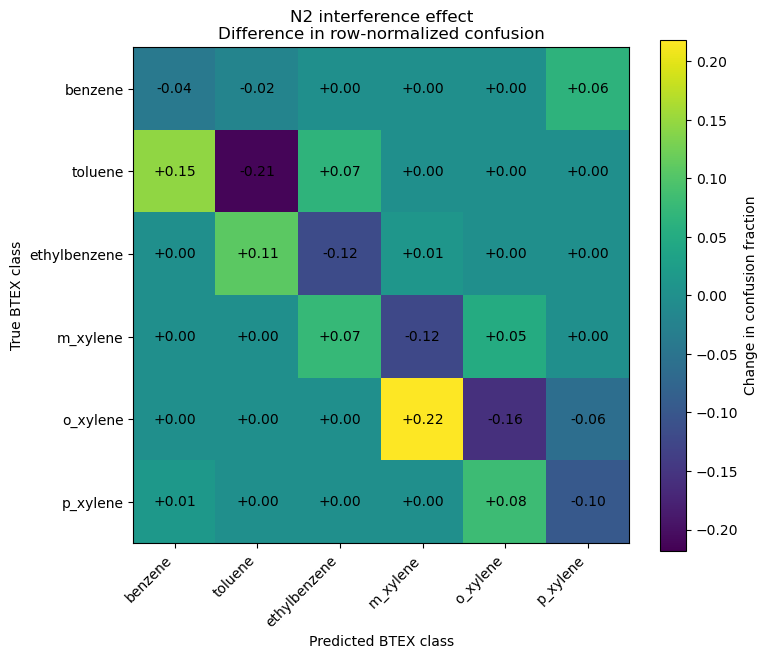

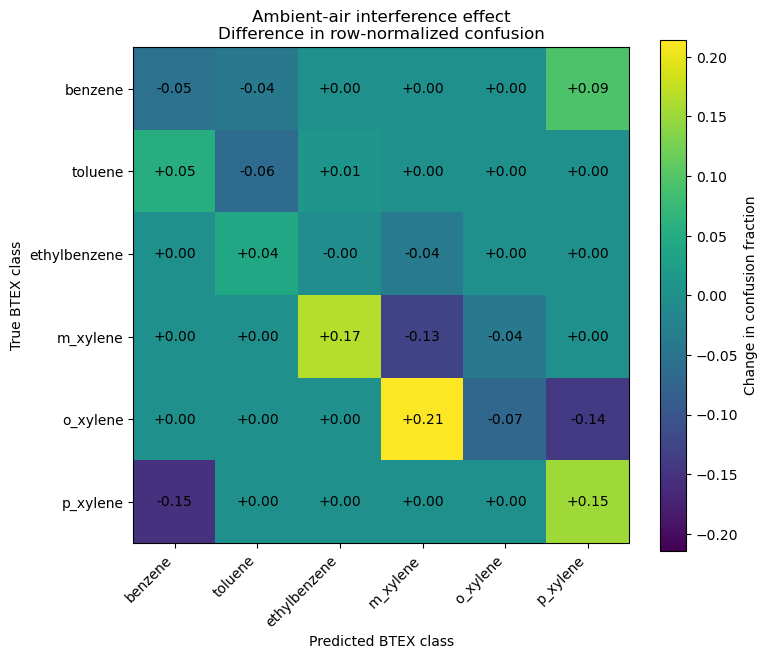

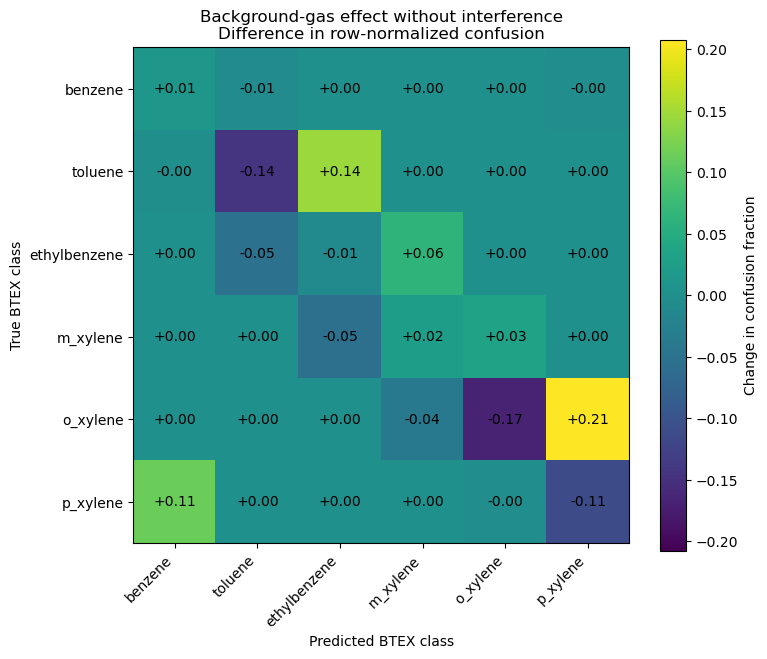

In [ ]:
# ===== Code from original cell 1 =====
# # Unified Sense–Memory CNN–BRNN Analysis
#
# Reorganized workflow for BTEX sequence classification, validation analyses, environmental robustness tests, mixture/history studies, and low-concentration calibration. Numerical records are read directly from the supplied CSV; source status should be verified against laboratory records before manuscript reporting.


# ================================================================
# UNIFIED SENSE–MEMORY CNN–BRNN
# ORGANIZED ANALYSIS NOTEBOOK
#
# Put this notebook and BOTH split CSV files in the SAME folder.
#
# Primary model:
# 4 differential sensing channels:
#   S1S5, S2S5, S3S5, S4S5
#
# Each channel contains:
#   IDS(t) + M(t)
#
# CNN:
#   learns spatial/cross-receptor features at each time point
#
# BRNN:
#   learns adsorption, recovery and memory dynamics over time
#
# Validation-specific analyses:
#   - full 1 ppb–10 ppm classification
#   - 1–10 ppb
#   - >10 ppb
#   - 1 ppb
#   - 10 ppb
#   - humidity
#   - temperature
#   - interferents
#   - drift
#   - BTEX mixtures
#   - previous exposure
#   - gate reset
#   - low-concentration calibration/repeatability
#   - ambient-air validation and N2 vs ambient-air comparison
#   - IDS-only vs IDS+M(t) ablation
#
# IMPORTANT:
# Auxiliary-validation rows are retained as an auxiliary validation block.
# Verify source status against laboratory records before manuscript reporting.
# ================================================================


# ================================================================
# 1. IMPORT LIBRARIES
# ================================================================

import os
import re
import json
import random
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Reshape,
    Conv1D,
    TimeDistributed,
    GlobalAveragePooling1D,
    BatchNormalization,
    Dropout,
    Bidirectional,
    GRU,
    Dense,
    GlobalMaxPooling1D,
    Concatenate
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)


# ================================================================
# 2. REPRODUCIBILITY
# ================================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)


# ================================================================
# 3. FILE NAME
# ================================================================
# Notebook and BOTH CSV parts should be in the SAME folder.

CSV_PATHS = [
    "USM_CNN_BRNN_N2_AMBIENT_part1.csv",
    "USM_CNN_BRNN_N2_AMBIENT_part2.csv",
]

missing_csv_files = [
    path for path in CSV_PATHS
    if not os.path.exists(path)
]

if missing_csv_files:

    raise FileNotFoundError(
        "\nOne or more CSV files were not found.\n"
        "Make sure this Jupyter notebook and BOTH CSV files are "
        "in the same folder:\n\n"
        + "\n".join(missing_csv_files)
    )

# ================================================================
# 4. OUTPUT FOLDER
# ================================================================

OUT_DIR = "CNN_BRNN_USM_VALIDATION_RESULTS"

os.makedirs(
    OUT_DIR,
    exist_ok=True
)


# ================================================================
# 5. MODEL SETTINGS
# ================================================================

BATCH_SIZE = 32

EPOCHS = 150

LEARNING_RATE = 2e-4

# Current sequences contain approximately 14–18 points.
# We interpolate each trajectory to 18 points rather than cutting
# everything to the shortest sequence.

FIXED_LEN = 18


# Set True for final validation analysis.
# This additionally trains:
#


# 1. IDS only


# 2. IDS + M(t)


# 3. IDS + M(t) + dIDS/dt
#
# It therefore requires substantially more training time.

RUN_ABLATIONS = True


# ================================================================
# 6. GAS CLASSES
# ================================================================

CLASS_NAMES = [

    "benzene",

    "toluene",

    "ethylbenzene",

    "m_xylene",

    "o_xylene",

    "p_xylene"
]


CLASS_TO_ID = {

    name: index

    for index, name

    in enumerate(CLASS_NAMES)
}


# ================================================================
# 7. VALIDATION BLOCKS
# ================================================================

CORE_BLOCK = "CORE_MANUSCRIPT_2160"

ENV_BLOCK = "ENVIRONMENTAL_ROBUSTNESS"

MIXTURE_BLOCK = "BTEX_MIXTURE"

HISTORY_BLOCK = "EXPOSURE_HISTORY_RESET"

LOW_CONC_BLOCK = "LOW_CONC_1PPB_CALIBRATION"


# ================================================================
# 8. PRIMARY CNN–BRNN FEATURES
# ================================================================
#
# Manuscript-consistent representation:
#
# receptor channel 1 = IDS + M(t)
# receptor channel 2 = IDS + M(t)
# receptor channel 3 = IDS + M(t)
# receptor channel 4 = IDS + M(t)
#
# Total = 8 features.
#
# Importantly:
#
# gas_label
# interferent_label
# mixture composition
# previous exposure identity
#
# are NOT input to the classifier.
#
# They are only used for stratified evaluation.
# ================================================================

PRIMARY_FEATURES = [

    "S1S5_IDS_norm",
    "S1S5_Mt_norm",

    "S2S5_IDS_norm",
    "S2S5_Mt_norm",

    "S3S5_IDS_norm",
    "S3S5_Mt_norm",

    "S4S5_IDS_norm",
    "S4S5_Mt_norm"
]


# ------------------------------------------------
# IDS-only control
# ------------------------------------------------

IDS_ONLY_FEATURES = [

    "S1S5_IDS_norm",

    "S2S5_IDS_norm",

    "S3S5_IDS_norm",

    "S4S5_IDS_norm"
]


# ------------------------------------------------
# Extended kinetic model
# ------------------------------------------------

EXTENDED_FEATURES = [

    "S1S5_IDS_norm",
    "S1S5_Mt_norm",
    "S1S5_dIDS_dt",

    "S2S5_IDS_norm",
    "S2S5_Mt_norm",
    "S2S5_dIDS_dt",

    "S3S5_IDS_norm",
    "S3S5_Mt_norm",
    "S3S5_dIDS_dt",

    "S4S5_IDS_norm",
    "S4S5_Mt_norm",
    "S4S5_dIDS_dt"
]


# ================================================================
# 9. LOAD DATASET
# ================================================================

# Read both split CSV files and reconstruct the original dataset.
# ignore_index=True creates one continuous row index without altering columns.
_data_parts = [
    pd.read_csv(path)
    for path in CSV_PATHS
]

# Safety check: both parts must contain exactly the same columns in the same order.
_reference_columns = list(_data_parts[0].columns)
for _path, _part in zip(CSV_PATHS[1:], _data_parts[1:]):
    if list(_part.columns) != _reference_columns:
        raise ValueError(
            f"Column mismatch detected in {_path}. "
            "Both CSV parts must have identical headers."
        )

df = pd.concat(
    _data_parts,
    axis=0,
    ignore_index=True
)

print(
    f"Loaded {len(CSV_PATHS)} CSV files: "
    f"{len(df):,} total rows, {len(df.columns)} columns."
)

del _data_parts

# ------------------------------------------------
# Reconstruct validation_block when using the aligned
# N2 + ambient-air dataset.
# ------------------------------------------------
if "validation_block" not in df.columns:

    def infer_validation_block(row):

        scenario = str(
            row.get(
                "environment_scenario",
                ""
            )
        )

        background = str(
            row.get(
                "background_gas",
                "N2"
            )
        )

        sample_type = str(
            row.get(
                "sample_type",
                ""
            )
        )

        if background == "ambient air":

            return "AMBIENT_AIR_VALIDATION"

        if scenario == "core_dataset_condition":

            return "CORE_MANUSCRIPT_2160"

        if scenario == "low_concentration_calibration":

            return "LOW_CONC_1PPB_CALIBRATION"

        if scenario == "mixture_clean_air" or sample_type == "BTEX_mixture_target_labeled":

            return "BTEX_MIXTURE"

        if scenario == "history_reset_control":

            return "EXPOSURE_HISTORY_RESET"

        return "ENVIRONMENTAL_ROBUSTNESS"


    df["validation_block"] = df.apply(
        infer_validation_block,
        axis=1
    )


print("\n==============================================")

print("DATASET")

print("==============================================")

print("Rows:", len(df))

print("Columns:", df.shape[1])

print(
    "Unique CNN–BRNN sequences:",
    df["sequence_id"].nunique()
)

print(
    "Unique physical/source exposure events:",
    df[
        [
            "source_sequence_id",
            "source_event_id"
        ]
    ]
    .drop_duplicates()
    .shape[0]
)


# ================================================================
# 10. VERIFY REQUIRED COLUMNS
# ================================================================

REQUIRED_COLUMNS = [

    "sequence_id",

    "source_sequence_id",

    "source_event_id",

    "time_index",

    "time_s",

    "gas_label",

    "concentration_ppb",

    "validation_block",

    "background_gas"
]


missing_required = [

    column

    for column

    in REQUIRED_COLUMNS

    if column not in df.columns
]


if missing_required:

    raise ValueError(

        "Missing required columns:\n"

        + str(
            missing_required
        )
    )


missing_features = [

    column

    for column

    in PRIMARY_FEATURES

    if column not in df.columns
]


if missing_features:

    raise ValueError(

        "Missing CNN–BRNN features:\n"

        + str(
            missing_features
        )
    )


# ================================================================
# 11. CHECK SEQUENCE NUMBER
# ================================================================

number_sequences = (
    df["sequence_id"].nunique()
)

print(
    "\nTotal CNN–BRNN sequences:",
    number_sequences
)

print(
    "N2 sequences:",
    df.loc[
        df["background_gas"] == "N2",
        "sequence_id"
    ].nunique()
)

print(
    "Ambient-air sequences:",
    df.loc[
        df["background_gas"] == "ambient air",
        "sequence_id"
    ].nunique()
)


# ================================================================
# 12. VALIDATION BLOCK SUMMARY
# ================================================================

block_summary = (

    df
    .groupby(
        "validation_block"
    )[
        "sequence_id"
    ]
    .nunique()
    .sort_values(
        ascending=False
    )
)


print(
    "\nSequences by validation block:"
)

print(
    block_summary
)


# ================================================================
# 13. VERIFY GAS LABELS
# ================================================================

unknown_classes = sorted(

    set(
        df[
            "gas_label"
        ]
        .dropna()
        .unique()
    )

    -

    set(
        CLASS_NAMES
    )
)


if unknown_classes:

    raise ValueError(

        "Unexpected gas classes found:\n"

        + str(
            unknown_classes
        )
    )


# ================================================================
# 14. DATA PROVENANCE
# ================================================================

if "record_status" in df.columns:

    print(
        "\nRecord status:"
    )

    print(

        df[
            "record_status"
        ]
        .value_counts(
            dropna=False
        )
    )


# ================================================================
# 15. SOURCE-EVENT-SAFE TRAIN / VALIDATION / TEST SPLIT
# ================================================================
#
# This section is critical for source-event-safe evaluation.
#
# ALL augmented windows generated from the same physical
# exposure event remain inside ONE partition.
#
# This prevents train/test leakage.
# ================================================================

EVENT_COLUMNS = [

    "source_sequence_id",

    "source_event_id"
]


event_table = (

    df

    .groupby(
        EVENT_COLUMNS,
        as_index=False
    )

    .agg(

        validation_block=(
            "validation_block",
            "first"
        ),

        gas_label=(
            "gas_label",
            "first"
        ),

        concentration_ppb=(
            "concentration_ppb",
            "first"
        )
    )
)


# ================================================================
# 16. STRATIFICATION VARIABLE
# ================================================================

event_table[
    "stratum"
] = (

    event_table[
        "validation_block"
    ]
    .astype(str)

    +

    "__"

    +

    event_table[
        "gas_label"
    ]
    .astype(str)
)


# ================================================================
# 17. 70/15/15 EVENT-LEVEL SPLIT
# ================================================================

train_events, temporary_events = (

    train_test_split(

        event_table,

        test_size=0.30,

        random_state=SEED,

        stratify=event_table[
            "stratum"
        ]
    )
)


validation_events, test_events = (

    train_test_split(

        temporary_events,

        test_size=0.50,

        random_state=SEED,

        stratify=temporary_events[
            "stratum"
        ]
    )
)


# ================================================================
# 18. EVENT KEY SETS
# ================================================================

def make_event_keys(
    frame
):

    return set(

        zip(

            frame[
                "source_sequence_id"
            ],

            frame[
                "source_event_id"
            ]
        )
    )


train_event_keys = (

    make_event_keys(
        train_events
    )
)


validation_event_keys = (

    make_event_keys(
        validation_events
    )
)


test_event_keys = (

    make_event_keys(
        test_events
    )
)


# ================================================================
# 19. ASSIGN SPLIT TO EVERY TIME-POINT ROW
# ================================================================

def assign_analysis_split(
    row
):

    key = (

        row[
            "source_sequence_id"
        ],

        row[
            "source_event_id"
        ]
    )


    if key in train_event_keys:

        return "train"


    if key in validation_event_keys:

        return "validation"


    if key in test_event_keys:

        return "test"


    raise RuntimeError(

        "Unassigned source event: "

        + str(
            key
        )
    )


df[
    "analysis_split"
] = (

    df.apply(

        assign_analysis_split,

        axis=1
    )
)


# ================================================================
# 20. LEAKAGE CHECK
# ================================================================

event_partition_counts = (

    df

    .groupby(
        EVENT_COLUMNS
    )[
        "analysis_split"
    ]

    .nunique()
)


assert (

    event_partition_counts.max()
    == 1

), (

    "TRAIN/TEST LEAKAGE DETECTED: "

    "one physical exposure event appears in multiple partitions."
)


sequence_partition_counts = (

    df

    .groupby(
        "sequence_id"
    )[
        "analysis_split"
    ]

    .nunique()
)


assert (

    sequence_partition_counts.max()
    == 1

), (

    "TRAIN/TEST LEAKAGE DETECTED: "

    "one CNN–BRNN sequence appears in multiple partitions."
)


print(
    "\n=============================================="
)

print(
    "LEAKAGE CHECK PASSED"
)

print(
    "=============================================="
)

print(

    "Maximum number of partitions for any exposure event:",

    event_partition_counts.max()
)


# ================================================================
# 21. CREATE SEQUENCE MANIFEST
# ================================================================

sequence_manifest = (

    df

    .groupby(
        "sequence_id",
        as_index=False
    )

    .agg(

        analysis_split=(
            "analysis_split",
            "first"
        ),

        validation_block=(
            "validation_block",
            "first"
        ),

        gas_label=(
            "gas_label",
            "first"
        ),

        concentration_ppb=(
            "concentration_ppb",
            "first"
        ),

        source_sequence_id=(
            "source_sequence_id",
            "first"
        ),

        source_event_id=(
            "source_event_id",
            "first"
        ),

        background_gas=(
            "background_gas",
            "first"
        )
    )
)


print(
    "\nSequence partition summary:"
)


print(

    sequence_manifest

    .groupby(

        [
            "validation_block",
            "analysis_split"
        ]

    )

    .size()

    .unstack(
        fill_value=0
    )
)


sequence_manifest.to_csv(

    os.path.join(

        OUT_DIR,

        "sequence_manifest_group_safe.csv"
    ),

    index=False
)


# ================================================================
# 22. RESAMPLE DIFFERENT SEQUENCE LENGTHS
# ================================================================
#
# Do not truncate all signals to the shortest trajectory.
#
# Instead, interpolate each physical trajectory to a common
# 18-time-point representation.
# ================================================================

def resample_sequence(

    values,

    fixed_length=FIXED_LEN
):

    values = np.asarray(

        values,

        dtype=np.float32
    )


    original_length = (

        values.shape[0]
    )


    number_features = (

        values.shape[1]
    )


    if original_length == fixed_length:

        return values.copy()


    original_axis = np.linspace(

        0.0,

        1.0,

        original_length
    )


    new_axis = np.linspace(

        0.0,

        1.0,

        fixed_length
    )


    interpolated = np.empty(

        (

            fixed_length,

            number_features

        ),

        dtype=np.float32
    )


    for feature_index in range(

        number_features
    ):


        interpolated[

            :,

            feature_index

        ] = np.interp(

            new_axis,

            original_axis,

            values[
                :,
                feature_index
            ]
        )


    return interpolated


# ================================================================
# 23. BUILD CNN–BRNN SEQUENCES
# ================================================================

def build_sequence_dataset(

    dataframe,

    feature_columns
):


    records = []


    for sequence_id, subframe in dataframe.groupby(

        "sequence_id",

        sort=False
    ):


        subframe = (

            subframe

            .sort_values(

                [
                    "time_index",
                    "time_s"
                ]
            )

        )


        signal_matrix = (

            subframe[
                feature_columns
            ]

            .astype(float)

            .values
        )


        signal_matrix = resample_sequence(

            signal_matrix,

            fixed_length=FIXED_LEN
        )


        first = (

            subframe.iloc[0]
        )


        record = {

            "sequence_id":
                sequence_id,

            "X":
                signal_matrix,

            "gas_label":
                first[
                    "gas_label"
                ],

            "y":
                CLASS_TO_ID[
                    first[
                        "gas_label"
                    ]
                ],

            "analysis_split":
                first[
                    "analysis_split"
                ],

            "validation_block":
                first[
                    "validation_block"
                ],

            "concentration_ppb":
                float(
                    first[
                        "concentration_ppb"
                    ]
                ),

            "source_sequence_id":
                first[
                    "source_sequence_id"
                ],

            "source_event_id":
                first[
                    "source_event_id"
                ],

            "background_gas":
                first[
                    "background_gas"
                ]
        }


        # --------------------------------------------
        # Metadata used ONLY for subgroup evaluation.
        # --------------------------------------------

        metadata_columns = [

            "RH_percent",

            "temperature_C",

            "interferent_label",

            "interferent_concentration_ppb",

            "ambient_condition_id",

            "device_id",

            "batch_id",

            "day_id",

            "drift_time_h",

            "sample_type",

            "mixture_id",

            "benzene_ppb",

            "toluene_ppb",

            "ethylbenzene_ppb",

            "m_xylene_ppb",

            "o_xylene_ppb",

            "p_xylene_ppb",

            "total_BTEX_ppb",

            "mixture_component_count",

            "previous_exposure_label",

            "previous_exposure_concentration_ppb",

            "previous_exposure_mixture_id",

            "previous_gate_reset",

            "gate_reset",

            "recovery_time_s",

            "cycle_number",

            "history_condition_id",

            "calibration_nominal_ppb",

            "environment_scenario",

            "experimental_design_id",

            "record_status",

            "use_for_six_class_classifier",

        ]


        for column in metadata_columns:


            if column in subframe.columns:

                record[
                    column
                ] = first[
                    column
                ]


        records.append(
            record
        )


    # ------------------------------------------------
    # X tensor
    # ------------------------------------------------

    X = np.stack(

        [

            item[
                "X"
            ]

            for item

            in records
        ]

    ).astype(
        np.float32
    )


    # ------------------------------------------------
    # Sequence metadata
    # ------------------------------------------------

    metadata = pd.DataFrame(

        [

            {

                key: value

                for key, value

                in item.items()

                if key != "X"
            }

            for item

            in records
        ]
    )


    y = (

        metadata[
            "y"
        ]

        .to_numpy(

            dtype=np.int64
        )
    )


    return (

        X,

        y,

        metadata
    )


# ================================================================
# 24. BUILD PRIMARY 8-FEATURE INPUT
# ================================================================

X_all_raw, y_all, metadata_all = (

    build_sequence_dataset(

        df,

        PRIMARY_FEATURES
    )
)


print(
    "\n=============================================="
)

print(
    "CNN–BRNN INPUT"
)

print(
    "=============================================="
)

print(
    "X shape:",
    X_all_raw.shape
)

print(

    "Interpretation:"

)

print(

    X_all_raw.shape[0],
    "sequences ×",

    X_all_raw.shape[1],
    "time points ×",

    X_all_raw.shape[2],
    "features"
)


# ================================================================
# 25. DEFINE CORE MANUSCRIPT TRAINING MASKS
# ================================================================
#
# Primary classifier is trained on the original core manuscript
# dataset.
#
# Validation blocks remain independent challenges.
# ================================================================

core_train_mask = (

    (
        metadata_all[
            "validation_block"
        ]
        == CORE_BLOCK
    )

    &

    (
        metadata_all[
            "background_gas"
        ]
        == "N2"
    )

    &

    (
        metadata_all[
            "analysis_split"
        ]
        == "train"
    )
)


core_validation_mask = (

    (
        metadata_all[
            "validation_block"
        ]
        == CORE_BLOCK
    )

    &

    (
        metadata_all[
            "background_gas"
        ]
        == "N2"
    )

    &

    (
        metadata_all[
            "analysis_split"
        ]
        == "validation"
    )
)


core_test_mask = (

    (
        metadata_all[
            "validation_block"
        ]
        == CORE_BLOCK
    )

    &

    (
        metadata_all[
            "background_gas"
        ]
        == "N2"
    )

    &

    (
        metadata_all[
            "analysis_split"
        ]
        == "test"
    )
)


print(
    "\nCore manuscript sequences:"
)

print(
    "Train:",
    core_train_mask.sum()
)

print(
    "Validation:",
    core_validation_mask.sum()
)

print(
    "Test:",
    core_test_mask.sum()
)


# ================================================================
# 26. STANDARDIZE FEATURES
# ================================================================
#
# IMPORTANT:
# Fit scaler ONLY using training sequences.
# ================================================================

scaler = StandardScaler()


training_values = (

    X_all_raw[
        core_train_mask
    ]

    .reshape(

        -1,

        X_all_raw.shape[-1]
    )
)


scaler.fit(
    training_values
)


def transform_3d(
    X
):

    shape = (

        X.shape
    )


    transformed = (

        scaler.transform(

            X.reshape(

                -1,

                shape[-1]
            )

        )

        .reshape(
            shape
        )

    )


    return transformed.astype(

        np.float32
    )


X_all = transform_3d(

    X_all_raw
)


X_train = (

    X_all[
        core_train_mask
    ]
)


y_train = (

    y_all[
        core_train_mask
    ]
)


X_validation = (

    X_all[
        core_validation_mask
    ]
)


y_validation = (

    y_all[
        core_validation_mask
    ]
)


X_test = (

    X_all[
        core_test_mask
    ]
)


y_test = (

    y_all[
        core_test_mask
    ]
)


print(
    "\nScaled tensors:"
)

print(
    "Training:",
    X_train.shape
)

print(
    "Validation:",
    X_validation.shape
)

print(
    "Testing:",
    X_test.shape
)


# ================================================================
# 27. SAVE SCALER
# ================================================================

scaler_dataframe = pd.DataFrame(

    {

        "feature":
            PRIMARY_FEATURES,

        "mean":
            scaler.mean_,

        "scale":
            scaler.scale_
    }
)


scaler_dataframe.to_csv(

    os.path.join(

        OUT_DIR,

        "primary_feature_scaler.csv"
    ),

    index=False
)


# ================================================================
# 28. CLASS WEIGHTS
# ================================================================

present_classes = (

    np.unique(
        y_train
    )
)


class_weights = (

    compute_class_weight(

        class_weight="balanced",

        classes=present_classes,

        y=y_train
    )
)


class_weight_dictionary = {

    int(
        class_id
    ):
        float(
            weight
        )

    for class_id, weight

    in zip(

        present_classes,

        class_weights
    )
}


print(
    "\nClass weights:"
)

print(
    class_weight_dictionary
)


# ================================================================
# 29. BUILD SPATIAL CNN + TEMPORAL BRNN
# ================================================================
#
# Input:
#
# T × 8
#
# Internally reshaped to:
#
# T × 4 receptor channels × 2 physical features
#
# CNN therefore operates across the FOUR receptor channels
# at each time point.
#
# BRNN subsequently operates across TIME.
# ================================================================

def build_spatial_cnn_brnn(

    fixed_len,

    number_input_features,

    features_per_receptor,

    number_classes=6,

    model_name="USM_SpatialCNN_BRNN"
):


    number_receptors = (

        number_input_features

        //

        features_per_receptor
    )


    inputs = Input(

        shape=(

            fixed_len,

            number_input_features

        ),

        name="USM_input"
    )


    # --------------------------------------------------------
    # Reshape:
    #
    # batch × time × receptor × receptor-feature
    # --------------------------------------------------------

    x = Reshape(

        (

            fixed_len,

            number_receptors,

            features_per_receptor

        ),

        name="reshape_time_receptor_feature"

    )(inputs)


    # --------------------------------------------------------
    # CNN across receptor nodes at each time point.
    # --------------------------------------------------------

    x = TimeDistributed(

        Conv1D(

            filters=32,

            kernel_size=2,

            padding="same",

            activation="relu"
        ),

        name="spatial_CNN_1"

    )(x)


    x = TimeDistributed(

        BatchNormalization(),

        name="spatial_BN_1"

    )(x)


    x = TimeDistributed(

        Conv1D(

            filters=64,

            kernel_size=2,

            padding="same",

            activation="relu"
        ),

        name="spatial_CNN_2"

    )(x)


    x = TimeDistributed(

        GlobalAveragePooling1D(),

        name="spatial_receptor_pooling"

    )(x)


    x = Dropout(

        0.20,

        name="spatial_dropout"

    )(x)


    # --------------------------------------------------------
    # Bidirectional temporal learning
    # --------------------------------------------------------

    x = Bidirectional(

        GRU(

            64,

            return_sequences=True

        ),

        name="BRNN_1"

    )(x)


    x = Dropout(

        0.25,

        name="BRNN_dropout_1"

    )(x)


    x = Bidirectional(

        GRU(

            32,

            return_sequences=True

        ),

        name="BRNN_2"

    )(x)


    # --------------------------------------------------------
    # Global temporal representation
    # --------------------------------------------------------

    average_pooling = (

        GlobalAveragePooling1D(

            name="temporal_average_pooling"

        )(x)
    )


    maximum_pooling = (

        GlobalMaxPooling1D(

            name="temporal_max_pooling"

        )(x)
    )


    x = Concatenate(

        name="temporal_feature_fusion"

    )(

        [

            average_pooling,

            maximum_pooling

        ]
    )


    # --------------------------------------------------------
    # Classification head
    # --------------------------------------------------------

    x = Dense(

        128,

        activation="relu",

        name="dense_128"

    )(x)


    x = Dropout(

        0.30,

        name="dense_dropout_1"

    )(x)


    x = Dense(

        64,

        activation="relu",

        name="dense_64"

    )(x)


    x = Dropout(

        0.20,

        name="dense_dropout_2"

    )(x)


    outputs = Dense(

        number_classes,

        activation="softmax",

        name="BTEX_output"

    )(x)


    model = Model(

        inputs=inputs,

        outputs=outputs,

        name=model_name
    )


    model.compile(

        optimizer=tf.keras.optimizers.Adam(

            learning_rate=LEARNING_RATE
        ),

        loss=(

            tf.keras.losses
            .SparseCategoricalCrossentropy()

        ),

        metrics=[

            "accuracy"
        ]
    )


    return model


# ================================================================
# 30. PRIMARY MODEL
# ================================================================
#
# 8 features =
#
# 4 receptor nodes × 2 variables:
#
# IDS(t)
# M(t)
# ================================================================

model = build_spatial_cnn_brnn(

    fixed_len=FIXED_LEN,

    number_input_features=len(
        PRIMARY_FEATURES
    ),

    features_per_receptor=2,

    number_classes=len(
        CLASS_NAMES
    ),

    model_name="USM_IDS_Memory_CNN_BRNN"
)


model.summary()


# ================================================================
# 31. CALLBACKS
# ================================================================

BEST_MODEL_PATH = os.path.join(

    OUT_DIR,

    "best_USM_IDS_Memory_CNN_BRNN.keras"
)


callbacks = [


    EarlyStopping(

        monitor="val_accuracy",

        mode="max",

        patience=25,

        restore_best_weights=False,

        verbose=1
    ),


    ReduceLROnPlateau(

        monitor="val_loss",

        mode="min",

        factor=0.5,

        patience=8,

        min_lr=1e-6,

        verbose=1
    ),


    ModelCheckpoint(

        BEST_MODEL_PATH,

        monitor="val_accuracy",

        mode="max",

        save_best_only=True,

        verbose=1
    )
]


# ================================================================
# 32. TRAIN PRIMARY CNN–BRNN
# ================================================================

print(
    "\n=============================================="
)

print(
    "TRAINING PRIMARY IDS + M(t) CNN–BRNN"
)

print(
    "=============================================="
)


history = model.fit(

    X_train,

    y_train,

    validation_data=(

        X_validation,

        y_validation
    ),

    epochs=EPOCHS,

    batch_size=BATCH_SIZE,

    class_weight=(

        class_weight_dictionary
    ),

    callbacks=callbacks,

    verbose=1
)


# ================================================================
# 33. SAVE TRAINING HISTORY
# ================================================================

history_dataframe = (

    pd.DataFrame(

        history.history
    )
)


history_dataframe[

    "epoch"

] = (

    np.arange(

        1,

        len(
            history_dataframe
        )

        + 1
    )
)


history_dataframe.to_csv(

    os.path.join(

        OUT_DIR,

        "training_history.csv"
    ),

    index=False
)


best_epoch_index = (

    history_dataframe[
        "val_accuracy"
    ]

    .idxmax()
)


best_epoch = (

    int(

        history_dataframe.loc[

            best_epoch_index,

            "epoch"
        ]
    )
)


best_validation_accuracy = (

    float(

        history_dataframe.loc[

            best_epoch_index,

            "val_accuracy"
        ]
    )
)


print(
    "\nBest epoch:",
    best_epoch
)


print(
    "Best validation accuracy:",
    best_validation_accuracy
)


# ================================================================
# 34. TRAINING LOSS FIGURE
# ================================================================

plt.figure(

    figsize=(

        7,

        5
    )
)


plt.plot(

    history_dataframe[
        "epoch"
    ],

    history_dataframe[
        "loss"
    ],

    label="Training"
)


plt.plot(

    history_dataframe[
        "epoch"
    ],

    history_dataframe[
        "val_loss"
    ],

    label="Validation"
)


plt.axvline(

    best_epoch,

    linestyle="--",

    label=(

        f"Best epoch = "
        f"{best_epoch}"
    )
)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "CNN–BRNN Training and Validation Loss"
)

plt.legend()

plt.grid(
    alpha=0.25
)

plt.tight_layout()


plt.savefig(

    os.path.join(

        OUT_DIR,

        "training_validation_loss.png"
    ),

    dpi=300
)


plt.show()


# ================================================================
# 35. TRAINING ACCURACY FIGURE
# ================================================================

plt.figure(

    figsize=(

        7,

        5
    )
)


plt.plot(

    history_dataframe[
        "epoch"
    ],

    history_dataframe[
        "accuracy"
    ],

    label="Training"
)


plt.plot(

    history_dataframe[
        "epoch"
    ],

    history_dataframe[
        "val_accuracy"
    ],

    label="Validation"
)


plt.axvline(

    best_epoch,

    linestyle="--",

    label=(

        f"Best epoch = "
        f"{best_epoch}"
    )
)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "CNN–BRNN Training and Validation Accuracy"
)

plt.legend()

plt.grid(
    alpha=0.25
)

plt.tight_layout()


plt.savefig(

    os.path.join(

        OUT_DIR,

        "training_validation_accuracy.png"
    ),

    dpi=300
)


plt.show()


# ================================================================
# 36. LOAD BEST MODEL
# ================================================================

best_model = (

    tf.keras.models.load_model(

        BEST_MODEL_PATH
    )
)


# ================================================================
# 37. PREDICTION FUNCTION
# ================================================================

def predict_subset(

    mask
):


    indices = np.where(

        np.asarray(
            mask
        )

    )[0]


    if len(
        indices
    ) == 0:

        return pd.DataFrame()


    probabilities = (

        best_model.predict(

            X_all[
                indices
            ],

            verbose=0
        )
    )


    predicted = (

        np.argmax(

            probabilities,

            axis=1
        )
    )


    actual = (

        y_all[
            indices
        ]
    )


    results = (

        metadata_all

        .iloc[
            indices
        ]

        .copy()

        .reset_index(
            drop=True
        )
    )


    results[
        "y_true"
    ] = actual


    results[
        "y_pred"
    ] = predicted


    results[
        "true_label"
    ] = [

        CLASS_NAMES[
            value
        ]

        for value

        in actual
    ]


    results[
        "pred_label"
    ] = [

        CLASS_NAMES[
            value
        ]

        for value

        in predicted
    ]


    results[
        "correct"
    ] = (

        actual

        ==

        predicted

    ).astype(int)


    results[
        "confidence"
    ] = (

        probabilities.max(

            axis=1
        )
    )


    for class_index, class_name in enumerate(

        CLASS_NAMES
    ):


        results[

            "prob_"
            + class_name

        ] = probabilities[

            :,

            class_index
        ]


    return results


# ================================================================
# 38. METRIC FUNCTION
# ================================================================

def calculate_metrics(

    subset_name,

    results
):


    if results.empty:


        return {

            "subset":
                subset_name,

            "n":
                0,

            "accuracy":
                np.nan,

            "macro_f1":
                np.nan,

            "macro_precision":
                np.nan,

            "macro_recall":
                np.nan
        }


    y_true = (

        results[
            "y_true"
        ]
        .to_numpy()
    )


    y_pred = (

        results[
            "y_pred"
        ]
        .to_numpy()
    )


    return {

        "subset":
            subset_name,

        "n":
            len(
                results
            ),

        "accuracy":

            accuracy_score(

                y_true,

                y_pred
            ),

        "macro_f1":

            f1_score(

                y_true,

                y_pred,

                average="macro",

                zero_division=0
            ),

        "macro_precision":

            precision_score(

                y_true,

                y_pred,

                average="macro",

                zero_division=0
            ),

        "macro_recall":

            recall_score(

                y_true,

                y_pred,

                average="macro",

                zero_division=0
            )
    }


# ================================================================
# 39. CONFUSION MATRIX FUNCTION
# ================================================================

def create_confusion_matrix(

    results,

    title,

    output_name
):


    if results.empty:


        print(

            "No samples available for:",

            title
        )


        return


    overall_accuracy = (
        accuracy_score(
            results["y_true"],
            results["y_pred"]
        )
        * 100.0
    )

    matrix = confusion_matrix(

        results[
            "y_true"
        ],

        results[
            "y_pred"
        ],

        labels=np.arange(

            len(
                CLASS_NAMES
            )
        )
    )


    row_sum = (

        matrix.sum(

            axis=1,

            keepdims=True
        )
        .astype(float)
    )


    row_sum[
        row_sum == 0
    ] = 1


    matrix_percent = (

        matrix

        /

        row_sum

        *

        100
    )


    # ------------------------------------------------
    # Save numerical matrix
    # ------------------------------------------------

    pd.DataFrame(

        matrix,

        index=CLASS_NAMES,

        columns=CLASS_NAMES

    ).to_csv(

        os.path.join(

            OUT_DIR,

            output_name
            + "_counts.csv"
        )
    )


    pd.DataFrame(

        matrix_percent,

        index=CLASS_NAMES,

        columns=CLASS_NAMES

    ).to_csv(

        os.path.join(

            OUT_DIR,

            output_name
            + "_percent.csv"
        )
    )


    pd.DataFrame(
        [{
            "condition": title,
            "n_samples": len(results),
            "average_accuracy_percent": overall_accuracy
        }]
    ).to_csv(
        os.path.join(
            OUT_DIR,
            output_name + "_summary.csv"
        ),
        index=False
    )


    # ------------------------------------------------
    # Plot
    # ------------------------------------------------

    plt.figure(

        figsize=(

            8,

            7
        )
    )


    plt.imshow(

        matrix_percent,

        vmin=0,

        vmax=100
    )


    plt.colorbar(

        label="Percentage (%)"
    )


    plt.xticks(

        np.arange(

            len(
                CLASS_NAMES
            )
        ),

        CLASS_NAMES,

        rotation=45,

        ha="right"
    )


    plt.yticks(

        np.arange(

            len(
                CLASS_NAMES
            )
        ),

        CLASS_NAMES
    )


    plt.xlabel(
        "Predicted BTEX"
    )


    plt.ylabel(
        "True BTEX"
    )


    plt.title(
        title
        + f"\nAverage accuracy = {overall_accuracy:.1f}%"
    )


    for row in range(

        matrix_percent.shape[0]
    ):


        for column in range(

            matrix_percent.shape[1]
        ):


            plt.text(

                column,

                row,

                (
                    f"{matrix_percent[row, column]:.1f}%"
                ),

                ha="center",

                va="center"
            )


    plt.tight_layout()


    plt.savefig(

        os.path.join(

            OUT_DIR,

            output_name
            + ".png"
        ),

        dpi=300
    )


    plt.show()


# ================================================================
# 40. CORE MANUSCRIPT TEST RESULTS
# ================================================================

core_results = (

    predict_subset(

        core_test_mask
    )
)


core_results.to_csv(

    os.path.join(

        OUT_DIR,

        "core_test_predictions.csv"
    ),

    index=False
)


core_metric = pd.DataFrame(

    [

        calculate_metrics(

            "Core 1 ppb–10 ppm",

            core_results
        )

    ]
)


print(
    "\n=============================================="
)

print(
    "CORE MANUSCRIPT MODEL"
)

print(
    "=============================================="
)


print(

    core_metric.to_string(

        index=False
    )
)


print(
    "\nClassification report:"
)


print(

    classification_report(

        core_results[
            "y_true"
        ],

        core_results[
            "y_pred"
        ],

        labels=np.arange(

            len(
                CLASS_NAMES
            )
        ),

        target_names=CLASS_NAMES,

        digits=4,

        zero_division=0
    )
)


create_confusion_matrix(

    core_results,

    "CNN–BRNN BTEX Recognition: 1 ppb–10 ppm",

    "CM_core_full_range"
)


# ================================================================
# 41. PERFORMANCE AT EACH CONCENTRATION
# ================================================================

concentration_results = []


unique_concentrations = sorted(

    core_results[

        "concentration_ppb"

    ]
    .dropna()
    .unique()
)


for concentration in unique_concentrations:


    subset = core_results[

        np.isclose(

            core_results[
                "concentration_ppb"
            ]
            .astype(float),

            float(
                concentration
            )
        )

    ]


    metric = (

        calculate_metrics(

            str(
                concentration
            )
            + " ppb",

            subset
        )
    )


    metric[

        "concentration_ppb"

    ] = concentration


    concentration_results.append(

        metric
    )


concentration_results = (

    pd.DataFrame(

        concentration_results
    )
)


concentration_results.to_csv(

    os.path.join(

        OUT_DIR,

        "metrics_by_concentration.csv"
    ),

    index=False
)


print(
    "\n=============================================="
)

print(
    "CONCENTRATION-SPECIFIC PERFORMANCE"
)

print(
    "=============================================="
)


print(

    concentration_results[

        [

            "concentration_ppb",

            "n",

            "accuracy",

            "macro_f1",

            "macro_precision",

            "macro_recall"
        ]

    ].to_string(

        index=False
    )
)


# ================================================================
# 42. LOW-CONCENTRATION GROUP: 1–10 ppb
# ================================================================

low_ppb_results = core_results[

    (
        core_results[
            "concentration_ppb"
        ]
        >= 1
    )

    &

    (
        core_results[
            "concentration_ppb"
        ]
        <= 10
    )

].copy()


# ================================================================
# 43. >10 ppb GROUP
# ================================================================

higher_ppb_results = core_results[

    core_results[
        "concentration_ppb"
    ]
    > 10

].copy()


# ================================================================
# 44. EXACTLY 1 ppb
# ================================================================

one_ppb_results = core_results[

    np.isclose(

        core_results[
            "concentration_ppb"
        ],

        1.0
    )

].copy()


# ================================================================
# 45. EXACTLY 10 ppb
# ================================================================

ten_ppb_results = core_results[

    np.isclose(

        core_results[
            "concentration_ppb"
        ],

        10.0
    )

].copy()


# ================================================================
# 46. LOW vs HIGH SUMMARY
# ================================================================

range_metrics = pd.DataFrame(

    [

        calculate_metrics(

            "1–10 ppb",

            low_ppb_results
        ),

        calculate_metrics(

            ">10 ppb",

            higher_ppb_results
        ),

        calculate_metrics(

            "1 ppb",

            one_ppb_results
        ),

        calculate_metrics(

            "10 ppb",

            ten_ppb_results
        )

    ]
)


range_metrics.to_csv(

    os.path.join(

        OUT_DIR,

        "low_ppb_vs_higher_ppb_metrics.csv"
    ),

    index=False
)


print(
    "\n=============================================="
)

print(
    "LOW- vs HIGH-CONCENTRATION PERFORMANCE"
)

print(
    "=============================================="
)


print(

    range_metrics.to_string(

        index=False
    )
)


# ================================================================
# 47. CONCENTRATION-SPECIFIC CONFUSION MATRICES
# ================================================================

create_confusion_matrix(

    one_ppb_results,

    "CNN–BRNN BTEX Recognition at 1 ppb",

    "CM_1ppb"
)


create_confusion_matrix(

    ten_ppb_results,

    "CNN–BRNN BTEX Recognition at 10 ppb",

    "CM_10ppb"
)


create_confusion_matrix(

    low_ppb_results,

    "CNN–BRNN BTEX Recognition: 1–10 ppb",

    "CM_1_to_10ppb"
)


create_confusion_matrix(

    higher_ppb_results,

    "CNN–BRNN BTEX Recognition: >10 ppb",

    "CM_above_10ppb"
)


# ================================================================
# 48. AUXILIARY-VALIDATION TEST SET
# ================================================================
#
# These data are not mixed into the main training result.
# They provide independent validation-oriented challenge analyses.
# ================================================================

auxiliary_test_mask = (

    (
        metadata_all[
            "validation_block"
        ]
        != CORE_BLOCK
    )

    &

    (
        metadata_all[
            "analysis_split"
        ]
        == "test"
    )
)


auxiliary_results = (

    predict_subset(

        auxiliary_test_mask
    )
)


auxiliary_results.to_csv(

    os.path.join(

        OUT_DIR,

        "auxiliary_validation_predictions.csv"
    ),

    index=False
)


# ================================================================
# 49. VALIDATION-BLOCK PERFORMANCE
# ================================================================

validation_block_metrics = []


for block_name, block_results in auxiliary_results.groupby(

    "validation_block"
):


    evaluation_results = (

        block_results.copy()
    )


    # ----------------------------------------------
    # Blank calibration has no true gas identity.
    # Do not count 0 ppb blank in six-class accuracy.
    # ----------------------------------------------

    if (

        block_name == LOW_CONC_BLOCK

        and

        "calibration_nominal_ppb"

        in evaluation_results.columns

    ):


        calibration_values = (

            pd.to_numeric(

                evaluation_results[
                    "calibration_nominal_ppb"
                ],

                errors="coerce"
            )
        )


        evaluation_results = (

            evaluation_results[

                calibration_values
                > 0

            ]
        )


    validation_block_metrics.append(

        calculate_metrics(

            block_name,

            evaluation_results
        )
    )


validation_block_metrics = (

    pd.DataFrame(

        validation_block_metrics
    )
)


validation_block_metrics.to_csv(

    os.path.join(

        OUT_DIR,

        "validation_block_metrics.csv"
    ),

    index=False
)


print(
    "\n=============================================="
)

print(
    "AUXILIARY-VALIDATION PERFORMANCE"
)

print(
    "=============================================="
)


print(

    validation_block_metrics.to_string(

        index=False
    )
)


# ================================================================
# 50. ENVIRONMENTAL ROBUSTNESS
# ================================================================

environmental_results = auxiliary_results[

    auxiliary_results[
        "validation_block"
    ]
    == ENV_BLOCK

].copy()


print(
    "\n=============================================="
)

print(
    "ENVIRONMENTAL ROBUSTNESS"
)

print(
    "=============================================="
)


# ================================================================
# 51. PERFORMANCE BY HUMIDITY
# ================================================================

if (

    not environmental_results.empty

    and

    "RH_percent"
    in environmental_results.columns

):


    humidity_table = (

        environmental_results

        .groupby(
            "RH_percent"
        )

        .agg(

            n=(
                "correct",
                "size"
            ),

            accuracy=(
                "correct",
                "mean"
            ),

            mean_confidence=(
                "confidence",
                "mean"
            )

        )

        .reset_index()
    )


    humidity_table.to_csv(

        os.path.join(

            OUT_DIR,

            "environment_humidity.csv"
        ),

        index=False
    )


    print(
        "\nHumidity:"
    )


    print(

        humidity_table.to_string(

            index=False
        )
    )


# ================================================================
# 52. PERFORMANCE BY TEMPERATURE
# ================================================================

if (

    not environmental_results.empty

    and

    "temperature_C"
    in environmental_results.columns

):


    temperature_table = (

        environmental_results

        .groupby(
            "temperature_C"
        )

        .agg(

            n=(
                "correct",
                "size"
            ),

            accuracy=(
                "correct",
                "mean"
            ),

            mean_confidence=(
                "confidence",
                "mean"
            )

        )

        .reset_index()
    )


    temperature_table.to_csv(

        os.path.join(

            OUT_DIR,

            "environment_temperature.csv"
        ),

        index=False
    )


    print(
        "\nTemperature:"
    )


    print(

        temperature_table.to_string(

            index=False
        )
    )


# ================================================================
# 53. PERFORMANCE BY INTERFERENT
# ================================================================

if (

    not environmental_results.empty

    and

    "interferent_label"
    in environmental_results.columns

):


    interferent_table = (

        environmental_results

        .groupby(
            "interferent_label"
        )

        .agg(

            n=(
                "correct",
                "size"
            ),

            accuracy=(
                "correct",
                "mean"
            ),

            mean_confidence=(
                "confidence",
                "mean"
            )

        )

        .reset_index()
    )


    interferent_table.to_csv(

        os.path.join(

            OUT_DIR,

            "environment_interferents.csv"
        ),

        index=False
    )


    print(
        "\nInterferents:"
    )


    print(

        interferent_table.to_string(

            index=False
        )
    )


# ================================================================
# 54. PERFORMANCE BY ENVIRONMENTAL SCENARIO
# ================================================================

if (

    not environmental_results.empty

    and

    "environment_scenario"
    in environmental_results.columns

):


    scenario_table = (

        environmental_results

        .groupby(
            "environment_scenario"
        )

        .agg(

            n=(
                "correct",
                "size"
            ),

            accuracy=(
                "correct",
                "mean"
            ),

            mean_confidence=(
                "confidence",
                "mean"
            )

        )

        .reset_index()
    )


    scenario_table.to_csv(

        os.path.join(

            OUT_DIR,

            "environment_scenarios.csv"
        ),

        index=False
    )


    print(
        "\nEnvironmental scenario:"
    )


    print(

        scenario_table.to_string(

            index=False
        )
    )


# ================================================================
# 55. DRIFT ROBUSTNESS
# ================================================================

if (

    not environmental_results.empty

    and

    "drift_time_h"
    in environmental_results.columns

):


    environmental_results[

        "drift_time_h"

    ] = (

        pd.to_numeric(

            environmental_results[
                "drift_time_h"
            ],

            errors="coerce"
        )
    )


    drift_table = (

        environmental_results

        .groupby(
            "drift_time_h"
        )

        .agg(

            n=(
                "correct",
                "size"
            ),

            accuracy=(
                "correct",
                "mean"
            ),

            mean_confidence=(
                "confidence",
                "mean"
            )

        )

        .reset_index()
    )


    drift_table.to_csv(

        os.path.join(

            OUT_DIR,

            "environment_drift.csv"
        ),

        index=False
    )


    print(
        "\nDrift:"
    )


    print(

        drift_table.to_string(

            index=False
        )
    )


# ================================================================
# 56. BTEX MIXTURE ANALYSIS
# ================================================================

mixture_results = auxiliary_results[

    auxiliary_results[
        "validation_block"
    ]
    == MIXTURE_BLOCK

].copy()


print(
    "\n=============================================="
)

print(
    "BTEX MIXTURE ANALYSIS"
)

print(
    "=============================================="
)


if not mixture_results.empty:


    mixture_metric = (

        pd.DataFrame(

            [

                calculate_metrics(

                    "BTEX mixtures",

                    mixture_results
                )

            ]
        )
    )


    print(

        mixture_metric.to_string(

            index=False
        )
    )


    mixture_metric.to_csv(

        os.path.join(

            OUT_DIR,

            "mixture_metrics.csv"
        ),

        index=False
    )


    composition_columns = [

        "benzene_ppb",

        "toluene_ppb",

        "ethylbenzene_ppb",

        "m_xylene_ppb",

        "o_xylene_ppb",

        "p_xylene_ppb"
    ]


    available_composition_columns = [

        column

        for column

        in composition_columns

        if column

        in mixture_results.columns
    ]


    output_columns = [

        "sequence_id",

        "true_label",

        "pred_label",

        "correct",

        "confidence",

        "mixture_id",

        "concentration_ppb"

    ] + available_composition_columns


    mixture_results[

        output_columns

    ].to_csv(

        os.path.join(

            OUT_DIR,

            "mixture_predictions_and_compositions.csv"
        ),

        index=False
    )


    create_confusion_matrix(

        mixture_results,

        "CNN–BRNN BTEX Recognition under Mixture Conditions",

        "CM_mixture"
    )


# ================================================================
# 57. EXPOSURE-HISTORY / RESET ANALYSIS
# ================================================================

history_results = auxiliary_results[

    auxiliary_results[
        "validation_block"
    ]
    == HISTORY_BLOCK

].copy()


print(
    "\n=============================================="
)

print(
    "EXPOSURE HISTORY / GATE RESET"
)

print(
    "=============================================="
)


# ================================================================
# 58. WITH vs WITHOUT RESET
# ================================================================

if (

    not history_results.empty

    and

    "gate_reset"
    in history_results.columns

):


    gate_reset_table = (

        history_results

        .groupby(
            "gate_reset"
        )

        .agg(

            n=(
                "correct",
                "size"
            ),

            accuracy=(
                "correct",
                "mean"
            ),

            macro_confidence=(
                "confidence",
                "mean"
            )

        )

        .reset_index()
    )


    gate_reset_table.to_csv(

        os.path.join(

            OUT_DIR,

            "history_with_without_gate_reset.csv"
        ),

        index=False
    )


    print(
        "\nWith vs without gate reset:"
    )


    print(

        gate_reset_table.to_string(

            index=False
        )
    )


# ================================================================
# 59. PREVIOUS EXPOSURE × RESET
# ================================================================

if (

    not history_results.empty

    and

    "previous_exposure_label"
    in history_results.columns

    and

    "gate_reset"
    in history_results.columns

):


    history_reset_table = (

        history_results

        .groupby(

            [

                "previous_exposure_label",

                "gate_reset"
            ]
        )

        .agg(

            n=(
                "correct",
                "size"
            ),

            accuracy=(
                "correct",
                "mean"
            ),

            mean_confidence=(
                "confidence",
                "mean"
            )
        )

        .reset_index()
    )


    history_reset_table.to_csv(

        os.path.join(

            OUT_DIR,

            "history_previous_exposure_by_reset.csv"
        ),

        index=False
    )


    print(
        "\nPrevious exposure × reset:"
    )


    print(

        history_reset_table.to_string(

            index=False
        )
    )


# ================================================================
# 60. LOW-CONCENTRATION / 1 ppb VALIDATION BLOCK
# ================================================================

low_calibration_results = auxiliary_results[

    auxiliary_results[
        "validation_block"
    ]
    == LOW_CONC_BLOCK

].copy()


print(
    "\n=============================================="
)

print(
    "LOW-CONCENTRATION / 1 ppb ANALYSIS"
)

print(
    "=============================================="
)


if (

    not low_calibration_results.empty

    and

    "calibration_nominal_ppb"
    in low_calibration_results.columns

):


    low_calibration_results[

        "calibration_nominal_ppb"

    ] = (

        pd.to_numeric(

            low_calibration_results[
                "calibration_nominal_ppb"
            ],

            errors="coerce"
        )
    )


    # ----------------------------------------------
    # Exclude zero concentration from gas identity
    # classification metrics.
    # ----------------------------------------------

    nonblank_low_results = (

        low_calibration_results[

            low_calibration_results[
                "calibration_nominal_ppb"
            ]
            > 0

        ]

        .copy()
    )


    low_concentration_metrics = []


    for concentration, subset in (

        nonblank_low_results

        .groupby(
            "calibration_nominal_ppb"
        )

    ):


        metric = (

            calculate_metrics(

                str(
                    concentration
                )
                + " ppb validation",

                subset
            )
        )


        metric[

            "calibration_nominal_ppb"

        ] = concentration


        low_concentration_metrics.append(

            metric
        )


    low_concentration_metrics = (

        pd.DataFrame(

            low_concentration_metrics
        )
    )


    low_concentration_metrics.to_csv(

        os.path.join(

            OUT_DIR,

            "low_concentration_metrics.csv"
        ),

        index=False
    )


    print(
        "\nLow-concentration classification:"
    )


    print(

        low_concentration_metrics.to_string(

            index=False
        )
    )


    # ----------------------------------------------
    # Dedicated 1 ppb confusion matrix.
    # ----------------------------------------------

    low_one_ppb = (

        nonblank_low_results[

            np.isclose(

                nonblank_low_results[
                    "calibration_nominal_ppb"
                ],

                1.0
            )

        ]

        .copy()
    )


    create_confusion_matrix(

        low_one_ppb,

        "Low-Concentration Validation: CNN–BRNN at 1 ppb",

        "CM_low_validation_1ppb"
    )



# ================================================================
# 60B. ALL-CONDITION CONFUSION MATRIX ANALYSIS
# ================================================================
#
# Generates a separate confusion matrix for every available
# condition level. Every figure displays the average classification
# accuracy in its title.
# ================================================================

def safe_condition_name(value):
    text = str(value)
    text = text.replace("%", "pct")
    text = re.sub(r"[^A-Za-z0-9._-]+", "_", text)
    return text.strip("_")[:120]


all_condition_summary = []


def create_condition_cm(results, condition_name, file_tag):
    if results is None or len(results) == 0:
        return

    if (
        "y_true" not in results.columns
        or "y_pred" not in results.columns
    ):
        return

    accuracy_percent = (
        accuracy_score(
            results["y_true"],
            results["y_pred"]
        )
        * 100.0
    )

    all_condition_summary.append({
        "condition": condition_name,
        "n_samples": len(results),
        "average_accuracy_percent": accuracy_percent
    })

    create_confusion_matrix(
        results,
        condition_name,
        file_tag
    )


# ------------------------------------------------
# A. Every core concentration
# ------------------------------------------------
if (
    not core_results.empty
    and "concentration_ppb" in core_results.columns
):

    concentration_values = pd.to_numeric(
        core_results["concentration_ppb"],
        errors="coerce"
    )

    for concentration in sorted(
        concentration_values.dropna().unique()
    ):

        subset = core_results[
            np.isclose(
                concentration_values,
                float(concentration)
            )
        ].copy()

        create_condition_cm(
            subset,
            f"Core BTEX Recognition at {float(concentration):g} ppb",
            "CM_core_concentration_"
            + safe_condition_name(
                f"{float(concentration):g}ppb"
            )
        )


# ------------------------------------------------
# B. Core concentration ranges
# ------------------------------------------------
create_condition_cm(
    core_results,
    "Core BTEX Recognition: Full Concentration Range",
    "CM_core_full_range_all_conditions"
)

create_condition_cm(
    low_ppb_results,
    "Core BTEX Recognition: 1–10 ppb",
    "CM_core_1_to_10ppb_all_conditions"
)

create_condition_cm(
    higher_ppb_results,
    "Core BTEX Recognition: >10 ppb",
    "CM_core_above_10ppb_all_conditions"
)


# ------------------------------------------------
# C. Every auxiliary validation block
# ------------------------------------------------
if (
    not auxiliary_results.empty
    and "validation_block" in auxiliary_results.columns
):

    for block_name, subset in auxiliary_results.groupby(
        "validation_block"
    ):

        subset_eval = subset.copy()

        if (
            block_name == LOW_CONC_BLOCK
            and "calibration_nominal_ppb"
            in subset_eval.columns
        ):

            nominal = pd.to_numeric(
                subset_eval["calibration_nominal_ppb"],
                errors="coerce"
            )

            subset_eval = subset_eval[
                nominal > 0
            ].copy()

        create_condition_cm(
            subset_eval,
            f"Validation Block: {block_name}",
            "CM_validation_block_"
            + safe_condition_name(block_name)
        )


# ------------------------------------------------
# D. Every humidity level
# ------------------------------------------------
if (
    not environmental_results.empty
    and "RH_percent" in environmental_results.columns
):

    rh_values = pd.to_numeric(
        environmental_results["RH_percent"],
        errors="coerce"
    )

    for rh in sorted(
        rh_values.dropna().unique()
    ):

        subset = environmental_results[
            np.isclose(
                rh_values,
                float(rh)
            )
        ].copy()

        create_condition_cm(
            subset,
            f"Environmental Robustness at RH = {float(rh):g}%",
            "CM_RH_"
            + safe_condition_name(
                f"{float(rh):g}pct"
            )
        )


# ------------------------------------------------
# E. Every temperature
# ------------------------------------------------
if (
    not environmental_results.empty
    and "temperature_C" in environmental_results.columns
):

    temp_values = pd.to_numeric(
        environmental_results["temperature_C"],
        errors="coerce"
    )

    for temperature in sorted(
        temp_values.dropna().unique()
    ):

        subset = environmental_results[
            np.isclose(
                temp_values,
                float(temperature)
            )
        ].copy()

        create_condition_cm(
            subset,
            f"Environmental Robustness at {float(temperature):g} °C",
            "CM_temperature_"
            + safe_condition_name(
                f"{float(temperature):g}C"
            )
        )


# ------------------------------------------------
# F. Interference confusion matrices
#
# Generate, in this order:
#   1) No interference
#   2) With interference (all interferents combined)
#   3) Each individual interferent across ALL auxiliary validation data
# ------------------------------------------------
if (
    not environmental_results.empty
    and "interferent_label" in environmental_results.columns
):

    interferent_text = (
        environmental_results["interferent_label"]
        .fillna("none")
        .astype(str)
        .str.strip()
    )

    no_interference_mask = (
        interferent_text.str.lower() == "none"
    )

    with_interference_mask = ~no_interference_mask

    # 1. No interference
    create_condition_cm(
        environmental_results[
            no_interference_mask
        ].copy(),
        "Environmental Robustness: No Interference",
        "CM_interference_no_interference"
    )

    # 2. All interference conditions combined
    create_condition_cm(
        environmental_results[
            with_interference_mask
        ].copy(),
        "Environmental Robustness: With Interference",
        "CM_interference_with_interference"
    )

    # 3. Each individual interference condition
    #
    # IMPORTANT:
    # Use ALL auxiliary-validation test predictions here rather than
    # only environmental_results. Some interferents (e.g. acetone,
    # formaldehyde, NH3, CO) may belong to other auxiliary scenarios
    # and therefore would be omitted if we grouped only ENV_BLOCK.
    #
    # This generates one confusion matrix for every non-"none"
    # interferent label actually present in the evaluated test data.
    if (
        not auxiliary_results.empty
        and "interferent_label" in auxiliary_results.columns
    ):

        all_interferent_text = (
            auxiliary_results["interferent_label"]
            .fillna("none")
            .astype(str)
            .str.strip()
        )

        all_interference_only = auxiliary_results[
            all_interferent_text.str.lower() != "none"
        ].copy()

        detected_interferents = sorted(
            all_interference_only["interferent_label"]
            .dropna()
            .astype(str)
            .str.strip()
            .unique()
        )

        print(
            "\nIndividual interferent confusion matrices:",
            detected_interferents
        )

        for interferent in detected_interferents:

            subset = all_interference_only[
                all_interference_only["interferent_label"]
                .astype(str)
                .str.strip()
                == interferent
            ].copy()

            create_condition_cm(
                subset,
                f"Interference = {interferent}",
                "CM_interference_"
                + safe_condition_name(interferent)
            )


        # ------------------------------------------------
        # Explicit requested interference confusion matrices
        # ------------------------------------------------
        # These are generated separately even though the dynamic loop
        # above already handles all labels present in the dataset.
        requested_interferents = [
            "acetone",
            "formaldehyde",
            "ethanol"
        ]

        for requested_label in requested_interferents:

            requested_subset = all_interference_only[
                all_interference_only["interferent_label"]
                .astype(str)
                .str.strip()
                .str.lower()
                == requested_label.lower()
            ].copy()

            create_condition_cm(
                requested_subset,
                f"Interference = {requested_label}",
                "CM_interference_explicit_"
                + safe_condition_name(requested_label)
            )


# ------------------------------------------------
# G. Every environmental scenario
# ------------------------------------------------
if (
    not environmental_results.empty
    and "environment_scenario" in environmental_results.columns
):

    for scenario, subset in environmental_results.groupby(
        "environment_scenario",
        dropna=False
    ):

        label = (
            "Unspecified"
            if pd.isna(scenario)
            else str(scenario)
        )

        create_condition_cm(
            subset.copy(),
            f"Environmental Scenario: {label}",
            "CM_environment_"
            + safe_condition_name(label)
        )


# ------------------------------------------------
# H. Every drift time
# ------------------------------------------------
if (
    not environmental_results.empty
    and "drift_time_h" in environmental_results.columns
):

    drift_values = pd.to_numeric(
        environmental_results["drift_time_h"],
        errors="coerce"
    )

    for drift_time in sorted(
        drift_values.dropna().unique()
    ):

        subset = environmental_results[
            np.isclose(
                drift_values,
                float(drift_time)
            )
        ].copy()

        create_condition_cm(
            subset,
            f"Drift Robustness at {float(drift_time):g} h",
            "CM_drift_"
            + safe_condition_name(
                f"{float(drift_time):g}h"
            )
        )


# ------------------------------------------------
# I. Mixtures: overall + each mixture ID
# ------------------------------------------------
if not mixture_results.empty:

    create_condition_cm(
        mixture_results,
        "BTEX Recognition under All Mixture Conditions",
        "CM_mixture_all_conditions"
    )

    if "mixture_id" in mixture_results.columns:

        for mixture_id, subset in mixture_results.groupby(
            "mixture_id",
            dropna=False
        ):

            label = (
                "Unspecified"
                if pd.isna(mixture_id)
                else str(mixture_id)
            )

            create_condition_cm(
                subset.copy(),
                f"BTEX Mixture Condition: {label}",
                "CM_mixture_"
                + safe_condition_name(label)
            )


# ------------------------------------------------
# J. Gate-reset condition
# ------------------------------------------------
if (
    not history_results.empty
    and "gate_reset" in history_results.columns
):

    for reset_state, subset in history_results.groupby(
        "gate_reset",
        dropna=False
    ):

        label = (
            "Unspecified"
            if pd.isna(reset_state)
            else str(reset_state)
        )

        create_condition_cm(
            subset.copy(),
            f"Exposure History: Gate Reset = {label}",
            "CM_gate_reset_"
            + safe_condition_name(label)
        )


# ------------------------------------------------
# K. Previous-exposure identity
# ------------------------------------------------
if (
    not history_results.empty
    and "previous_exposure_label" in history_results.columns
):

    for previous_label, subset in history_results.groupby(
        "previous_exposure_label",
        dropna=False
    ):

        label = (
            "None"
            if pd.isna(previous_label)
            else str(previous_label)
        )

        create_condition_cm(
            subset.copy(),
            f"Previous Exposure: {label}",
            "CM_previous_exposure_"
            + safe_condition_name(label)
        )


# ------------------------------------------------
# L. Previous exposure × gate reset
# ------------------------------------------------
if (
    not history_results.empty
    and "previous_exposure_label" in history_results.columns
    and "gate_reset" in history_results.columns
):

    for (
        previous_label,
        reset_state
    ), subset in history_results.groupby(
        [
            "previous_exposure_label",
            "gate_reset"
        ],
        dropna=False
    ):

        previous_text = (
            "None"
            if pd.isna(previous_label)
            else str(previous_label)
        )

        reset_text = (
            "Unspecified"
            if pd.isna(reset_state)
            else str(reset_state)
        )

        create_condition_cm(
            subset.copy(),
            (
                f"Previous Exposure = {previous_text}; "
                f"Gate Reset = {reset_text}"
            ),
            (
                "CM_history_"
                + safe_condition_name(previous_text)
                + "_reset_"
                + safe_condition_name(reset_text)
            )
        )


# ------------------------------------------------
# M. Every non-zero low-concentration level
# ------------------------------------------------
if (
    not low_calibration_results.empty
    and "calibration_nominal_ppb"
    in low_calibration_results.columns
):

    nominal_values = pd.to_numeric(
        low_calibration_results[
            "calibration_nominal_ppb"
        ],
        errors="coerce"
    )

    for nominal_value in sorted(
        nominal_values[
            nominal_values > 0
        ].dropna().unique()
    ):

        subset = low_calibration_results[
            np.isclose(
                nominal_values,
                float(nominal_value)
            )
        ].copy()

        create_condition_cm(
            subset,
            (
                "Low-Concentration Validation at "
                f"{float(nominal_value):g} ppb"
            ),
            (
                "CM_low_concentration_"
                + safe_condition_name(
                    f"{float(nominal_value):g}ppb"
                )
            )
        )


# ------------------------------------------------
# Save master confusion-matrix accuracy summary
# ------------------------------------------------
all_condition_summary = pd.DataFrame(
    all_condition_summary
)

if not all_condition_summary.empty:

    all_condition_summary = (
        all_condition_summary
        .sort_values(
            by=[
                "condition"
            ]
        )
        .reset_index(
            drop=True
        )
    )

    all_condition_summary.to_csv(
        os.path.join(
            OUT_DIR,
            "ALL_CONDITION_CONFUSION_MATRIX_ACCURACY.csv"
        ),
        index=False
    )

    print(
        "\n=============================================="
    )
    print(
        "ALL-CONDITION CONFUSION-MATRIX ACCURACY"
    )
    print(
        "=============================================="
    )
    print(
        all_condition_summary.to_string(
            index=False
        )
    )



# ================================================================
# 61. LOW-CONCENTRATION RESPONSE AMPLITUDE
# ================================================================
#
# This provides a calibration-analysis framework.
#
# Use the low-concentration extension for LOD analysis only when its
# provenance is supported by the corresponding laboratory records.
# ================================================================

low_rows = df[

    df[
        "validation_block"
    ]
    == LOW_CONC_BLOCK

].copy()


if (

    not low_rows.empty

    and

    "calibration_nominal_ppb"
    in low_rows.columns

):


    low_rows[

        "calibration_nominal_ppb"

    ] = (

        pd.to_numeric(

            low_rows[
                "calibration_nominal_ppb"
            ],

            errors="coerce"
        )
    )


    sequence_response = (

        low_rows

        .groupby(
            "sequence_id"
        )

        .agg(

            calibration_nominal_ppb=(

                "calibration_nominal_ppb",

                "first"
            ),

            gas_label=(

                "gas_label",

                "first"
            ),

            S1_response=(

                "S1S5_IDS_norm",

                lambda x:

                    np.max(

                        np.abs(

                            pd.to_numeric(

                                x,

                                errors="coerce"
                            )
                        )
                    )
            ),

            S2_response=(

                "S2S5_IDS_norm",

                lambda x:

                    np.max(

                        np.abs(

                            pd.to_numeric(

                                x,

                                errors="coerce"
                            )
                        )
                    )
            ),

            S3_response=(

                "S3S5_IDS_norm",

                lambda x:

                    np.max(

                        np.abs(

                            pd.to_numeric(

                                x,

                                errors="coerce"
                            )
                        )
                    )
            ),

            S4_response=(

                "S4S5_IDS_norm",

                lambda x:

                    np.max(

                        np.abs(

                            pd.to_numeric(

                                x,

                                errors="coerce"
                            )
                        )
                    )
            )
        )

        .reset_index()
    )


    sequence_response[

        "mean_array_response"

    ] = (

        sequence_response[

            [

                "S1_response",

                "S2_response",

                "S3_response",

                "S4_response"
            ]

        ]

        .mean(
            axis=1
        )
    )


    calibration_response_summary = (

        sequence_response

        .groupby(

            [

                "gas_label",

                "calibration_nominal_ppb"

            ]
        )

        .agg(

            n=(

                "mean_array_response",

                "size"
            ),

            mean_response=(

                "mean_array_response",

                "mean"
            ),

            sd_response=(

                "mean_array_response",

                "std"
            )

        )

        .reset_index()
    )


    calibration_response_summary.to_csv(

        os.path.join(

            OUT_DIR,

            "low_concentration_response_summary.csv"
        ),

        index=False
    )


    print(
        "\nLow-concentration response summary:"
    )


    print(

        calibration_response_summary.to_string(

            index=False
        )
    )


# ================================================================
# 62. MEMORY ABLATION FUNCTION
# ================================================================
#
# Same exact source-event partitions are used for:
#
# IDS only
# IDS + M(t)
# IDS + M(t) + derivative
#
# This comparison is important for responding to the validation.
# ================================================================

def run_ablation_model(

    feature_columns,

    features_per_receptor,

    model_tag
):


    print(
        "\n----------------------------------------------"
    )

    print(
        "Running ablation:",
        model_tag
    )

    print(
        "----------------------------------------------"
    )


    X_raw_local, y_local, metadata_local = (

        build_sequence_dataset(

            df,

            feature_columns
        )
    )


    local_train_mask = (

        (
            metadata_local[
                "validation_block"
            ]
            == CORE_BLOCK
        )

        &

        (
            metadata_local[
                "analysis_split"
            ]
            == "train"
        )
    )


    local_validation_mask = (

        (
            metadata_local[
                "validation_block"
            ]
            == CORE_BLOCK
        )

        &

        (
            metadata_local[
                "analysis_split"
            ]
            == "validation"
        )
    )


    local_test_mask = (

        (
            metadata_local[
                "validation_block"
            ]
            == CORE_BLOCK
        )

        &

        (
            metadata_local[
                "analysis_split"
            ]
            == "test"
        )
    )


    local_scaler = StandardScaler()


    local_scaler.fit(

        X_raw_local[
            local_train_mask
        ]

        .reshape(

            -1,

            X_raw_local.shape[-1]
        )
    )


    def scale_local(
        X
    ):


        shape = X.shape


        return (

            local_scaler

            .transform(

                X.reshape(

                    -1,

                    shape[-1]
                )
            )

            .reshape(
                shape
            )

            .astype(
                np.float32
            )
        )


    X_local = (

        scale_local(

            X_raw_local
        )
    )


    local_model = (

        build_spatial_cnn_brnn(

            fixed_len=FIXED_LEN,

            number_input_features=len(
                feature_columns
            ),

            features_per_receptor=features_per_receptor,

            number_classes=len(
                CLASS_NAMES
            ),

            model_name=model_tag
        )
    )


    local_model_path = (

        os.path.join(

            OUT_DIR,

            "best_"
            + model_tag
            + ".keras"
        )
    )


    local_callbacks = [


        EarlyStopping(

            monitor="val_accuracy",

            mode="max",

            patience=20,

            restore_best_weights=False,

            verbose=0
        ),


        ReduceLROnPlateau(

            monitor="val_loss",

            factor=0.5,

            patience=7,

            min_lr=1e-6,

            verbose=0
        ),


        ModelCheckpoint(

            local_model_path,

            monitor="val_accuracy",

            mode="max",

            save_best_only=True,

            verbose=0
        )
    ]


    local_classes = np.unique(

        y_local[
            local_train_mask
        ]
    )


    local_weights = (

        compute_class_weight(

            class_weight="balanced",

            classes=local_classes,

            y=y_local[
                local_train_mask
            ]
        )
    )


    local_weight_dictionary = {

        int(
            class_id
        ):
            float(
                weight
            )

        for class_id, weight

        in zip(

            local_classes,

            local_weights
        )
    }


    local_model.fit(

        X_local[
            local_train_mask
        ],

        y_local[
            local_train_mask
        ],

        validation_data=(

            X_local[
                local_validation_mask
            ],

            y_local[
                local_validation_mask
            ]
        ),

        epochs=EPOCHS,

        batch_size=BATCH_SIZE,

        class_weight=(

            local_weight_dictionary
        ),

        callbacks=local_callbacks,

        verbose=0
    )


    best_local_model = (

        tf.keras.models.load_model(

            local_model_path
        )
    )


    local_probabilities = (

        best_local_model.predict(

            X_local[
                local_test_mask
            ],

            verbose=0
        )
    )


    local_predictions = (

        np.argmax(

            local_probabilities,

            axis=1
        )
    )


    local_true = (

        y_local[
            local_test_mask
        ]
    )


    return {

        "model":

            model_tag,

        "input_features":

            len(
                feature_columns
            ),

        "test_sequences":

            int(
                local_test_mask.sum()
            ),

        "accuracy":

            accuracy_score(

                local_true,

                local_predictions
            ),

        "macro_f1":

            f1_score(

                local_true,

                local_predictions,

                average="macro",

                zero_division=0
            ),

        "macro_precision":

            precision_score(

                local_true,

                local_predictions,

                average="macro",

                zero_division=0
            ),

        "macro_recall":

            recall_score(

                local_true,

                local_predictions,

                average="macro",

                zero_division=0
            )
    }


# ================================================================
# 63. RUN MEMORY ABLATION
# ================================================================

if RUN_ABLATIONS:


    print(
        "\n=============================================="
    )

    print(
        "MEMORY ABLATION"
    )

    print(
        "=============================================="
    )


    ablation_results = []


    # ------------------------------------------------
    # A. IDS only
    # 4 receptors × 1 feature/receptor
    # ------------------------------------------------

    ablation_results.append(

        run_ablation_model(

            IDS_ONLY_FEATURES,

            features_per_receptor=1,

            model_tag="IDS_only"
        )
    )


    # ------------------------------------------------
    # B. IDS + M(t)
    # 4 receptors × 2 features/receptor
    # ------------------------------------------------

    ablation_results.append(

        run_ablation_model(

            PRIMARY_FEATURES,

            features_per_receptor=2,

            model_tag="IDS_plus_Memory"
        )
    )


    # ------------------------------------------------
    # C. IDS + M(t) + dIDS/dt
    # 4 receptors × 3 features/receptor
    # ------------------------------------------------

    ablation_results.append(

        run_ablation_model(

            EXTENDED_FEATURES,

            features_per_receptor=3,

            model_tag="IDS_Memory_derivative"
        )
    )


    ablation_results = (

        pd.DataFrame(

            ablation_results
        )
    )


    ablation_results.to_csv(

        os.path.join(

            OUT_DIR,

            "memory_ablation_results.csv"
        ),

        index=False
    )


    print(
        "\nMemory ablation results:"
    )


    print(

        ablation_results.to_string(

            index=False
        )
    )


else:


    print(
        "\nMemory ablation disabled."
    )


# ================================================================
# 64. MASTER SUMMARY TABLE
# ================================================================

master_metrics = []


master_metrics.append(

    calculate_metrics(

        "Core full range: 1 ppb–10 ppm",

        core_results
    )
)


master_metrics.append(

    calculate_metrics(

        "Core low range: 1–10 ppb",

        low_ppb_results
    )
)


master_metrics.append(

    calculate_metrics(

        "Core >10 ppb",

        higher_ppb_results
    )
)


master_metrics.append(

    calculate_metrics(

        "Core exactly 1 ppb",

        one_ppb_results
    )
)


master_metrics.append(

    calculate_metrics(

        "Core exactly 10 ppb",

        ten_ppb_results
    )
)


for block_name, block_results in auxiliary_results.groupby(

    "validation_block"
):


    evaluation_results = (

        block_results.copy()
    )


    if (

        block_name == LOW_CONC_BLOCK

        and

        "calibration_nominal_ppb"

        in evaluation_results.columns

    ):


        nominal_values = (

            pd.to_numeric(

                evaluation_results[
                    "calibration_nominal_ppb"
                ],

                errors="coerce"
            )
        )


        evaluation_results = (

            evaluation_results[

                nominal_values
                > 0
            ]
        )


    master_metrics.append(

        calculate_metrics(

            "Validation block: "
            + block_name,

            evaluation_results
        )
    )


master_metrics = (

    pd.DataFrame(

        master_metrics
    )
)


master_metrics.to_csv(

    os.path.join(

        OUT_DIR,

        "MASTER_VALIDATION_METRICS.csv"
    ),

    index=False
)


print(
    "\n=============================================="
)

print(
    "MASTER PERFORMANCE SUMMARY"
)

print(
    "=============================================="
)


print(

    master_metrics.to_string(

        index=False
    )
)


# ================================================================
# 65. SAVE ANALYSIS CONFIGURATION
# ================================================================

configuration = {

    "dataset":
        CSV_PATHS,

    "total_sequences":
        int(
            df[
                "sequence_id"
            ].nunique()
        ),

    "random_seed":
        SEED,

    "fixed_sequence_length":
        FIXED_LEN,

    "core_training_block":
        CORE_BLOCK,

    "primary_features":
        PRIMARY_FEATURES,

    "classes":
        CLASS_NAMES,

    "batch_size":
        BATCH_SIZE,

    "epochs":
        EPOCHS,

    "learning_rate":
        LEARNING_RATE,

    "architecture":
        (
            "Spatial CNN across four differential receptor "
            "channels at each time point followed by "
            "bidirectional GRU temporal learning."
        ),

    "primary_input":
        (
            "S1S5-S4S5 IDS(t) and M(t), "
            "4 receptor channels x 2 features = 8 inputs."
        ),

    "metadata_policy":
        (
            "Humidity, temperature, interferent identity, "
            "BTEX composition, previous exposure and gate-reset "
            "information are used for stratified evaluation only "
            "and are not supplied as classifier inputs."
        ),

    "leakage_policy":
        (
            "All five augmented sequences/windows belonging "
            "to the same source exposure event remain in the "
            "same train/validation/test partition."
        )
}


with open(

    os.path.join(

        OUT_DIR,

        "analysis_configuration.json"
    ),

    "w",

    encoding="utf-8"

) as file:


    json.dump(

        configuration,

        file,

        indent=2
    )


# ================================================================
# 66. FINAL MESSAGE
# ================================================================

print(
    "\n"
    "============================================================"
)

print(
    "ANALYSIS COMPLETE"
)

print(
    "============================================================"
)


print(
    "\nResults saved in:"
)

print(
    OUT_DIR
)


print(
    "\nMajor outputs:"
)


print(
    "1. Training/validation curves"
)

print(
    "2. Full 1 ppb–10 ppm confusion matrix"
)

print(
    "3. 1–10 ppb confusion matrix"
)

print(
    "4. >10 ppb confusion matrix"
)

print(
    "5. Dedicated 1 ppb confusion matrix"
)

print(
    "6. Dedicated 10 ppb confusion matrix"
)

print(
    "7. Accuracy/F1 at every concentration"
)

print(
    "8. Humidity robustness"
)

print(
    "9. Temperature robustness"
)

print(
    "10. Interferent robustness"
)

print(
    "11. Drift robustness"
)

print(
    "12. BTEX mixture classification"
)

print(
    "13. Previous-exposure analysis"
)

print(
    "14. With/without gate-reset analysis"
)

print(
    "15. Low-concentration 0–2 ppb response summary"
)

print(
    "16. IDS-only vs IDS+M(t) vs IDS+M(t)+dIDS/dt ablation"
)

print(
    "17. MASTER_VALIDATION_METRICS.csv"
)

print(
    "18. ALL_CONDITION_CONFUSION_MATRIX_ACCURACY.csv"
)

print(
    "\nFinished successfully."
)

# ===== Code from original cell 2 =====

# ================================================================
# 67. AMBIENT-AIR VALIDATION
# ================================================================
#
# The primary CNN–BRNN is trained only on the N2 core-manuscript
# training partition. Ambient-air records are treated as an
# independent background-domain challenge and are not used to fit
# the primary scaler or model.
# ================================================================

AMBIENT_BACKGROUND = "ambient air"
N2_BACKGROUND = "N2"

ambient_mask = (
    metadata_all["background_gas"].astype(str)
    == AMBIENT_BACKGROUND
)

n2_mask = (
    metadata_all["background_gas"].astype(str)
    == N2_BACKGROUND
)

print(
    "\n=============================================="
)
print(
    "AMBIENT-AIR VALIDATION"
)
print(
    "=============================================="
)
print(
    "Ambient-air sequences:",
    int(ambient_mask.sum())
)
print(
    "N2 sequences:",
    int(n2_mask.sum())
)


# ================================================================
# 68. AMBIENT-AIR CONCENTRATION COVERAGE
# ================================================================

AMBIENT_TARGET_CONCENTRATIONS = [
    1.0,
    3.0,
    10.0,
    100.0,
    1000.0,
    10000.0
]

ambient_metadata = (
    metadata_all.loc[ambient_mask]
    .copy()
    .reset_index(drop=True)
)

coverage_records = []

for gas_name in CLASS_NAMES:

    gas_rows = ambient_metadata[
        ambient_metadata["gas_label"] == gas_name
    ]

    available = set(
        pd.to_numeric(
            gas_rows["concentration_ppb"],
            errors="coerce"
        )
        .dropna()
        .astype(float)
        .tolist()
    )

    for concentration in AMBIENT_TARGET_CONCENTRATIONS:

        coverage_records.append(
            {
                "gas_label": gas_name,
                "concentration_ppb": concentration,
                "present": concentration in available,
                "n_sequences": int(
                    (
                        pd.to_numeric(
                            gas_rows["concentration_ppb"],
                            errors="coerce"
                        )
                        == concentration
                    ).sum()
                )
            }
        )

ambient_coverage = pd.DataFrame(
    coverage_records
)

ambient_coverage.to_csv(
    os.path.join(
        OUT_DIR,
        "ambient_air_concentration_coverage.csv"
    ),
    index=False
)

print(
    "\nAmbient-air concentration coverage:"
)
print(
    ambient_coverage
)


# ================================================================
# 69. FULL AMBIENT-AIR CONFUSION MATRIX
# ================================================================

ambient_results = predict_subset(
    ambient_mask
)

ambient_results.to_csv(
    os.path.join(
        OUT_DIR,
        "ambient_air_predictions.csv"
    ),
    index=False
)

ambient_overall_metrics = pd.DataFrame(
    [
        calculate_metrics(
            "Ambient air - all concentrations",
            ambient_results
        )
    ]
)

ambient_overall_metrics.to_csv(
    os.path.join(
        OUT_DIR,
        "ambient_air_overall_metrics.csv"
    ),
    index=False
)

create_confusion_matrix(
    ambient_results,
    "Ambient air: all BTEX concentrations",
    "confusion_matrix_ambient_air_all"
)


# ================================================================
# 70. AMBIENT-AIR PERFORMANCE BY CONCENTRATION
# ================================================================

ambient_concentration_metrics = []

for concentration in sorted(
    pd.to_numeric(
        ambient_metadata["concentration_ppb"],
        errors="coerce"
    )
    .dropna()
    .unique()
):

    mask = (
        ambient_mask
        &
        (
            pd.to_numeric(
                metadata_all["concentration_ppb"],
                errors="coerce"
            )
            == float(concentration)
        )
    )

    results = predict_subset(
        mask
    )

    metrics = calculate_metrics(
        f"Ambient air - {concentration:g} ppb",
        results
    )

    metrics["concentration_ppb"] = float(
        concentration
    )

    ambient_concentration_metrics.append(
        metrics
    )

ambient_concentration_metrics = pd.DataFrame(
    ambient_concentration_metrics
).sort_values(
    "concentration_ppb"
)

ambient_concentration_metrics.to_csv(
    os.path.join(
        OUT_DIR,
        "ambient_air_metrics_by_concentration.csv"
    ),
    index=False
)

print(
    "\nAmbient-air metrics by concentration:"
)
print(
    ambient_concentration_metrics
)


# ================================================================
# 71. AMBIENT-AIR CONFUSION MATRICES AT 1 ppb–10 ppm
# ================================================================

for concentration in AMBIENT_TARGET_CONCENTRATIONS:

    concentration_mask = (
        ambient_mask
        &
        (
            pd.to_numeric(
                metadata_all["concentration_ppb"],
                errors="coerce"
            )
            == concentration
        )
    )

    concentration_results = predict_subset(
        concentration_mask
    )

    concentration_label = (
        f"{concentration:g} ppb"
        if concentration < 1000
        else f"{concentration/1000:g} ppm"
    )

    safe_label = (
        concentration_label
        .replace(" ", "_")
        .replace(".", "p")
    )

    create_confusion_matrix(
        concentration_results,
        "Ambient air: " + concentration_label,
        "confusion_matrix_ambient_air_" + safe_label
    )


# ================================================================
# 72. N2 vs AMBIENT-AIR DOMAIN COMPARISON
# ================================================================
#
# Compare only concentration points present in both backgrounds.
# This analysis does not mix the two backgrounds during prediction.
# ================================================================

domain_comparison_records = []

for background_name, background_mask in [
    (N2_BACKGROUND, n2_mask),
    (AMBIENT_BACKGROUND, ambient_mask)
]:

    for concentration in AMBIENT_TARGET_CONCENTRATIONS:

        subset_mask = (
            background_mask
            &
            (
                pd.to_numeric(
                    metadata_all["concentration_ppb"],
                    errors="coerce"
                )
                == concentration
            )
        )

        subset_results = predict_subset(
            subset_mask
        )

        metrics = calculate_metrics(
            f"{background_name} - {concentration:g} ppb",
            subset_results
        )

        metrics["background_gas"] = background_name
        metrics["concentration_ppb"] = concentration

        domain_comparison_records.append(
            metrics
        )

domain_comparison = pd.DataFrame(
    domain_comparison_records
)

domain_comparison.to_csv(
    os.path.join(
        OUT_DIR,
        "N2_vs_ambient_air_metrics.csv"
    ),
    index=False
)

print(
    "\nN2 vs ambient-air comparison:"
)
print(
    domain_comparison[
        [
            "background_gas",
            "concentration_ppb",
            "n",
            "accuracy",
            "macro_f1"
        ]
    ]
)


# ================================================================
# 73. N2 vs AMBIENT-AIR ACCURACY FIGURE
# ================================================================

plt.figure(
    figsize=(8, 5)
)

for background_name in [
    N2_BACKGROUND,
    AMBIENT_BACKGROUND
]:

    subset = (
        domain_comparison[
            domain_comparison["background_gas"]
            == background_name
        ]
        .sort_values(
            "concentration_ppb"
        )
    )

    valid = subset[
        subset["n"] > 0
    ]

    plt.plot(
        valid["concentration_ppb"],
        valid["accuracy"] * 100.0,
        marker="o",
        label=background_name
    )

plt.xscale(
    "log"
)
plt.xlabel(
    "BTEX concentration (ppb)"
)
plt.ylabel(
    "Classification accuracy (%)"
)
plt.title(
    "CNN–BRNN performance: N2 vs ambient air"
)
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUT_DIR,
        "N2_vs_ambient_air_accuracy.png"
    ),
    dpi=300
)

plt.show()


# ================================================================
# 74. AMBIENT-AIR PERFORMANCE BY ANALYTE
# ================================================================

ambient_analyte_metrics = []

for gas_name in CLASS_NAMES:

    gas_results = ambient_results[
        ambient_results["true_label"]
        == gas_name
    ].copy()

    if gas_results.empty:

        continue

    analyte_accuracy = (
        gas_results["correct"].mean()
    )

    ambient_analyte_metrics.append(
        {
            "gas_label": gas_name,
            "n": len(gas_results),
            "accuracy": analyte_accuracy,
            "mean_confidence": gas_results[
                "confidence"
            ].mean()
        }
    )

ambient_analyte_metrics = pd.DataFrame(
    ambient_analyte_metrics
)

ambient_analyte_metrics.to_csv(
    os.path.join(
        OUT_DIR,
        "ambient_air_metrics_by_analyte.csv"
    ),
    index=False
)

print(
    "\nAmbient-air metrics by analyte:"
)
print(
    ambient_analyte_metrics
)


# ================================================================
# 75. AMBIENT-AIR ROBUSTNESS BY HUMIDITY AND TEMPERATURE
# ================================================================

ambient_environment_records = []

if "RH_percent" in ambient_results.columns:

    for rh_value in sorted(
        pd.to_numeric(
            ambient_results["RH_percent"],
            errors="coerce"
        )
        .dropna()
        .unique()
    ):

        subset = ambient_results[
            pd.to_numeric(
                ambient_results["RH_percent"],
                errors="coerce"
            )
            == rh_value
        ]

        if len(subset) > 0:

            row = calculate_metrics(
                f"Ambient air RH {rh_value:g}%",
                subset
            )

            row["factor"] = "RH_percent"
            row["value"] = rh_value

            ambient_environment_records.append(
                row
            )

if "temperature_C" in ambient_results.columns:

    for temperature in sorted(
        pd.to_numeric(
            ambient_results["temperature_C"],
            errors="coerce"
        )
        .dropna()
        .unique()
    ):

        subset = ambient_results[
            pd.to_numeric(
                ambient_results["temperature_C"],
                errors="coerce"
            )
            == temperature
        ]

        if len(subset) > 0:

            row = calculate_metrics(
                f"Ambient air {temperature:g} C",
                subset
            )

            row["factor"] = "temperature_C"
            row["value"] = temperature

            ambient_environment_records.append(
                row
            )

ambient_environment_metrics = pd.DataFrame(
    ambient_environment_records
)

ambient_environment_metrics.to_csv(
    os.path.join(
        OUT_DIR,
        "ambient_air_environmental_metrics.csv"
    ),
    index=False
)


# ================================================================
# 76. AMBIENT-AIR INTERFERENT PERFORMANCE
# ================================================================

ambient_interferent_records = []

if "interferent_label" in ambient_results.columns:

    labels = (
        ambient_results["interferent_label"]
        .fillna("none")
        .astype(str)
        .unique()
    )

    for label in sorted(labels):

        subset = ambient_results[
            ambient_results["interferent_label"]
            .fillna("none")
            .astype(str)
            == label
        ]

        row = calculate_metrics(
            "Ambient air interferent - " + label,
            subset
        )

        row["interferent_label"] = label

        ambient_interferent_records.append(
            row
        )

ambient_interferent_metrics = pd.DataFrame(
    ambient_interferent_records
)

ambient_interferent_metrics.to_csv(
    os.path.join(
        OUT_DIR,
        "ambient_air_interferent_metrics.csv"
    ),
    index=False
)


# ================================================================
# 77. AMBIENT-AIR SUMMARY
# ================================================================

ambient_summary = {
    "ambient_air_sequences": int(
        ambient_mask.sum()
    ),
    "ambient_air_accuracy": (
        float(
            ambient_overall_metrics.loc[
                0,
                "accuracy"
            ]
        )
        if len(ambient_overall_metrics)
        else np.nan
    ),
    "ambient_air_macro_f1": (
        float(
            ambient_overall_metrics.loc[
                0,
                "macro_f1"
            ]
        )
        if len(ambient_overall_metrics)
        else np.nan
    ),
    "all_required_ambient_concentrations_present": bool(
        ambient_coverage["present"].all()
    )
}

with open(
    os.path.join(
        OUT_DIR,
        "ambient_air_analysis_summary.json"
    ),
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        ambient_summary,
        file,
        indent=2
    )

print(
    "\nAmbient-air analysis complete."
)
print(
    json.dumps(
        ambient_summary,
        indent=2
    )
)

# ================================================================
# 78. EXTENDED FOUR-DOMAIN ROBUSTNESS ANALYSIS
# ================================================================
#
# Four explicit domains:
#   1) N2 - no interference
#   2) N2 - with interference
#   3) Ambient air - no interference
#   4) Ambient air - with interference
#
# The following analyses are additional to all preceding sections.
# Interferent identity and environmental metadata are used only for
# stratified evaluation, not as CNN-BRNN classifier inputs.
# ================================================================

from sklearn.metrics import (
    balanced_accuracy_score,
    matthews_corrcoef,
    cohen_kappa_score,
    log_loss,
    roc_auc_score,
    average_precision_score,
)

FOUR_DOMAIN_BOOTSTRAP_ITERATIONS = 500
FOUR_DOMAIN_RANDOM_SEED = 42

four_domain_rng = np.random.default_rng(
    FOUR_DOMAIN_RANDOM_SEED
)


def _fd_normalize_interferent(series):
    values = (
        series
        .fillna("none")
        .astype(str)
        .str.strip()
        .str.lower()
    )

    return values.replace(
        {
            "": "none",
            "nan": "none",
            "control": "none",
            "no interferent": "none",
            "no interference": "none",
            "without interferent": "none",
            "without interference": "none",
        }
    )


def _fd_wilson_interval(correct, total, z=1.96):
    if total <= 0:
        return np.nan, np.nan

    p = correct / total
    denominator = 1.0 + z ** 2 / total
    center = (
        p
        + z ** 2 / (2.0 * total)
    ) / denominator

    half = (
        z
        * np.sqrt(
            p * (1.0 - p) / total
            + z ** 2 / (4.0 * total ** 2)
        )
        / denominator
    )

    return (
        max(0.0, center - half),
        min(1.0, center + half),
    )


def _fd_probability_matrix(results):
    probability_columns = [
        "prob_" + class_name
        for class_name in CLASS_NAMES
    ]

    if not all(
        column in results.columns
        for column in probability_columns
    ):
        return None

    return (
        results[
            probability_columns
        ]
        .to_numpy(
            dtype=float
        )
    )


def _fd_expected_calibration_error(
    y_true,
    probabilities,
    n_bins=10
):
    if probabilities is None or len(y_true) == 0:
        return np.nan

    confidence = probabilities.max(axis=1)
    prediction = probabilities.argmax(axis=1)
    correct = (
        prediction
        == np.asarray(y_true)
    ).astype(float)

    edges = np.linspace(
        0.0,
        1.0,
        n_bins + 1
    )

    ece = 0.0

    for i in range(n_bins):
        if i == n_bins - 1:
            mask = (
                (confidence >= edges[i])
                &
                (confidence <= edges[i + 1])
            )
        else:
            mask = (
                (confidence >= edges[i])
                &
                (confidence < edges[i + 1])
            )

        if not np.any(mask):
            continue

        bin_accuracy = correct[mask].mean()
        bin_confidence = confidence[mask].mean()

        ece += (
            mask.mean()
            * abs(
                bin_accuracy
                - bin_confidence
            )
        )

    return float(ece)


def _fd_multiclass_brier(
    y_true,
    probabilities
):
    if probabilities is None or len(y_true) == 0:
        return np.nan

    y_true = np.asarray(
        y_true,
        dtype=int
    )

    one_hot = np.eye(
        len(CLASS_NAMES)
    )[y_true]

    return float(
        np.mean(
            np.sum(
                (
                    probabilities
                    - one_hot
                ) ** 2,
                axis=1
            )
        )
    )


def _fd_prediction_entropy(probabilities):
    if probabilities is None:
        return np.array([])

    clipped = np.clip(
        probabilities,
        1e-12,
        1.0
    )

    entropy = -np.sum(
        clipped
        * np.log(
            clipped
        ),
        axis=1
    )

    return (
        entropy
        / np.log(
            probabilities.shape[1]
        )
    )


def _fd_advanced_metrics(
    domain_name,
    results
):
    if results.empty:
        return {
            "domain": domain_name,
            "n": 0,
        }

    y_true = results[
        "y_true"
    ].to_numpy(
        dtype=int
    )

    y_pred = results[
        "y_pred"
    ].to_numpy(
        dtype=int
    )

    probabilities = _fd_probability_matrix(
        results
    )

    correct = (
        y_true
        == y_pred
    )

    accuracy = float(
        accuracy_score(
            y_true,
            y_pred
        )
    )

    ci_low, ci_high = _fd_wilson_interval(
        int(
            correct.sum()
        ),
        len(
            correct
        )
    )

    output = {
        "domain": domain_name,
        "n": int(
            len(
                results
            )
        ),
        "accuracy": accuracy,
        "accuracy_ci95_low": ci_low,
        "accuracy_ci95_high": ci_high,
        "balanced_accuracy": float(
            balanced_accuracy_score(
                y_true,
                y_pred
            )
        ),
        "macro_f1": float(
            f1_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0
            )
        ),
        "weighted_f1": float(
            f1_score(
                y_true,
                y_pred,
                average="weighted",
                zero_division=0
            )
        ),
        "macro_precision": float(
            precision_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0
            )
        ),
        "macro_recall": float(
            recall_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0
            )
        ),
        "matthews_corrcoef": float(
            matthews_corrcoef(
                y_true,
                y_pred
            )
        ),
        "cohen_kappa": float(
            cohen_kappa_score(
                y_true,
                y_pred
            )
        ),
        "mean_confidence": float(
            results[
                "confidence"
            ].mean()
        )
        if "confidence" in results.columns
        else np.nan,
        "median_confidence": float(
            results[
                "confidence"
            ].median()
        )
        if "confidence" in results.columns
        else np.nan,
    }

    if probabilities is not None:

        output[
            "multiclass_brier_score"
        ] = _fd_multiclass_brier(
            y_true,
            probabilities
        )

        output[
            "expected_calibration_error"
        ] = _fd_expected_calibration_error(
            y_true,
            probabilities,
            n_bins=10
        )

        try:
            output[
                "negative_log_likelihood"
            ] = float(
                log_loss(
                    y_true,
                    probabilities,
                    labels=np.arange(
                        len(
                            CLASS_NAMES
                        )
                    )
                )
            )
        except Exception:
            output[
                "negative_log_likelihood"
            ] = np.nan

        sorted_probabilities = np.argsort(
            probabilities,
            axis=1
        )

        top2 = sorted_probabilities[
            :,
            -2:
        ]

        output[
            "top2_accuracy"
        ] = float(
            np.mean(
                [
                    y_true[i] in top2[i]
                    for i in range(
                        len(
                            y_true
                        )
                    )
                ]
            )
        )

        entropy = _fd_prediction_entropy(
            probabilities
        )

        output[
            "mean_normalized_entropy"
        ] = float(
            np.mean(
                entropy
            )
        )

    return output


def _fd_bootstrap_accuracy_ci(
    results,
    iterations=FOUR_DOMAIN_BOOTSTRAP_ITERATIONS
):
    if results.empty:
        return np.nan, np.nan

    correctness = (
        results[
            "y_true"
        ].to_numpy()
        ==
        results[
            "y_pred"
        ].to_numpy()
    ).astype(float)

    if len(correctness) == 1:
        return (
            float(
                correctness[0]
            ),
            float(
                correctness[0]
            ),
        )

    values = []

    for _ in range(
        iterations
    ):
        sampled = four_domain_rng.choice(
            correctness,
            size=len(
                correctness
            ),
            replace=True
        )

        values.append(
            sampled.mean()
        )

    return (
        float(
            np.percentile(
                values,
                2.5
            )
        ),
        float(
            np.percentile(
                values,
                97.5
            )
        ),
    )


def _fd_bootstrap_difference_ci(
    results_a,
    results_b,
    iterations=FOUR_DOMAIN_BOOTSTRAP_ITERATIONS
):
    if (
        results_a.empty
        or results_b.empty
    ):
        return np.nan, np.nan, np.nan

    a = (
        results_a[
            "y_true"
        ].to_numpy()
        ==
        results_a[
            "y_pred"
        ].to_numpy()
    ).astype(float)

    b = (
        results_b[
            "y_true"
        ].to_numpy()
        ==
        results_b[
            "y_pred"
        ].to_numpy()
    ).astype(float)

    observed = float(
        b.mean()
        - a.mean()
    )

    differences = []

    for _ in range(
        iterations
    ):
        a_sample = four_domain_rng.choice(
            a,
            size=len(
                a
            ),
            replace=True
        )

        b_sample = four_domain_rng.choice(
            b,
            size=len(
                b
            ),
            replace=True
        )

        differences.append(
            b_sample.mean()
            - a_sample.mean()
        )

    return (
        observed,
        float(
            np.percentile(
                differences,
                2.5
            )
        ),
        float(
            np.percentile(
                differences,
                97.5
            )
        ),
    )


fd_interferent_norm = _fd_normalize_interferent(
    metadata_all[
        "interferent_label"
    ]
)

fd_no_interference_mask = (
    fd_interferent_norm
    == "none"
)

fd_with_interference_mask = (
    ~fd_no_interference_mask
)

fd_domains = {
    "N2 - no interference":
        n2_mask
        & fd_no_interference_mask,

    "N2 - with interference":
        n2_mask
        & fd_with_interference_mask,

    "Ambient air - no interference":
        ambient_mask
        & fd_no_interference_mask,

    "Ambient air - with interference":
        ambient_mask
        & fd_with_interference_mask,
}

fd_safe_names = {
    domain_name:
        domain_name
        .lower()
        .replace(
            " ",
            "_"
        )
        .replace(
            "-",
            ""
        )
        .replace(
            "__",
            "_"
        )
    for domain_name in fd_domains
}

print(
    "\n"
    + "=" * 78
)
print(
    "EXTENDED FOUR-DOMAIN ROBUSTNESS ANALYSIS"
)
print(
    "=" * 78
)

for domain_name, domain_mask in fd_domains.items():
    print(
        f"{domain_name:<36s}"
        f"{int(domain_mask.sum()):>8d} sequences"
    )


# ================================================================
# 79. ADVANCED OVERALL METRICS FOR EACH DOMAIN
# ================================================================

fd_results = {}
fd_advanced_rows = []

for domain_name, domain_mask in fd_domains.items():

    domain_results = predict_subset(
        domain_mask
    )

    fd_results[
        domain_name
    ] = domain_results

    if domain_results.empty:
        continue

    domain_results.to_csv(
        os.path.join(
            OUT_DIR,
            "FD_predictions_"
            + fd_safe_names[
                domain_name
            ]
            + ".csv"
        ),
        index=False
    )

    row = _fd_advanced_metrics(
        domain_name,
        domain_results
    )

    bootstrap_low, bootstrap_high = (
        _fd_bootstrap_accuracy_ci(
            domain_results
        )
    )

    row[
        "bootstrap_accuracy_ci95_low"
    ] = bootstrap_low

    row[
        "bootstrap_accuracy_ci95_high"
    ] = bootstrap_high

    fd_advanced_rows.append(
        row
    )

    create_confusion_matrix(
        domain_results,
        domain_name,
        "FD_confusion_"
        + fd_safe_names[
            domain_name
        ]
    )

fd_advanced_metrics = pd.DataFrame(
    fd_advanced_rows
)

fd_advanced_metrics.to_csv(
    os.path.join(
        OUT_DIR,
        "FD_advanced_overall_metrics.csv"
    ),
    index=False
)

print(
    "\nAdvanced four-domain metrics:"
)
print(
    fd_advanced_metrics.to_string(
        index=False
    )
)


# ================================================================
# 80. CLASS-BY-CLASS SENSITIVITY, SPECIFICITY, PRECISION, F1
# ================================================================

fd_per_class_rows = []

for domain_name, results in fd_results.items():

    if results.empty:
        continue

    cm = confusion_matrix(
        results[
            "y_true"
        ],
        results[
            "y_pred"
        ],
        labels=np.arange(
            len(
                CLASS_NAMES
            )
        )
    )

    total = cm.sum()

    for class_index, class_name in enumerate(
        CLASS_NAMES
    ):

        tp = cm[
            class_index,
            class_index
        ]

        fn = (
            cm[
                class_index,
                :
            ].sum()
            - tp
        )

        fp = (
            cm[
                :,
                class_index
            ].sum()
            - tp
        )

        tn = (
            total
            - tp
            - fn
            - fp
        )

        sensitivity = (
            tp
            / (
                tp
                + fn
            )
            if (
                tp
                + fn
            ) > 0
            else np.nan
        )

        specificity = (
            tn
            / (
                tn
                + fp
            )
            if (
                tn
                + fp
            ) > 0
            else np.nan
        )

        precision_value = (
            tp
            / (
                tp
                + fp
            )
            if (
                tp
                + fp
            ) > 0
            else np.nan
        )

        f1_value = (
            2.0
            * precision_value
            * sensitivity
            / (
                precision_value
                + sensitivity
            )
            if (
                pd.notna(
                    precision_value
                )
                and
                pd.notna(
                    sensitivity
                )
                and
                (
                    precision_value
                    + sensitivity
                ) > 0
            )
            else np.nan
        )

        fd_per_class_rows.append(
            {
                "domain": domain_name,
                "gas_label": class_name,
                "support": int(
                    tp
                    + fn
                ),
                "true_positive": int(
                    tp
                ),
                "false_negative": int(
                    fn
                ),
                "false_positive": int(
                    fp
                ),
                "true_negative": int(
                    tn
                ),
                "sensitivity_recall": sensitivity,
                "specificity": specificity,
                "precision": precision_value,
                "f1": f1_value,
            }
        )

fd_per_class_metrics = pd.DataFrame(
    fd_per_class_rows
)

fd_per_class_metrics.to_csv(
    os.path.join(
        OUT_DIR,
        "FD_per_class_diagnostic_metrics.csv"
    ),
    index=False
)

print(
    "\nPer-class diagnostic metrics:"
)
print(
    fd_per_class_metrics.to_string(
        index=False
    )
)


# ================================================================
# 81. ONE-VS-REST ROC-AUC AND PR-AUC
# ================================================================

fd_auc_rows = []

for domain_name, results in fd_results.items():

    if results.empty:
        continue

    probabilities = _fd_probability_matrix(
        results
    )

    if probabilities is None:
        continue

    y_true = results[
        "y_true"
    ].to_numpy(
        dtype=int
    )

    for class_index, class_name in enumerate(
        CLASS_NAMES
    ):

        binary_true = (
            y_true
            == class_index
        ).astype(int)

        if np.unique(
            binary_true
        ).size < 2:
            continue

        scores = probabilities[
            :,
            class_index
        ]

        try:
            roc_auc = float(
                roc_auc_score(
                    binary_true,
                    scores
                )
            )
        except Exception:
            roc_auc = np.nan

        try:
            pr_auc = float(
                average_precision_score(
                    binary_true,
                    scores
                )
            )
        except Exception:
            pr_auc = np.nan

        fd_auc_rows.append(
            {
                "domain": domain_name,
                "gas_label": class_name,
                "roc_auc_ovr": roc_auc,
                "pr_auc_ovr": pr_auc,
                "positive_support": int(
                    binary_true.sum()
                ),
            }
        )

fd_auc_metrics = pd.DataFrame(
    fd_auc_rows
)

fd_auc_metrics.to_csv(
    os.path.join(
        OUT_DIR,
        "FD_per_class_ROC_PR_AUC.csv"
    ),
    index=False
)

print(
    "\nOne-vs-rest ROC-AUC and PR-AUC:"
)
print(
    fd_auc_metrics.to_string(
        index=False
    )
)


# ================================================================
# 82. CALIBRATION RELIABILITY ANALYSIS
# ================================================================

fd_calibration_rows = []

for domain_name, results in fd_results.items():

    if results.empty:
        continue

    probabilities = _fd_probability_matrix(
        results
    )

    if probabilities is None:
        continue

    y_true = results[
        "y_true"
    ].to_numpy(
        dtype=int
    )

    confidence = probabilities.max(
        axis=1
    )

    predicted = probabilities.argmax(
        axis=1
    )

    correctness = (
        predicted
        == y_true
    ).astype(float)

    bin_edges = np.linspace(
        0.0,
        1.0,
        11
    )

    reliability_x = []
    reliability_y = []

    for bin_index in range(
        len(
            bin_edges
        )
        - 1
    ):

        low = bin_edges[
            bin_index
        ]

        high = bin_edges[
            bin_index
            + 1
        ]

        if bin_index == (
            len(
                bin_edges
            )
            - 2
        ):
            mask = (
                (confidence >= low)
                &
                (confidence <= high)
            )
        else:
            mask = (
                (confidence >= low)
                &
                (confidence < high)
            )

        if not np.any(
            mask
        ):
            continue

        mean_confidence = float(
            confidence[
                mask
            ].mean()
        )

        observed_accuracy = float(
            correctness[
                mask
            ].mean()
        )

        fd_calibration_rows.append(
            {
                "domain": domain_name,
                "confidence_bin_low": low,
                "confidence_bin_high": high,
                "n": int(
                    mask.sum()
                ),
                "mean_confidence": mean_confidence,
                "observed_accuracy": observed_accuracy,
                "calibration_gap": (
                    observed_accuracy
                    - mean_confidence
                ),
            }
        )

        reliability_x.append(
            mean_confidence
        )

        reliability_y.append(
            observed_accuracy
        )

    plt.figure(
        figsize=(
            6,
            6
        )
    )

    plt.plot(
        [
            0,
            1
        ],
        [
            0,
            1
        ],
        linestyle="--"
    )

    plt.plot(
        reliability_x,
        reliability_y,
        marker="o"
    )

    plt.xlabel(
        "Mean predicted confidence"
    )

    plt.ylabel(
        "Observed accuracy"
    )

    plt.title(
        "Reliability diagram\n"
        + domain_name
    )

    plt.xlim(
        0,
        1
    )

    plt.ylim(
        0,
        1
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUT_DIR,
            "FD_reliability_"
            + fd_safe_names[
                domain_name
            ]
            + ".png"
        ),
        dpi=300
    )

    plt.show()

fd_calibration_table = pd.DataFrame(
    fd_calibration_rows
)

fd_calibration_table.to_csv(
    os.path.join(
        OUT_DIR,
        "FD_calibration_reliability_bins.csv"
    ),
    index=False
)


# ================================================================
# 83. CONFIDENCE AND ENTROPY OF CORRECT VS INCORRECT PREDICTIONS
# ================================================================

fd_uncertainty_rows = []

for domain_name, results in fd_results.items():

    if results.empty:
        continue

    probabilities = _fd_probability_matrix(
        results
    )

    if probabilities is None:
        continue

    entropy = _fd_prediction_entropy(
        probabilities
    )

    working = results.copy()

    working[
        "normalized_entropy"
    ] = entropy

    for status_value, status_name in [
        (
            1,
            "correct"
        ),
        (
            0,
            "incorrect"
        ),
    ]:

        subset = working[
            working[
                "correct"
            ]
            == status_value
        ]

        if subset.empty:
            continue

        fd_uncertainty_rows.append(
            {
                "domain": domain_name,
                "prediction_status": status_name,
                "n": int(
                    len(
                        subset
                    )
                ),
                "mean_confidence": float(
                    subset[
                        "confidence"
                    ].mean()
                ),
                "median_confidence": float(
                    subset[
                        "confidence"
                    ].median()
                ),
                "mean_normalized_entropy": float(
                    subset[
                        "normalized_entropy"
                    ].mean()
                ),
                "median_normalized_entropy": float(
                    subset[
                        "normalized_entropy"
                    ].median()
                ),
            }
        )

fd_uncertainty_summary = pd.DataFrame(
    fd_uncertainty_rows
)

fd_uncertainty_summary.to_csv(
    os.path.join(
        OUT_DIR,
        "FD_uncertainty_correct_vs_incorrect.csv"
    ),
    index=False
)

print(
    "\nConfidence/entropy analysis:"
)
print(
    fd_uncertainty_summary.to_string(
        index=False
    )
)


# ================================================================
# 84. CONCENTRATION-RESOLVED FOUR-DOMAIN PERFORMANCE
# ================================================================

fd_concentration_numeric = pd.to_numeric(
    metadata_all[
        "concentration_ppb"
    ],
    errors="coerce"
)

fd_concentration_rows = []

for domain_name, domain_mask in fd_domains.items():

    concentrations = sorted(
        fd_concentration_numeric[
            domain_mask
        ]
        .dropna()
        .unique()
    )

    for concentration in concentrations:

        subset_mask = (
            domain_mask
            &
            fd_concentration_numeric.eq(
                float(
                    concentration
                )
            )
        )

        subset_results = predict_subset(
            subset_mask
        )

        if subset_results.empty:
            continue

        row = _fd_advanced_metrics(
            (
                domain_name
                + " - "
                + f"{float(concentration):g} ppb"
            ),
            subset_results
        )

        row[
            "domain"
        ] = domain_name

        row[
            "concentration_ppb"
        ] = float(
            concentration
        )

        fd_concentration_rows.append(
            row
        )

fd_concentration_metrics = pd.DataFrame(
    fd_concentration_rows
)

if not fd_concentration_metrics.empty:
    fd_concentration_metrics = (
        fd_concentration_metrics
        .sort_values(
            [
                "domain",
                "concentration_ppb"
            ]
        )
    )

fd_concentration_metrics.to_csv(
    os.path.join(
        OUT_DIR,
        "FD_metrics_by_concentration.csv"
    ),
    index=False
)

print(
    "\nConcentration-resolved four-domain metrics:"
)
print(
    fd_concentration_metrics.to_string(
        index=False
    )
)


# ================================================================
# 85. LOW-PPB, MID-RANGE, AND HIGH-RANGE ROBUSTNESS
# ================================================================

fd_range_definitions = {
    "1-10 ppb": (
        1.0,
        10.0
    ),
    ">10-100 ppb": (
        10.0,
        100.0
    ),
    ">100-1000 ppb": (
        100.0,
        1000.0
    ),
    ">1000-10000 ppb": (
        1000.0,
        10000.0
    ),
}

fd_range_rows = []

for domain_name, domain_mask in fd_domains.items():

    for range_name, (
        lower,
        upper
    ) in fd_range_definitions.items():

        if range_name == "1-10 ppb":
            range_mask = (
                domain_mask
                &
                fd_concentration_numeric.between(
                    lower,
                    upper,
                    inclusive="both"
                )
            )
        else:
            range_mask = (
                domain_mask
                &
                (
                    fd_concentration_numeric
                    > lower
                )
                &
                (
                    fd_concentration_numeric
                    <= upper
                )
            )

        subset_results = predict_subset(
            range_mask
        )

        if subset_results.empty:
            continue

        row = _fd_advanced_metrics(
            domain_name
            + " - "
            + range_name,
            subset_results
        )

        row[
            "domain"
        ] = domain_name

        row[
            "concentration_range"
        ] = range_name

        fd_range_rows.append(
            row
        )

fd_range_metrics = pd.DataFrame(
    fd_range_rows
)

fd_range_metrics.to_csv(
    os.path.join(
        OUT_DIR,
        "FD_metrics_by_concentration_range.csv"
    ),
    index=False
)

print(
    "\nPerformance by concentration range:"
)
print(
    fd_range_metrics.to_string(
        index=False
    )
)


# ================================================================
# 86. ANALYTE x DOMAIN PERFORMANCE
# ================================================================

fd_analyte_domain_rows = []

for domain_name, results in fd_results.items():

    if results.empty:
        continue

    for class_index, class_name in enumerate(
        CLASS_NAMES
    ):

        subset = results[
            results[
                "y_true"
            ]
            == class_index
        ]

        if subset.empty:
            continue

        accuracy_value = float(
            subset[
                "correct"
            ].mean()
        )

        ci_low, ci_high = _fd_wilson_interval(
            int(
                subset[
                    "correct"
                ].sum()
            ),
            len(
                subset
            )
        )

        fd_analyte_domain_rows.append(
            {
                "domain": domain_name,
                "gas_label": class_name,
                "n": int(
                    len(
                        subset
                    )
                ),
                "accuracy": accuracy_value,
                "accuracy_ci95_low": ci_low,
                "accuracy_ci95_high": ci_high,
                "mean_confidence": float(
                    subset[
                        "confidence"
                    ].mean()
                ),
            }
        )

fd_analyte_domain_metrics = pd.DataFrame(
    fd_analyte_domain_rows
)

fd_analyte_domain_metrics.to_csv(
    os.path.join(
        OUT_DIR,
        "FD_analyte_by_domain_metrics.csv"
    ),
    index=False
)

print(
    "\nAnalyte-by-domain metrics:"
)
print(
    fd_analyte_domain_metrics.to_string(
        index=False
    )
)


# ================================================================
# 87. SPECIFIC INTERFERENT x BACKGROUND x ANALYTE
# ================================================================

fd_interferent_analyte_rows = []

for background_name, background_mask in [
    (
        "N2",
        n2_mask
    ),
    (
        "ambient air",
        ambient_mask
    ),
]:

    interferents = sorted(
        fd_interferent_norm[
            background_mask
            &
            fd_with_interference_mask
        ]
        .dropna()
        .unique()
    )

    for interferent_name in interferents:

        for class_index, class_name in enumerate(
            CLASS_NAMES
        ):

            subset_mask = (
                background_mask
                &
                fd_interferent_norm.eq(
                    interferent_name
                )
                &
                (
                    metadata_all[
                        "gas_label"
                    ]
                    .astype(str)
                    == class_name
                )
            )

            subset_results = predict_subset(
                subset_mask
            )

            if subset_results.empty:
                continue

            accuracy_value = float(
                subset_results[
                    "correct"
                ].mean()
            )

            ci_low, ci_high = _fd_wilson_interval(
                int(
                    subset_results[
                        "correct"
                    ].sum()
                ),
                len(
                    subset_results
                )
            )

            row = {
                "background_gas": background_name,
                "interferent_label": interferent_name,
                "gas_label": class_name,
                "n": int(
                    len(
                        subset_results
                    )
                ),
                "accuracy": accuracy_value,
                "accuracy_ci95_low": ci_low,
                "accuracy_ci95_high": ci_high,
                "mean_confidence": float(
                    subset_results[
                        "confidence"
                    ].mean()
                ),
            }

            if (
                "interferent_concentration_ppb"
                in subset_results.columns
            ):
                interferent_concentration = pd.to_numeric(
                    subset_results[
                        "interferent_concentration_ppb"
                    ],
                    errors="coerce"
                )

                row[
                    "interferent_concentration_min_ppb"
                ] = (
                    interferent_concentration.min()
                )

                row[
                    "interferent_concentration_median_ppb"
                ] = (
                    interferent_concentration.median()
                )

                row[
                    "interferent_concentration_max_ppb"
                ] = (
                    interferent_concentration.max()
                )

            fd_interferent_analyte_rows.append(
                row
            )

fd_interferent_analyte_metrics = pd.DataFrame(
    fd_interferent_analyte_rows
)

fd_interferent_analyte_metrics.to_csv(
    os.path.join(
        OUT_DIR,
        "FD_interferent_background_analyte_metrics.csv"
    ),
    index=False
)

print(
    "\nSpecific interferent x background x analyte metrics:"
)
print(
    fd_interferent_analyte_metrics.to_string(
        index=False
    )
)


# ================================================================
# 88. INTERFERENT DOSE-RESPONSE ROBUSTNESS
# ================================================================

fd_interferent_dose_rows = []

if (
    "interferent_concentration_ppb"
    in metadata_all.columns
):

    fd_interferent_concentration = pd.to_numeric(
        metadata_all[
            "interferent_concentration_ppb"
        ],
        errors="coerce"
    )

    for background_name, background_mask in [
        (
            "N2",
            n2_mask
        ),
        (
            "ambient air",
            ambient_mask
        ),
    ]:

        interferents = sorted(
            fd_interferent_norm[
                background_mask
                &
                fd_with_interference_mask
            ]
            .dropna()
            .unique()
        )

        for interferent_name in interferents:

            concentrations = sorted(
                fd_interferent_concentration[
                    background_mask
                    &
                    fd_interferent_norm.eq(
                        interferent_name
                    )
                ]
                .dropna()
                .unique()
            )

            for interferent_ppb in concentrations:

                subset_mask = (
                    background_mask
                    &
                    fd_interferent_norm.eq(
                        interferent_name
                    )
                    &
                    fd_interferent_concentration.eq(
                        float(
                            interferent_ppb
                        )
                    )
                )

                subset_results = predict_subset(
                    subset_mask
                )

                if subset_results.empty:
                    continue

                fd_interferent_dose_rows.append(
                    {
                        "background_gas": background_name,
                        "interferent_label": interferent_name,
                        "interferent_concentration_ppb": float(
                            interferent_ppb
                        ),
                        "n": int(
                            len(
                                subset_results
                            )
                        ),
                        "accuracy": float(
                            subset_results[
                                "correct"
                            ].mean()
                        ),
                        "mean_confidence": float(
                            subset_results[
                                "confidence"
                            ].mean()
                        ),
                    }
                )

fd_interferent_dose_metrics = pd.DataFrame(
    fd_interferent_dose_rows
)

fd_interferent_dose_metrics.to_csv(
    os.path.join(
        OUT_DIR,
        "FD_interferent_dose_response_metrics.csv"
    ),
    index=False
)

print(
    "\nInterferent dose-response robustness:"
)
print(
    fd_interferent_dose_metrics.to_string(
        index=False
    )
)


# ================================================================
# 89. HUMIDITY-BIN ROBUSTNESS
# ================================================================

fd_humidity_rows = []

if "RH_percent" in metadata_all.columns:

    fd_rh = pd.to_numeric(
        metadata_all[
            "RH_percent"
        ],
        errors="coerce"
    )

    fd_rh_bins = [
        -np.inf,
        30,
        50,
        70,
        np.inf
    ]

    fd_rh_labels = [
        "<=30%",
        ">30-50%",
        ">50-70%",
        ">70%"
    ]

    fd_rh_group = pd.cut(
        fd_rh,
        bins=fd_rh_bins,
        labels=fd_rh_labels,
        right=True
    )

    for domain_name, domain_mask in fd_domains.items():

        for rh_label in fd_rh_labels:

            subset_mask = (
                domain_mask
                &
                (
                    fd_rh_group
                    .astype(str)
                    == rh_label
                )
            )

            subset_results = predict_subset(
                subset_mask
            )

            if subset_results.empty:
                continue

            fd_humidity_rows.append(
                {
                    "domain": domain_name,
                    "RH_bin": rh_label,
                    "n": int(
                        len(
                            subset_results
                        )
                    ),
                    "accuracy": float(
                        subset_results[
                            "correct"
                        ].mean()
                    ),
                    "macro_f1": float(
                        f1_score(
                            subset_results[
                                "y_true"
                            ],
                            subset_results[
                                "y_pred"
                            ],
                            average="macro",
                            zero_division=0
                        )
                    ),
                    "mean_confidence": float(
                        subset_results[
                            "confidence"
                        ].mean()
                    ),
                }
            )

fd_humidity_metrics = pd.DataFrame(
    fd_humidity_rows
)

fd_humidity_metrics.to_csv(
    os.path.join(
        OUT_DIR,
        "FD_humidity_bin_metrics.csv"
    ),
    index=False
)

print(
    "\nHumidity-bin robustness:"
)
print(
    fd_humidity_metrics.to_string(
        index=False
    )
)


# ================================================================
# 90. TEMPERATURE-BIN ROBUSTNESS
# ================================================================

fd_temperature_rows = []

if "temperature_C" in metadata_all.columns:

    fd_temperature = pd.to_numeric(
        metadata_all[
            "temperature_C"
        ],
        errors="coerce"
    )

    fd_temperature_bins = [
        -np.inf,
        20,
        25,
        30,
        35,
        np.inf
    ]

    fd_temperature_labels = [
        "<=20 C",
        ">20-25 C",
        ">25-30 C",
        ">30-35 C",
        ">35 C"
    ]

    fd_temperature_group = pd.cut(
        fd_temperature,
        bins=fd_temperature_bins,
        labels=fd_temperature_labels,
        right=True
    )

    for domain_name, domain_mask in fd_domains.items():

        for temperature_label in fd_temperature_labels:

            subset_mask = (
                domain_mask
                &
                (
                    fd_temperature_group
                    .astype(str)
                    == temperature_label
                )
            )

            subset_results = predict_subset(
                subset_mask
            )

            if subset_results.empty:
                continue

            fd_temperature_rows.append(
                {
                    "domain": domain_name,
                    "temperature_bin": temperature_label,
                    "n": int(
                        len(
                            subset_results
                        )
                    ),
                    "accuracy": float(
                        subset_results[
                            "correct"
                        ].mean()
                    ),
                    "macro_f1": float(
                        f1_score(
                            subset_results[
                                "y_true"
                            ],
                            subset_results[
                                "y_pred"
                            ],
                            average="macro",
                            zero_division=0
                        )
                    ),
                    "mean_confidence": float(
                        subset_results[
                            "confidence"
                        ].mean()
                    ),
                }
            )

fd_temperature_metrics = pd.DataFrame(
    fd_temperature_rows
)

fd_temperature_metrics.to_csv(
    os.path.join(
        OUT_DIR,
        "FD_temperature_bin_metrics.csv"
    ),
    index=False
)

print(
    "\nTemperature-bin robustness:"
)
print(
    fd_temperature_metrics.to_string(
        index=False
    )
)


# ================================================================
# 91. MATCHED BTEX-CONCENTRATION INTERFERENCE PENALTY
# ================================================================

fd_matched_interference_rows = []

for background_name, clean_domain, interfered_domain in [
    (
        "N2",
        "N2 - no interference",
        "N2 - with interference"
    ),
    (
        "ambient air",
        "Ambient air - no interference",
        "Ambient air - with interference"
    ),
]:

    clean_results = fd_results.get(
        clean_domain,
        pd.DataFrame()
    )

    interfered_results = fd_results.get(
        interfered_domain,
        pd.DataFrame()
    )

    if (
        clean_results.empty
        or interfered_results.empty
    ):
        continue

    clean_concentration = pd.to_numeric(
        clean_results[
            "concentration_ppb"
        ],
        errors="coerce"
    )

    interfered_concentration = pd.to_numeric(
        interfered_results[
            "concentration_ppb"
        ],
        errors="coerce"
    )

    common_concentrations = sorted(
        set(
            clean_concentration.dropna()
        )
        &
        set(
            interfered_concentration.dropna()
        )
    )

    for concentration in common_concentrations:

        clean_subset = clean_results[
            clean_concentration.eq(
                concentration
            )
        ]

        interfered_subset = interfered_results[
            interfered_concentration.eq(
                concentration
            )
        ]

        (
            observed_delta,
            delta_ci_low,
            delta_ci_high
        ) = _fd_bootstrap_difference_ci(
            clean_subset,
            interfered_subset
        )

        fd_matched_interference_rows.append(
            {
                "background_gas": background_name,
                "concentration_ppb": float(
                    concentration
                ),
                "n_no_interference": int(
                    len(
                        clean_subset
                    )
                ),
                "n_with_interference": int(
                    len(
                        interfered_subset
                    )
                ),
                "accuracy_no_interference": float(
                    clean_subset[
                        "correct"
                    ].mean()
                ),
                "accuracy_with_interference": float(
                    interfered_subset[
                        "correct"
                    ].mean()
                ),
                "delta_accuracy_with_minus_without": observed_delta,
                "delta_accuracy_ci95_low": delta_ci_low,
                "delta_accuracy_ci95_high": delta_ci_high,
            }
        )

fd_matched_interference_penalty = pd.DataFrame(
    fd_matched_interference_rows
)

fd_matched_interference_penalty.to_csv(
    os.path.join(
        OUT_DIR,
        "FD_matched_concentration_interference_penalty.csv"
    ),
    index=False
)

print(
    "\nMatched-concentration interference penalty:"
)
print(
    fd_matched_interference_penalty.to_string(
        index=False
    )
)


# ================================================================
# 92. ANALYTE + CONCENTRATION MATCHED INTERFERENCE PENALTY
# ================================================================

fd_stratified_penalty_rows = []

for background_name, clean_domain, interfered_domain in [
    (
        "N2",
        "N2 - no interference",
        "N2 - with interference"
    ),
    (
        "ambient air",
        "Ambient air - no interference",
        "Ambient air - with interference"
    ),
]:

    clean_results = fd_results.get(
        clean_domain,
        pd.DataFrame()
    )

    interfered_results = fd_results.get(
        interfered_domain,
        pd.DataFrame()
    )

    if (
        clean_results.empty
        or interfered_results.empty
    ):
        continue

    for class_name in CLASS_NAMES:

        clean_gas = clean_results[
            clean_results[
                "true_label"
            ]
            == class_name
        ].copy()

        interfered_gas = interfered_results[
            interfered_results[
                "true_label"
            ]
            == class_name
        ].copy()

        if (
            clean_gas.empty
            or interfered_gas.empty
        ):
            continue

        clean_concentration = pd.to_numeric(
            clean_gas[
                "concentration_ppb"
            ],
            errors="coerce"
        )

        interfered_concentration = pd.to_numeric(
            interfered_gas[
                "concentration_ppb"
            ],
            errors="coerce"
        )

        common_concentrations = sorted(
            set(
                clean_concentration.dropna()
            )
            &
            set(
                interfered_concentration.dropna()
            )
        )

        for concentration in common_concentrations:

            clean_subset = clean_gas[
                clean_concentration.eq(
                    concentration
                )
            ]

            interfered_subset = interfered_gas[
                interfered_concentration.eq(
                    concentration
                )
            ]

            (
                observed_delta,
                ci_low,
                ci_high
            ) = _fd_bootstrap_difference_ci(
                clean_subset,
                interfered_subset
            )

            fd_stratified_penalty_rows.append(
                {
                    "background_gas": background_name,
                    "gas_label": class_name,
                    "concentration_ppb": float(
                        concentration
                    ),
                    "n_no_interference": int(
                        len(
                            clean_subset
                        )
                    ),
                    "n_with_interference": int(
                        len(
                            interfered_subset
                        )
                    ),
                    "accuracy_no_interference": float(
                        clean_subset[
                            "correct"
                        ].mean()
                    ),
                    "accuracy_with_interference": float(
                        interfered_subset[
                            "correct"
                        ].mean()
                    ),
                    "delta_accuracy_with_minus_without": observed_delta,
                    "delta_ci95_low": ci_low,
                    "delta_ci95_high": ci_high,
                }
            )

fd_stratified_interference_penalty = pd.DataFrame(
    fd_stratified_penalty_rows
)

fd_stratified_interference_penalty.to_csv(
    os.path.join(
        OUT_DIR,
        "FD_analyte_concentration_matched_interference_penalty.csv"
    ),
    index=False
)

print(
    "\nAnalyte + concentration matched interference penalty:"
)
print(
    fd_stratified_interference_penalty.to_string(
        index=False
    )
)


# ================================================================
# 93. N2-to-AMBIENT DOMAIN GAP
# ================================================================

fd_domain_gap_rows = []

for interference_status in [
    "no interference",
    "with interference"
]:

    n2_domain = (
        "N2 - "
        + interference_status
    )

    ambient_domain = (
        "Ambient air - "
        + interference_status
    )

    n2_results = fd_results.get(
        n2_domain,
        pd.DataFrame()
    )

    ambient_results_fd = fd_results.get(
        ambient_domain,
        pd.DataFrame()
    )

    if (
        n2_results.empty
        or ambient_results_fd.empty
    ):
        continue

    (
        observed_delta,
        ci_low,
        ci_high
    ) = _fd_bootstrap_difference_ci(
        n2_results,
        ambient_results_fd
    )

    fd_domain_gap_rows.append(
        {
            "interference_status": interference_status,
            "n_N2": int(
                len(
                    n2_results
                )
            ),
            "n_ambient_air": int(
                len(
                    ambient_results_fd
                )
            ),
            "accuracy_N2": float(
                n2_results[
                    "correct"
                ].mean()
            ),
            "accuracy_ambient_air": float(
                ambient_results_fd[
                    "correct"
                ].mean()
            ),
            "delta_accuracy_ambient_minus_N2": observed_delta,
            "delta_ci95_low": ci_low,
            "delta_ci95_high": ci_high,
        }
    )

fd_domain_gap = pd.DataFrame(
    fd_domain_gap_rows
)

fd_domain_gap.to_csv(
    os.path.join(
        OUT_DIR,
        "FD_N2_to_ambient_domain_gap.csv"
    ),
    index=False
)

print(
    "\nN2-to-ambient domain gap:"
)
print(
    fd_domain_gap.to_string(
        index=False
    )
)


# ================================================================
# 94. MATCHED N2-vs-AMBIENT GAP BY ANALYTE + CONCENTRATION
# ================================================================

fd_matched_background_rows = []

for interference_status in [
    "no interference",
    "with interference"
]:

    n2_domain = (
        "N2 - "
        + interference_status
    )

    ambient_domain = (
        "Ambient air - "
        + interference_status
    )

    n2_results = fd_results.get(
        n2_domain,
        pd.DataFrame()
    )

    ambient_results_fd = fd_results.get(
        ambient_domain,
        pd.DataFrame()
    )

    if (
        n2_results.empty
        or ambient_results_fd.empty
    ):
        continue

    for class_name in CLASS_NAMES:

        n2_gas = n2_results[
            n2_results[
                "true_label"
            ]
            == class_name
        ].copy()

        ambient_gas = ambient_results_fd[
            ambient_results_fd[
                "true_label"
            ]
            == class_name
        ].copy()

        if (
            n2_gas.empty
            or ambient_gas.empty
        ):
            continue

        n2_concentration = pd.to_numeric(
            n2_gas[
                "concentration_ppb"
            ],
            errors="coerce"
        )

        ambient_concentration = pd.to_numeric(
            ambient_gas[
                "concentration_ppb"
            ],
            errors="coerce"
        )

        common_concentrations = sorted(
            set(
                n2_concentration.dropna()
            )
            &
            set(
                ambient_concentration.dropna()
            )
        )

        for concentration in common_concentrations:

            n2_subset = n2_gas[
                n2_concentration.eq(
                    concentration
                )
            ]

            ambient_subset = ambient_gas[
                ambient_concentration.eq(
                    concentration
                )
            ]

            (
                observed_delta,
                ci_low,
                ci_high
            ) = _fd_bootstrap_difference_ci(
                n2_subset,
                ambient_subset
            )

            fd_matched_background_rows.append(
                {
                    "interference_status": interference_status,
                    "gas_label": class_name,
                    "concentration_ppb": float(
                        concentration
                    ),
                    "n_N2": int(
                        len(
                            n2_subset
                        )
                    ),
                    "n_ambient_air": int(
                        len(
                            ambient_subset
                        )
                    ),
                    "accuracy_N2": float(
                        n2_subset[
                            "correct"
                        ].mean()
                    ),
                    "accuracy_ambient_air": float(
                        ambient_subset[
                            "correct"
                        ].mean()
                    ),
                    "delta_accuracy_ambient_minus_N2": observed_delta,
                    "delta_ci95_low": ci_low,
                    "delta_ci95_high": ci_high,
                }
            )

fd_matched_background_gap = pd.DataFrame(
    fd_matched_background_rows
)

fd_matched_background_gap.to_csv(
    os.path.join(
        OUT_DIR,
        "FD_matched_analyte_concentration_N2_ambient_gap.csv"
    ),
    index=False
)

print(
    "\nMatched analyte + concentration N2-to-ambient gap:"
)
print(
    fd_matched_background_gap.to_string(
        index=False
    )
)


# ================================================================
# 95. MISCLASSIFICATION PAIRS AND XYLENE-CROSS-CONFUSION
# ================================================================

fd_error_pair_rows = []
fd_xylene_rows = []

xylene_classes = {
    "m_xylene",
    "o_xylene",
    "p_xylene",
}

for domain_name, results in fd_results.items():

    if results.empty:
        continue

    errors = results[
        results[
            "correct"
        ]
        == 0
    ].copy()

    if not errors.empty:

        pair_counts = (
            errors
            .groupby(
                [
                    "true_label",
                    "pred_label"
                ]
            )
            .size()
            .reset_index(
                name="count"
            )
        )

        pair_counts[
            "domain"
        ] = domain_name

        total_errors = len(
            errors
        )

        pair_counts[
            "fraction_of_domain_errors"
        ] = (
            pair_counts[
                "count"
            ]
            / total_errors
        )

        fd_error_pair_rows.append(
            pair_counts
        )

    xylene_subset = results[
        results[
            "true_label"
        ].isin(
            xylene_classes
        )
    ].copy()

    if not xylene_subset.empty:

        xylene_correct = (
            xylene_subset[
                "true_label"
            ]
            ==
            xylene_subset[
                "pred_label"
            ]
        )

        predicted_xylene = (
            xylene_subset[
                "pred_label"
            ].isin(
                xylene_classes
            )
        )

        fd_xylene_rows.append(
            {
                "domain": domain_name,
                "n_true_xylenes": int(
                    len(
                        xylene_subset
                    )
                ),
                "exact_isomer_accuracy": float(
                    xylene_correct.mean()
                ),
                "predicted_as_any_xylene_fraction": float(
                    predicted_xylene.mean()
                ),
                "xylene_isomer_cross_confusion_fraction": float(
                    (
                        predicted_xylene
                        &
                        ~xylene_correct
                    ).mean()
                ),
            }
        )

if fd_error_pair_rows:
    fd_error_pairs = pd.concat(
        fd_error_pair_rows,
        ignore_index=True
    )
else:
    fd_error_pairs = pd.DataFrame()

fd_error_pairs.to_csv(
    os.path.join(
        OUT_DIR,
        "FD_misclassification_pairs.csv"
    ),
    index=False
)

fd_xylene_analysis = pd.DataFrame(
    fd_xylene_rows
)

fd_xylene_analysis.to_csv(
    os.path.join(
        OUT_DIR,
        "FD_xylene_isomer_cross_confusion.csv"
    ),
    index=False
)

print(
    "\nXylene-isomer confusion analysis:"
)
print(
    fd_xylene_analysis.to_string(
        index=False
    )
)


# ================================================================
# 96. WORST-CASE SUBGROUP IDENTIFICATION
# ================================================================
#
# This is descriptive only. It identifies the lowest observed
# subgroup accuracies among sufficiently populated subgroups.
# ================================================================

fd_worst_case_candidates = []

minimum_subgroup_n = 5

for domain_name, results in fd_results.items():

    if results.empty:
        continue

    working = results.copy()

    if "concentration_ppb" in working.columns:
        working[
            "concentration_ppb_numeric"
        ] = pd.to_numeric(
            working[
                "concentration_ppb"
            ],
            errors="coerce"
        )

    grouping_sets = [
        [
            "true_label"
        ],
        [
            "true_label",
            "concentration_ppb_numeric"
        ],
    ]

    if "interferent_label" in working.columns:
        working[
            "interferent_normalized"
        ] = _fd_normalize_interferent(
            working[
                "interferent_label"
            ]
        )

        grouping_sets.append(
            [
                "true_label",
                "interferent_normalized"
            ]
        )

    for group_columns in grouping_sets:

        if not all(
            column in working.columns
            for column in group_columns
        ):
            continue

        grouped = (
            working
            .groupby(
                group_columns,
                dropna=False
            )
        )

        for group_values, subset in grouped:

            if len(
                subset
            ) < minimum_subgroup_n:
                continue

            if not isinstance(
                group_values,
                tuple
            ):
                group_values = (
                    group_values,
                )

            descriptor = " | ".join(
                [
                    f"{column}={value}"
                    for column, value
                    in zip(
                        group_columns,
                        group_values
                    )
                ]
            )

            fd_worst_case_candidates.append(
                {
                    "domain": domain_name,
                    "subgroup": descriptor,
                    "n": int(
                        len(
                            subset
                        )
                    ),
                    "accuracy": float(
                        subset[
                            "correct"
                        ].mean()
                    ),
                    "mean_confidence": float(
                        subset[
                            "confidence"
                        ].mean()
                    ),
                }
            )

fd_worst_case_table = pd.DataFrame(
    fd_worst_case_candidates
)

if not fd_worst_case_table.empty:
    fd_worst_case_table = (
        fd_worst_case_table
        .sort_values(
            [
                "accuracy",
                "n"
            ],
            ascending=[
                True,
                False
            ]
        )
    )

fd_worst_case_table.to_csv(
    os.path.join(
        OUT_DIR,
        "FD_worst_case_subgroups.csv"
    ),
    index=False
)

print(
    "\nLowest-performing sufficiently populated subgroups:"
)

if not fd_worst_case_table.empty:
    print(
        fd_worst_case_table
        .head(
            30
        )
        .to_string(
            index=False
        )
    )
else:
    print(
        "No eligible subgroups."
    )


# ================================================================
# 97. DATASET-BALANCE / COVERAGE ANALYSIS
# ================================================================

fd_coverage_rows = []

for domain_name, domain_mask in fd_domains.items():

    domain_meta = metadata_all.loc[
        domain_mask
    ].copy()

    if domain_meta.empty:
        continue

    concentration_numeric = pd.to_numeric(
        domain_meta[
            "concentration_ppb"
        ],
        errors="coerce"
    )

    row = {
        "domain": domain_name,
        "n_sequences": int(
            len(
                domain_meta
            )
        ),
        "n_analytes": int(
            domain_meta[
                "gas_label"
            ].nunique()
        ),
        "n_concentrations": int(
            concentration_numeric
            .dropna()
            .nunique()
        ),
        "min_concentration_ppb": concentration_numeric.min(),
        "max_concentration_ppb": concentration_numeric.max(),
        "analyte_count_min": int(
            domain_meta[
                "gas_label"
            ]
            .value_counts()
            .min()
        ),
        "analyte_count_max": int(
            domain_meta[
                "gas_label"
            ]
            .value_counts()
            .max()
        ),
    }

    counts = (
        domain_meta[
            "gas_label"
        ]
        .value_counts()
    )

    row[
        "analyte_count_ratio_max_to_min"
    ] = (
        float(
            counts.max()
            / counts.min()
        )
        if counts.min() > 0
        else np.nan
    )

    if "RH_percent" in domain_meta.columns:
        rh = pd.to_numeric(
            domain_meta[
                "RH_percent"
            ],
            errors="coerce"
        )

        row[
            "RH_min_percent"
        ] = rh.min()

        row[
            "RH_max_percent"
        ] = rh.max()

    if "temperature_C" in domain_meta.columns:
        temperature = pd.to_numeric(
            domain_meta[
                "temperature_C"
            ],
            errors="coerce"
        )

        row[
            "temperature_min_C"
        ] = temperature.min()

        row[
            "temperature_max_C"
        ] = temperature.max()

    fd_coverage_rows.append(
        row
    )

fd_coverage_metrics = pd.DataFrame(
    fd_coverage_rows
)

fd_coverage_metrics.to_csv(
    os.path.join(
        OUT_DIR,
        "FD_dataset_balance_and_coverage.csv"
    ),
    index=False
)

print(
    "\nDataset balance and coverage:"
)
print(
    fd_coverage_metrics.to_string(
        index=False
    )
)


# ================================================================
# 98. FOUR-DOMAIN COMPARISON FIGURES
# ================================================================

if not fd_advanced_metrics.empty:

    plot_metrics = [
        "accuracy",
        "balanced_accuracy",
        "macro_f1",
        "matthews_corrcoef",
        "cohen_kappa",
    ]

    for metric_name in plot_metrics:

        if metric_name not in fd_advanced_metrics.columns:
            continue

        plt.figure(
            figsize=(
                9,
                5
            )
        )

        x_positions = np.arange(
            len(
                fd_advanced_metrics
            )
        )

        plt.bar(
            x_positions,
            fd_advanced_metrics[
                metric_name
            ]
        )

        plt.xticks(
            x_positions,
            fd_advanced_metrics[
                "domain"
            ],
            rotation=25,
            ha="right"
        )

        plt.ylabel(
            metric_name.replace(
                "_",
                " "
            ).title()
        )

        plt.title(
            "Four-domain comparison: "
            + metric_name.replace(
                "_",
                " "
            )
        )

        plt.tight_layout()

        plt.savefig(
            os.path.join(
                OUT_DIR,
                "FD_comparison_"
                + metric_name
                + ".png"
            ),
            dpi=300
        )

        plt.show()


# ================================================================
# 99. ACCURACY vs BTEX CONCENTRATION FOR ALL FOUR DOMAINS
# ================================================================

if not fd_concentration_metrics.empty:

    plt.figure(
        figsize=(
            10,
            6
        )
    )

    for domain_name in fd_domains:

        subset = (
            fd_concentration_metrics[
                fd_concentration_metrics[
                    "domain"
                ]
                == domain_name
            ]
            .sort_values(
                "concentration_ppb"
            )
        )

        if subset.empty:
            continue

        plt.plot(
            subset[
                "concentration_ppb"
            ],
            subset[
                "accuracy"
            ]
            * 100.0,
            marker="o",
            label=domain_name
        )

    plt.xscale(
        "log"
    )

    plt.xlabel(
        "BTEX concentration (ppb)"
    )

    plt.ylabel(
        "Classification accuracy (%)"
    )

    plt.title(
        "Four-domain CNN-BRNN robustness versus BTEX concentration"
    )

    plt.legend()

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUT_DIR,
            "FD_four_domain_accuracy_vs_BTEX_concentration.png"
        ),
        dpi=300
    )

    plt.show()


# ================================================================
# 100. MANUSCRIPT-READY FOUR-DOMAIN SUMMARY
# ================================================================

fd_summary_payload = {
    "analysis_scope": [
        "N2 - no interference",
        "N2 - with interference",
        "Ambient air - no interference",
        "Ambient air - with interference",
    ],
    "overall_metrics": (
        fd_advanced_metrics
        .replace(
            {
                np.nan: None
            }
        )
        .to_dict(
            orient="records"
        )
    ),
    "interpretation_note": (
        "The four-domain comparisons are descriptive validation analyses. "
        "Unmatched differences can reflect concentration, analyte, humidity, "
        "temperature, interferent identity, interferent dose, and sample-count "
        "imbalances in addition to the background gas itself. The matched "
        "analyte/concentration analyses should therefore be used when making "
        "the strongest robustness comparisons."
    ),
}

with open(
    os.path.join(
        OUT_DIR,
        "FD_manuscript_ready_summary.json"
    ),
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        fd_summary_payload,
        file,
        indent=2
    )

print(
    "\n"
    + "=" * 78
)
print(
    "EXTENDED FOUR-DOMAIN ANALYSIS COMPLETE"
)
print(
    "=" * 78
)
print(
    "Additional outputs include:"
)
print(
    "  - advanced overall metrics + bootstrap confidence intervals"
)
print(
    "  - per-class sensitivity/specificity/precision/F1"
)
print(
    "  - ROC-AUC and PR-AUC"
)
print(
    "  - calibration/ECE/Brier/NLL/top-2 accuracy"
)
print(
    "  - uncertainty and prediction entropy"
)
print(
    "  - concentration-range and low-ppb robustness"
)
print(
    "  - analyte-specific interference analysis"
)
print(
    "  - specific interferent dose-response analysis"
)
print(
    "  - humidity and temperature robustness"
)
print(
    "  - matched interference penalties"
)
print(
    "  - matched N2-to-ambient domain gaps"
)
print(
    "  - xylene-isomer cross-confusion"
)
print(
    "  - worst-case subgroup analysis"
)
print(
    "  - dataset balance and coverage"
)

# ================================================================
# 101. ADDITIONAL CONFUSION-MATRIX ANALYSIS FOR THE FOUR DOMAINS
# ================================================================
#
# Domains:
#   1) N2 - no interference
#   2) N2 - with interference
#   3) Ambient air - no interference
#   4) Ambient air - with interference
#
# Added confusion-matrix outputs:
#   A. raw counts
#   B. row-normalized (recall-oriented)
#   C. column-normalized (precision-oriented)
#   D. error-only matrix
#   E. per-concentration matrices
#   F. per-interferent matrices for interfered domains
#   G. low-ppb (1-10 ppb) matrices
#   H. high-confidence matrices
# ================================================================


def _fd_plot_confusion_matrix_variant(
    results,
    domain_name,
    file_stem,
    normalize_mode=None,
    title_suffix="",
    error_only=False,
    min_confidence=None,
):
    if results.empty:
        return

    working = results.copy()

    if min_confidence is not None and "confidence" in working.columns:
        working = working[
            working["confidence"] >= float(min_confidence)
        ].copy()

    if working.empty:
        return

    if error_only:
        working = working[
            working["y_true"] != working["y_pred"]
        ].copy()

        if working.empty:
            return

    cm = confusion_matrix(
        working["y_true"],
        working["y_pred"],
        labels=np.arange(len(CLASS_NAMES)),
        normalize=normalize_mode,
    )

    fig, ax = plt.subplots(figsize=(7.8, 6.6))

    image_handle = ax.imshow(cm)

    ax.set_xticks(np.arange(len(CLASS_NAMES)))
    ax.set_yticks(np.arange(len(CLASS_NAMES)))

    ax.set_xticklabels(
        CLASS_NAMES,
        rotation=45,
        ha="right"
    )
    ax.set_yticklabels(CLASS_NAMES)

    ax.set_xlabel("Predicted BTEX class")
    ax.set_ylabel("True BTEX class")

    title = domain_name
    if title_suffix:
        title += "\n" + title_suffix

    ax.set_title(title)

    if normalize_mode is None:
        fmt = "d"
        for i in range(cm.shape[0]):
            for j in range(cm.shape[1]):
                ax.text(
                    j,
                    i,
                    format(int(cm[i, j]), fmt),
                    ha="center",
                    va="center"
                )
        colorbar_label = "Count"

    else:
        for i in range(cm.shape[0]):
            for j in range(cm.shape[1]):
                ax.text(
                    j,
                    i,
                    f"{cm[i, j]:.2f}",
                    ha="center",
                    va="center"
                )

        if normalize_mode == "true":
            colorbar_label = "Fraction of true class"
        elif normalize_mode == "pred":
            colorbar_label = "Fraction of predicted class"
        else:
            colorbar_label = "Normalized fraction"

    fig.colorbar(
        image_handle,
        ax=ax,
        label=colorbar_label
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUT_DIR,
            file_stem + ".png"
        ),
        dpi=300
    )

    plt.show()


# ================================================================
# 102. RAW + ROW-NORMALIZED + COLUMN-NORMALIZED + ERROR-ONLY
# ================================================================

for domain_name, results in fd_results.items():

    if results.empty:
        continue

    safe = fd_safe_names[domain_name]

    _fd_plot_confusion_matrix_variant(
        results=results,
        domain_name=domain_name,
        file_stem="FD_CM_raw_" + safe,
        normalize_mode=None,
        title_suffix="Raw confusion matrix"
    )

    _fd_plot_confusion_matrix_variant(
        results=results,
        domain_name=domain_name,
        file_stem="FD_CM_row_normalized_" + safe,
        normalize_mode="true",
        title_suffix="Row-normalized confusion matrix (class recall)"
    )

    _fd_plot_confusion_matrix_variant(
        results=results,
        domain_name=domain_name,
        file_stem="FD_CM_column_normalized_" + safe,
        normalize_mode="pred",
        title_suffix="Column-normalized confusion matrix (prediction precision)"
    )

    _fd_plot_confusion_matrix_variant(
        results=results,
        domain_name=domain_name,
        file_stem="FD_CM_error_only_" + safe,
        normalize_mode=None,
        title_suffix="Error-only confusion matrix",
        error_only=True
    )


# ================================================================
# 103. PER-CONCENTRATION CONFUSION MATRICES
# ================================================================

fd_cm_concentration_summary = []

for domain_name, results in fd_results.items():

    if results.empty:
        continue

    concentration_values = sorted(
        pd.to_numeric(
            results["concentration_ppb"],
            errors="coerce"
        )
        .dropna()
        .unique()
    )

    for concentration in concentration_values:

        subset = results[
            pd.to_numeric(
                results["concentration_ppb"],
                errors="coerce"
            ).eq(float(concentration))
        ].copy()

        if subset.empty:
            continue

        safe_concentration = (
            str(float(concentration))
            .replace(".", "p")
        )

        safe = fd_safe_names[domain_name]

        _fd_plot_confusion_matrix_variant(
            results=subset,
            domain_name=domain_name,
            file_stem=(
                "FD_CM_concentration_"
                + safe
                + "_"
                + safe_concentration
                + "ppb"
            ),
            normalize_mode="true",
            title_suffix=(
                f"{float(concentration):g} ppb, row-normalized"
            )
        )

        fd_cm_concentration_summary.append(
            {
                "domain": domain_name,
                "concentration_ppb": float(concentration),
                "n": int(len(subset)),
                "accuracy": float(
                    subset["correct"].mean()
                ),
            }
        )

fd_cm_concentration_summary = pd.DataFrame(
    fd_cm_concentration_summary
)

fd_cm_concentration_summary.to_csv(
    os.path.join(
        OUT_DIR,
        "FD_CM_concentration_summary.csv"
    ),
    index=False
)


# ================================================================
# 104. LOW-PPB (1-10 ppb) CONFUSION MATRICES
# ================================================================

for domain_name, results in fd_results.items():

    if results.empty:
        continue

    concentration_values = pd.to_numeric(
        results["concentration_ppb"],
        errors="coerce"
    )

    subset = results[
        concentration_values.between(
            1.0,
            10.0,
            inclusive="both"
        )
    ].copy()

    if subset.empty:
        continue

    safe = fd_safe_names[domain_name]

    _fd_plot_confusion_matrix_variant(
        results=subset,
        domain_name=domain_name,
        file_stem="FD_CM_low_ppb_raw_" + safe,
        normalize_mode=None,
        title_suffix="Low-ppb range (1-10 ppb), raw counts"
    )

    _fd_plot_confusion_matrix_variant(
        results=subset,
        domain_name=domain_name,
        file_stem="FD_CM_low_ppb_normalized_" + safe,
        normalize_mode="true",
        title_suffix="Low-ppb range (1-10 ppb), row-normalized"
    )


# ================================================================
# 105. SPECIFIC-INTERFERENT CONFUSION MATRICES
# ================================================================

for background_name, background_mask, domain_name in [
    (
        "N2",
        n2_mask,
        "N2 - with interference"
    ),
    (
        "ambient air",
        ambient_mask,
        "Ambient air - with interference"
    ),
]:

    domain_results = fd_results.get(
        domain_name,
        pd.DataFrame()
    )

    if domain_results.empty:
        continue

    if "interferent_label" not in domain_results.columns:
        continue

    local_interferent = _fd_normalize_interferent(
        domain_results["interferent_label"]
    )

    interferents = sorted(
        set(local_interferent.unique()) - {"none"}
    )

    for interferent_name in interferents:

        subset = domain_results[
            local_interferent.eq(interferent_name)
        ].copy()

        if subset.empty:
            continue

        safe_interferent = (
            str(interferent_name)
            .lower()
            .replace(" ", "_")
            .replace("/", "_")
        )

        safe = fd_safe_names[domain_name]

        _fd_plot_confusion_matrix_variant(
            results=subset,
            domain_name=domain_name,
            file_stem=(
                "FD_CM_interferent_"
                + safe
                + "_"
                + safe_interferent
            ),
            normalize_mode="true",
            title_suffix=(
                "Interferent: "
                + str(interferent_name)
                + " (row-normalized)"
            )
        )


# ================================================================
# 106. HIGH-CONFIDENCE CONFUSION MATRICES
# ================================================================
#
# These matrices show only predictions with confidence >= 0.90.
# ================================================================

FD_HIGH_CONFIDENCE_THRESHOLD = 0.90

for domain_name, results in fd_results.items():

    if results.empty:
        continue

    if "confidence" not in results.columns:
        continue

    subset = results[
        results["confidence"]
        >= FD_HIGH_CONFIDENCE_THRESHOLD
    ].copy()

    if subset.empty:
        continue

    safe = fd_safe_names[domain_name]

    _fd_plot_confusion_matrix_variant(
        results=subset,
        domain_name=domain_name,
        file_stem="FD_CM_high_confidence_" + safe,
        normalize_mode="true",
        title_suffix=(
            "Confidence >= "
            + f"{FD_HIGH_CONFIDENCE_THRESHOLD:.2f}"
            + ", row-normalized"
        )
    )


# ================================================================
# 107. FOUR-DOMAIN CONFUSION-MATRIX SUMMARY TABLE
# ================================================================

fd_cm_summary_rows = []

for domain_name, results in fd_results.items():

    if results.empty:
        continue

    cm = confusion_matrix(
        results["y_true"],
        results["y_pred"],
        labels=np.arange(len(CLASS_NAMES))
    )

    total = cm.sum()
    diagonal = np.diag(cm).sum()

    off_diagonal = total - diagonal

    row = {
        "domain": domain_name,
        "n": int(total),
        "correct_predictions": int(diagonal),
        "incorrect_predictions": int(off_diagonal),
        "overall_accuracy": float(
            diagonal / total
        ) if total > 0 else np.nan,
    }

    for class_index, class_name in enumerate(CLASS_NAMES):

        class_support = cm[
            class_index,
            :
        ].sum()

        class_correct = cm[
            class_index,
            class_index
        ]

        row[
            class_name + "_support"
        ] = int(class_support)

        row[
            class_name + "_recall"
        ] = (
            float(
                class_correct
                / class_support
            )
            if class_support > 0
            else np.nan
        )

    fd_cm_summary_rows.append(row)

fd_cm_summary_table = pd.DataFrame(
    fd_cm_summary_rows
)

fd_cm_summary_table.to_csv(
    os.path.join(
        OUT_DIR,
        "FD_confusion_matrix_summary.csv"
    ),
    index=False
)

print("\nConfusion-matrix summary:")
print(
    fd_cm_summary_table.to_string(
        index=False
    )
)


# ================================================================
# 108. CONFUSION DIFFERENCE MATRICES
# ================================================================
#
# Difference matrices compare normalized confusion patterns:
#   - with interference minus no interference
#   - ambient air minus N2
#
# Positive off-diagonal values indicate increased confusion.
# ================================================================


def _fd_normalized_cm(results):
    return confusion_matrix(
        results["y_true"],
        results["y_pred"],
        labels=np.arange(len(CLASS_NAMES)),
        normalize="true"
    )


fd_difference_definitions = [
    (
        "N2 interference effect",
        "N2 - no interference",
        "N2 - with interference",
        "FD_CM_difference_N2_with_minus_without_interference"
    ),
    (
        "Ambient-air interference effect",
        "Ambient air - no interference",
        "Ambient air - with interference",
        "FD_CM_difference_ambient_with_minus_without_interference"
    ),
    (
        "Background-gas effect without interference",
        "N2 - no interference",
        "Ambient air - no interference",
        "FD_CM_difference_ambient_minus_N2_no_interference"
    ),
    (
        "Background-gas effect with interference",
        "N2 - with interference",
        "Ambient air - with interference",
        "FD_CM_difference_ambient_minus_N2_with_interference"
    ),
]

for (
    comparison_title,
    baseline_domain,
    comparison_domain,
    file_stem
) in fd_difference_definitions:

    baseline_results = fd_results.get(
        baseline_domain,
        pd.DataFrame()
    )

    comparison_results = fd_results.get(
        comparison_domain,
        pd.DataFrame()
    )

    if (
        baseline_results.empty
        or comparison_results.empty
    ):
        continue

    baseline_cm = _fd_normalized_cm(
        baseline_results
    )

    comparison_cm = _fd_normalized_cm(
        comparison_results
    )

    difference_cm = (
        comparison_cm
        - baseline_cm
    )

    fig, ax = plt.subplots(
        figsize=(7.8, 6.6)
    )

    vmax = float(
        np.max(
            np.abs(
                difference_cm
            )
        )
    )

    if vmax == 0:
        vmax = 1.0

    image_handle = ax.imshow(
        difference_cm,
        vmin=-vmax,
        vmax=vmax
    )

    ax.set_xticks(
        np.arange(
            len(CLASS_NAMES)
        )
    )
    ax.set_yticks(
        np.arange(
            len(CLASS_NAMES)
        )
    )

    ax.set_xticklabels(
        CLASS_NAMES,
        rotation=45,
        ha="right"
    )
    ax.set_yticklabels(
        CLASS_NAMES
    )

    ax.set_xlabel(
        "Predicted BTEX class"
    )
    ax.set_ylabel(
        "True BTEX class"
    )

    ax.set_title(
        comparison_title
        + "\nDifference in row-normalized confusion"
    )

    for i in range(
        difference_cm.shape[0]
    ):
        for j in range(
            difference_cm.shape[1]
        ):
            ax.text(
                j,
                i,
                f"{difference_cm[i, j]:+.2f}",
                ha="center",
                va="center"
            )

    fig.colorbar(
        image_handle,
        ax=ax,
        label="Change in confusion fraction"
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUT_DIR,
            file_stem + ".png"
        ),
        dpi=300
    )

    plt.show()


# ================================================================
# 109. ADDITIONAL CONFUSION-MATRIX ANALYSIS COMPLETE
# ================================================================

print("\n" + "=" * 78)
print("ADDITIONAL FOUR-DOMAIN CONFUSION-MATRIX ANALYSIS COMPLETE")
print("=" * 78)
print("Generated for:")
print("  - N2 - no interference")
print("  - N2 - with interference")
print("  - Ambient air - no interference")
print("  - Ambient air - with interference")
print("")
print("Confusion-matrix outputs include:")
print("  - raw counts")
print("  - row-normalized matrices")
print("  - column-normalized matrices")
print("  - error-only matrices")
print("  - concentration-specific matrices")
print("  - low-ppb (1-10 ppb) matrices")
print("  - interferent-specific matrices")
print("  - high-confidence matrices")
print("  - confusion-difference matrices")

# ================================================================
# 110. FOUR PRIMARY CONFUSION MATRICES — EXPLICIT FINAL OUTPUT
# ================================================================
#
# This final section intentionally displays EXACTLY FOUR primary
# confusion matrices, one after another, so they are easy to find:
#
#   1. N2 — no interference
#   2. N2 — with interference
#   3. Ambient air — no interference
#   4. Ambient air — with interference
#
# These are independent final outputs, not hidden inside loops that
# also generate many secondary matrices.
# ================================================================

print("\n" + "=" * 84)
print("FINAL REQUIRED OUTPUT: FOUR PRIMARY CONFUSION MATRICES")
print("=" * 84)

# Rebuild the four masks explicitly at the end so this section does
# not depend on the earlier fd_results dictionary having been retained.

_final_interferent = (
    metadata_all["interferent_label"]
    .fillna("none")
    .astype(str)
    .str.strip()
    .str.lower()
    .replace(
        {
            "": "none",
            "nan": "none",
            "control": "none",
            "no interferent": "none",
            "no interference": "none",
            "without interferent": "none",
            "without interference": "none",
        }
    )
)

_final_no_interference = _final_interferent.eq("none")
_final_with_interference = ~_final_no_interference

_final_four_masks = [
    (
        "N2 — no interference",
        n2_mask & _final_no_interference,
        "FINAL_CM_1_N2_no_interference.png"
    ),
    (
        "N2 — with interference",
        n2_mask & _final_with_interference,
        "FINAL_CM_2_N2_with_interference.png"
    ),
    (
        "Ambient air — no interference",
        ambient_mask & _final_no_interference,
        "FINAL_CM_3_Ambient_no_interference.png"
    ),
    (
        "Ambient air — with interference",
        ambient_mask & _final_with_interference,
        "FINAL_CM_4_Ambient_with_interference.png"
    ),
]

_final_cm_summary = []

for matrix_number, (domain_title, mask, filename) in enumerate(
    _final_four_masks,
    start=1
):
    results = predict_subset(mask)

    if results.empty:
        print(
            f"Matrix {matrix_number}: {domain_title} — "
            "NO SEQUENCES FOUND"
        )
        continue

    y_true_final = results["y_true"].to_numpy()
    y_pred_final = results["y_pred"].to_numpy()

    cm_final = confusion_matrix(
        y_true_final,
        y_pred_final,
        labels=np.arange(len(CLASS_NAMES))
    )

    accuracy_final = accuracy_score(
        y_true_final,
        y_pred_final
    )

    print(
        f"\nMatrix {matrix_number}: {domain_title}"
        f" | n={len(results)}"
        f" | accuracy={accuracy_final:.4f}"
    )

    # One separate figure per condition = four clearly visible outputs.
    fig, ax = plt.subplots(figsize=(8.4, 7.0))

    im = ax.imshow(cm_final)

    ax.set_xticks(np.arange(len(CLASS_NAMES)))
    ax.set_yticks(np.arange(len(CLASS_NAMES)))

    ax.set_xticklabels(
        CLASS_NAMES,
        rotation=45,
        ha="right"
    )
    ax.set_yticklabels(CLASS_NAMES)

    ax.set_xlabel("Predicted BTEX class")
    ax.set_ylabel("True BTEX class")

    ax.set_title(
        f"Confusion Matrix {matrix_number}/4\n"
        f"{domain_title}\n"
        f"n = {len(results)}, accuracy = {accuracy_final * 100:.2f}%"
    )

    for i in range(cm_final.shape[0]):
        for j in range(cm_final.shape[1]):
            ax.text(
                j,
                i,
                str(int(cm_final[i, j])),
                ha="center",
                va="center"
            )

    fig.colorbar(
        im,
        ax=ax,
        label="Number of sequences"
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUT_DIR,
            filename
        ),
        dpi=300,
        bbox_inches="tight"
    )

    # Explicit display is important in a single-cell notebook.
    plt.show()

    _final_cm_summary.append(
        {
            "matrix_number": matrix_number,
            "condition": domain_title,
            "n_sequences": int(len(results)),
            "accuracy": float(accuracy_final),
            "saved_figure": filename,
        }
    )

_final_cm_summary = pd.DataFrame(
    _final_cm_summary
)

_final_cm_summary.to_csv(
    os.path.join(
        OUT_DIR,
        "FINAL_FOUR_CONFUSION_MATRICES_SUMMARY.csv"
    ),
    index=False
)

print("\n" + "=" * 84)
print("FOUR PRIMARY CONFUSION MATRICES FINISHED")
print("=" * 84)

if not _final_cm_summary.empty:
    print(
        _final_cm_summary.to_string(
            index=False
        )
    )

print(
    "\nThe four figures are also saved in "
    f"'{OUT_DIR}' as FINAL_CM_1 ... FINAL_CM_4."
)
